# Analisis Pola Mobilitas Manusia di Daerah Istimewa Yogyakarta (JogjaPulse)

Notebook ini mengimplementasikan seluruh rangkaian analisis dan visualisasi proyek **08.1 Group Project: Human Mobility** menggunakan dataset **JogjaPulse (Zenodo Record 23157460)** untuk periode 1 Desember 2021 hingga 30 April 2022 (151 hari).

Analisis terbagi ke dalam dua sumber data utama:
1. `presence_kapanewon_hourly.csv` (Bagian 1–4): Pola kehadiran temporal per jam dan intensitas sinyal GPS di 78 Kapanewon/Kemantren dan 5 Kabupaten/Kota.
2. `od_home_visits_kapanewon_monthly.csv` (Bagian 5–8): Aliran pergerakan Asal-Tujuan (*Origin-Destination*) bulanan pada jam siang (08:00–17:59 WIB) serta evaluasi kualitas data (`reduced_quality`).

> **Catatan Metodologis (Data Hygiene):**
> - **Disambiguasi Nama Wilayah:** DIY memiliki dua entitas bernama `JETIS` yang berbeda secara administratif, yaitu **Kapanewon Jetis, Bantul (`34.02.09`)** dan **Kemantren Jetis, Kota Yogyakarta (`34.71.02`)**. Seluruh agregasi tingkat kapanewon wajib menggunakan kode wilayah atau label terdisambiguasi agar tetap merepresentasikan **78 wilayah**, bukan 77.
> - **Sensor Privasi ($k$-Anonymity):** Baris pada `presence_kapanewon_hourly.csv` dengan `n_maids < 5` disensor (tidak muncul di tabel). Agregasi kabupaten/kota menggunakan grid lengkap (*zero-filled*) agar tidak terkena *survivorship bias*.
> - **Penurunan Kualitas Sampel:** Mulai pertengahan Februari 2022 hingga Maret–April 2022 (`reduced_quality = True`), cakupan perangkat turun ~80–85% dan memunculkan artefak *coarse centroid fallback* pada wilayah pusat tertentu.

## Persiapan Lingkungan dan Pemuatan Data

Mengimpor pustaka analisis data, mengatur standar kanvas visualisasi (`figsize=(10, 6)`, `dpi=300`), memuat kedua file CSV utama, serta melakukan disambiguasi label wilayah `JETIS (BANTUL)` dan `JETIS (YOGYAKARTA)`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

os.makedirs("figures", exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300
sns.set_theme(style="whitegrid")

DATA_DIR = "data"
df_presence = pd.read_csv(os.path.join(DATA_DIR, "presence_kapanewon_hourly.csv"))
df_od = pd.read_csv(os.path.join(DATA_DIR, "od_home_visits_kapanewon_monthly.csv"))

df_presence["date"] = pd.to_datetime(df_presence["date"])
df_presence["hour"] = df_presence["hour"].astype(int)

# Disambiguasi nama kapanewon kembar (JETIS Bantul 34.02.09 vs JETIS Kota Yogyakarta 34.71.02)
df_presence["kapanewon_label"] = np.where(
    df_presence["kapanewon"] == "JETIS",
    df_presence["kapanewon"] + " (" + df_presence["kab_kota"] + ")",
    df_presence["kapanewon"],
)
df_od["origin_kapanewon_label"] = np.where(
    df_od["origin_kapanewon"] == "JETIS",
    df_od["origin_kapanewon"] + " (" + df_od["origin_kab_kota"] + ")",
    df_od["origin_kapanewon"],
)
df_od["dest_kapanewon_label"] = np.where(
    df_od["dest_kapanewon"] == "JETIS",
    df_od["dest_kapanewon"] + " (" + df_od["dest_kab_kota"] + ")",
    df_od["dest_kapanewon"],
)

assert df_presence["kapanewon_label"].nunique() == 78
assert df_od["origin_kapanewon_label"].nunique() == 78
assert df_od["dest_kapanewon_label"].nunique() == 78

print("presence_kapanewon_hourly:", df_presence.shape)
print("od_home_visits_kapanewon_monthly:", df_od.shape)
print("Jumlah kapanewon unik (terdisambiguasi):", df_presence["kapanewon_label"].nunique())

presence_kapanewon_hourly: (230418, 9)
od_home_visits_kapanewon_monthly: (9894, 13)
Jumlah kapanewon unik (terdisambiguasi): 78


## Bagian 1: Analisis Ritme Sirkadian 24 Jam & Jam Puncak Kabupaten/Kota

Untuk mencegah *survivorship bias* akibat sensor $k$-anonymity (`n_maids < 5` tidak tercatat — terutama 66,9% jam malam di Gunungkidul) sekaligus meredam artefak lonjakan *centroid* dini hari (`01:00–02:00 WIB` di Gondomanan), data direkonstruksi pada grid penuh `78 kapanewon × 151 hari × 24 jam` (*zero-filled*) dan diagregasikan ke tingkat Kabupaten/Kota per jam (`kab_hourly`). Kurva sirkadian menggunakan **median** (tahan *outlier*), sedangkan rasio siang (`08:00–16:00 WIB`) terhadap malam (`00:00–05:00 WIB`) dihitung dari rata-rata total kehadiran tingkat kabupaten per jam.

In [2]:
n_kap_per_kab = df_presence.groupby("kab_kota")["kapanewon_code"].nunique()
kap_kab_map = (
    df_presence[["kapanewon_code", "kab_kota"]]
    .drop_duplicates()
    .set_index("kapanewon_code")["kab_kota"]
)

# Grid lengkap 78 kapanewon x 151 hari x 24 jam (sel yang disensor <5 diisi 0)
full_kap_idx = pd.MultiIndex.from_product(
    [kap_kab_map.index, df_presence["date"].unique(), range(24)],
    names=["kapanewon_code", "date", "hour"],
)
kap_full = (
    df_presence.set_index(["kapanewon_code", "date", "hour"])["n_maids"]
    .reindex(full_kap_idx, fill_value=0)
    .reset_index()
)
kap_full["kab_kota"] = kap_full["kapanewon_code"].map(kap_kab_map)

# Grid lengkap tingkat Kabupaten/Kota per (kab_kota, date, hour)
full_kab_idx = pd.MultiIndex.from_product(
    [df_presence["kab_kota"].unique(), df_presence["date"].unique(), range(24)],
    names=["kab_kota", "date", "hour"],
)
kab_hourly = (
    df_presence.groupby(["kab_kota", "date", "hour"])["n_maids"]
    .sum()
    .reindex(full_kab_idx, fill_value=0)
    .reset_index(name="total_kab_maids")
)
kab_hourly["maids_per_kapanewon"] = (
    kab_hourly["total_kab_maids"] / kab_hourly["kab_kota"].map(n_kap_per_kab)
)

circadian_stats = (
    kap_full.groupby(["kab_kota", "hour"])["n_maids"]
    .agg(mean_maids="mean", median_maids="median")
    .reset_index()
)
circadian_stats.head(10)

,kab_kota,hour,mean_maids,median_maids
0,BANTUL,0,43.659914,18.0
1,BANTUL,1,32.861317,14.0
2,BANTUL,2,25.878068,11.0
3,BANTUL,3,23.583561,11.0
4,BANTUL,4,28.240358,14.0
5,BANTUL,5,41.156603,21.0
6,BANTUL,6,51.513440,26.0
7,BANTUL,7,58.464355,29.0
8,BANTUL,8,71.924425,33.0
9,BANTUL,9,75.348656,34.0


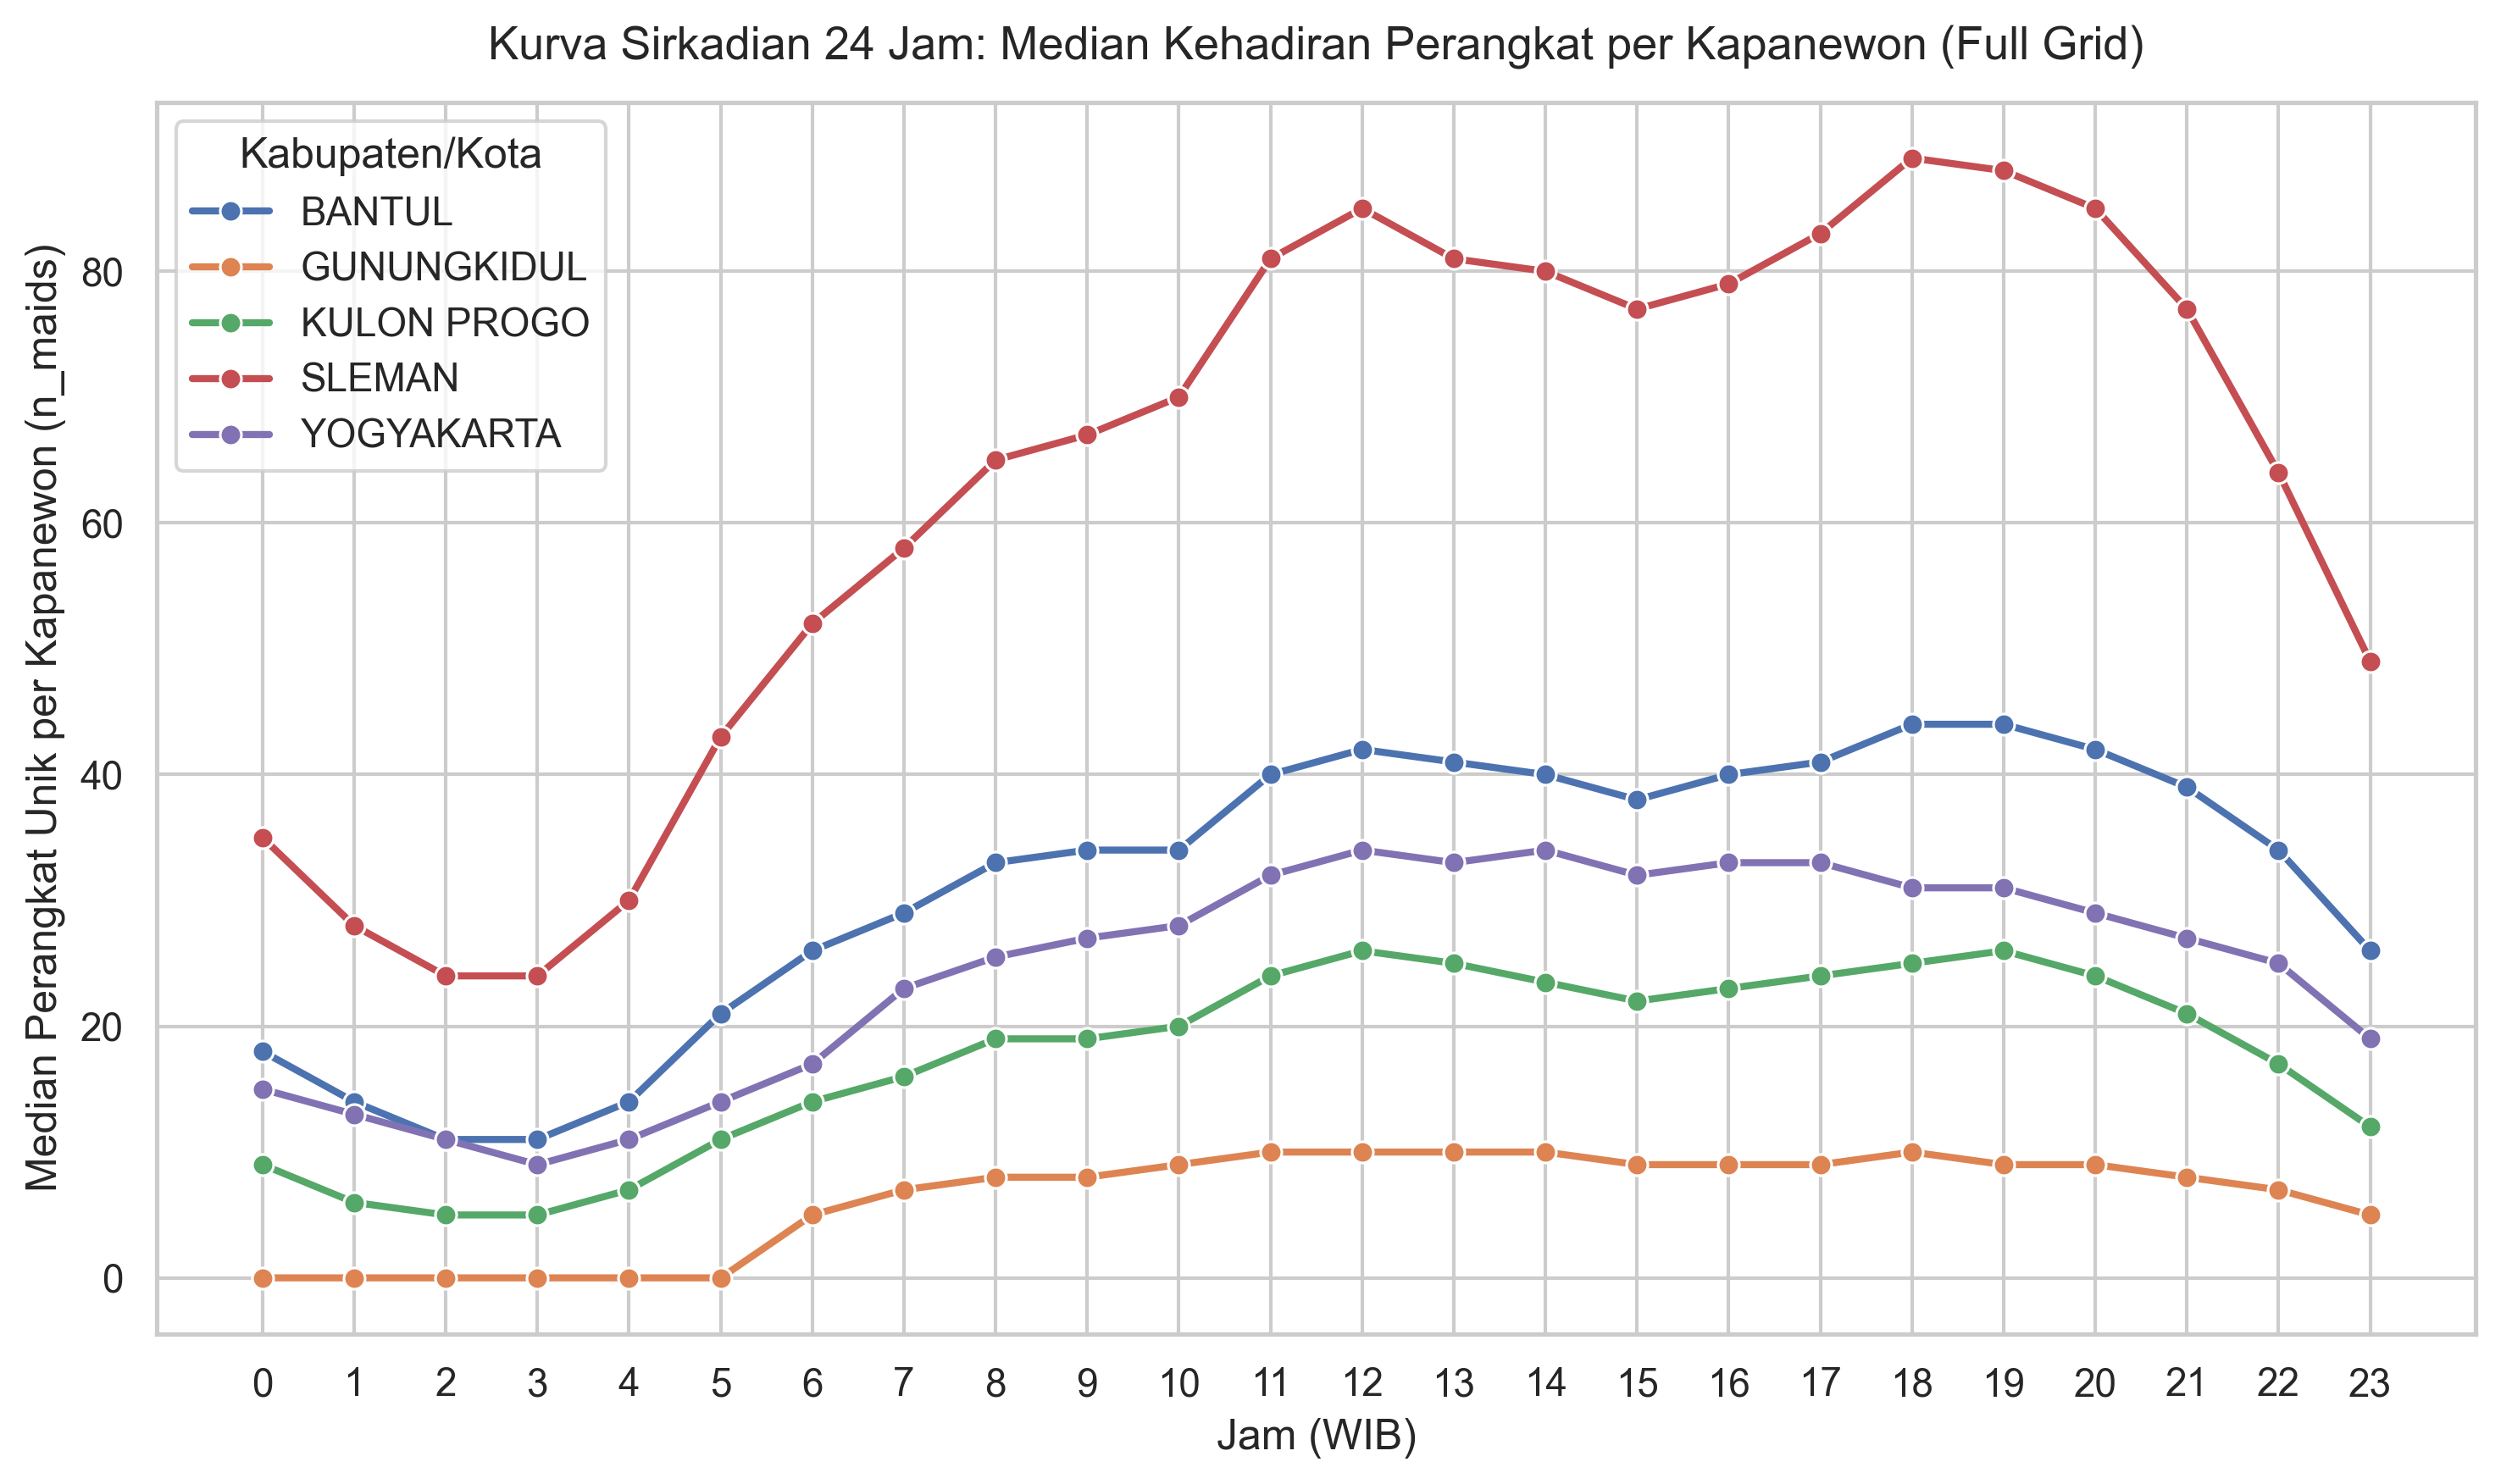

In [3]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.lineplot(
    data=circadian_stats,
    x="hour",
    y="median_maids",
    hue="kab_kota",
    marker="o",
    linewidth=2,
    ax=ax,
)
ax.set_title("Kurva Sirkadian 24 Jam: Median Kehadiran Perangkat per Kapanewon (Full Grid)", fontsize=13, pad=12)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Median Perangkat Unik per Kapanewon (n_maids)")
ax.set_xticks(range(0, 24))
ax.legend(title="Kabupaten/Kota", frameon=True)
plt.tight_layout()
plt.savefig("figures/01a_kurva_sirkadian_24jam.png", dpi=300, bbox_inches="tight")
plt.show()

   kab_kota  rasio_siang_malam
GUNUNGKIDUL           4.034861
KULON PROGO           3.283906
     BANTUL           2.576798
     SLEMAN           2.403056
 YOGYAKARTA           1.800091


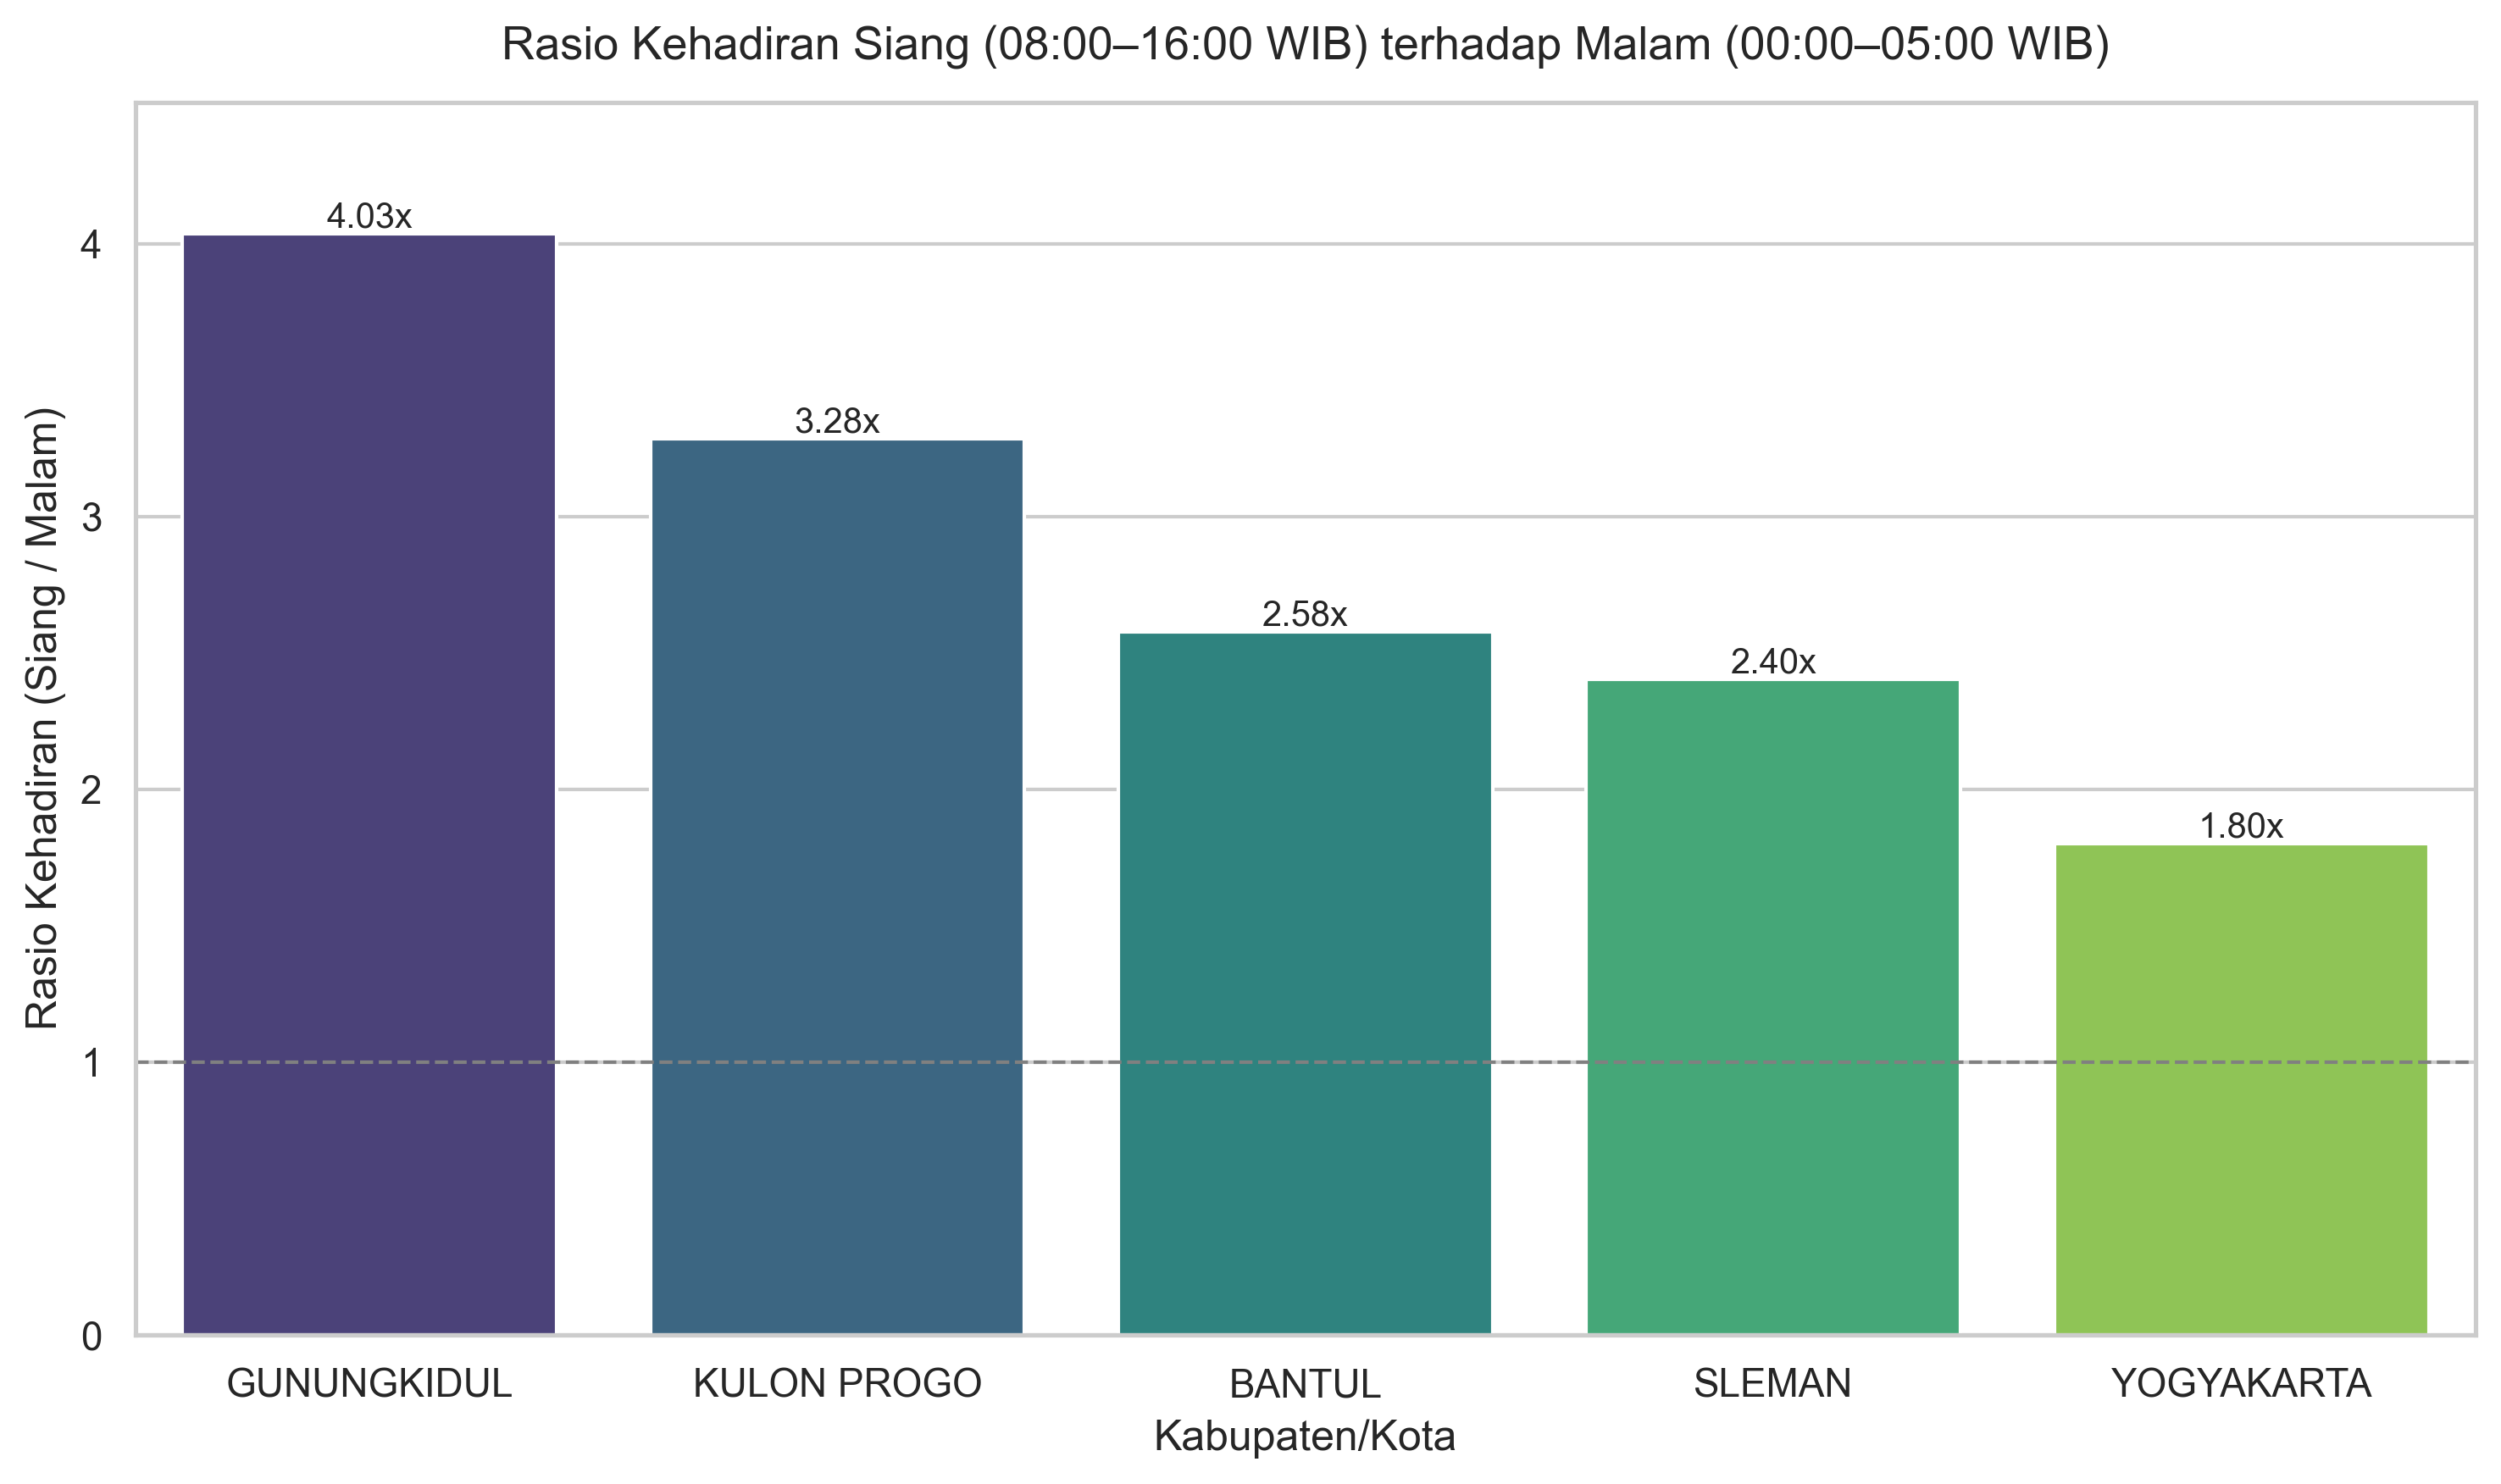

In [4]:
day_mask = kab_hourly["hour"].between(8, 16)
night_mask = kab_hourly["hour"].between(0, 5)

day_mean = kab_hourly[day_mask].groupby("kab_kota")["total_kab_maids"].mean()
night_mean = kab_hourly[night_mask].groupby("kab_kota")["total_kab_maids"].mean()
day_night_ratio = (
    (day_mean / night_mean)
    .sort_values(ascending=False)
    .reset_index(name="rasio_siang_malam")
)
print(day_night_ratio.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.barplot(
    data=day_night_ratio,
    x="kab_kota",
    y="rasio_siang_malam",
    hue="kab_kota",
    palette="viridis",
    legend=False,
    ax=ax,
)
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}x",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
    )
ax.set_title("Rasio Kehadiran Siang (08:00–16:00 WIB) terhadap Malam (00:00–05:00 WIB)", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota")
ax.set_ylabel("Rasio Kehadiran (Siang / Malam)")
ax.set_ylim(0, day_night_ratio["rasio_siang_malam"].max() * 1.12)
plt.tight_layout()
plt.savefig("figures/01b_rasio_siang_malam.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 1:**
- Dengan menggunakan **median pada grid lengkap**, ritme sirkadian 5 Kabupaten/Kota menurun secara konsisten menuju titik terendah pada dini hari (`02:00–04:00 WIB`) tanpa distorsi lonjakan palsu pukul `01:00 WIB` di Kota Yogyakarta (yang berasal dari artefak *centroid* di Kemantren Gondomanan), lalu meningkat tajam mulai `05:00 WIB` menuju dataran tinggi aktivitas siang–sore (`11:00–19:00 WIB`).
- Setelah menghilangkan *survivorship bias* jam malam, **Gunungkidul** tercatat memiliki rasio siang/malam paling tajam (**4,03x**), disusul **Kulon Progo (3,28x)**, **Bantul (2,58x)**, **Sleman (2,40x)**, dan **Kota Yogyakarta (1,80x)** yang lebih stabil siang-malam sebagai pusat permukiman dan aktivitas perkotaan.

## Bagian 2: Komparasi Hari Kerja (Weekday) vs Akhir Pekan (Weekend)

Mengelompokkan tanggal menjadi Hari Kerja (Senin–Jumat) dan Akhir Pekan (Sabtu–Minggu) untuk mengidentifikasi 15 kapanewon terpadat (menggunakan `kapanewon_label` yang terdisambiguasi) serta memetakan pola aktivitas mingguan dalam matriks 7 hari × 24 jam.

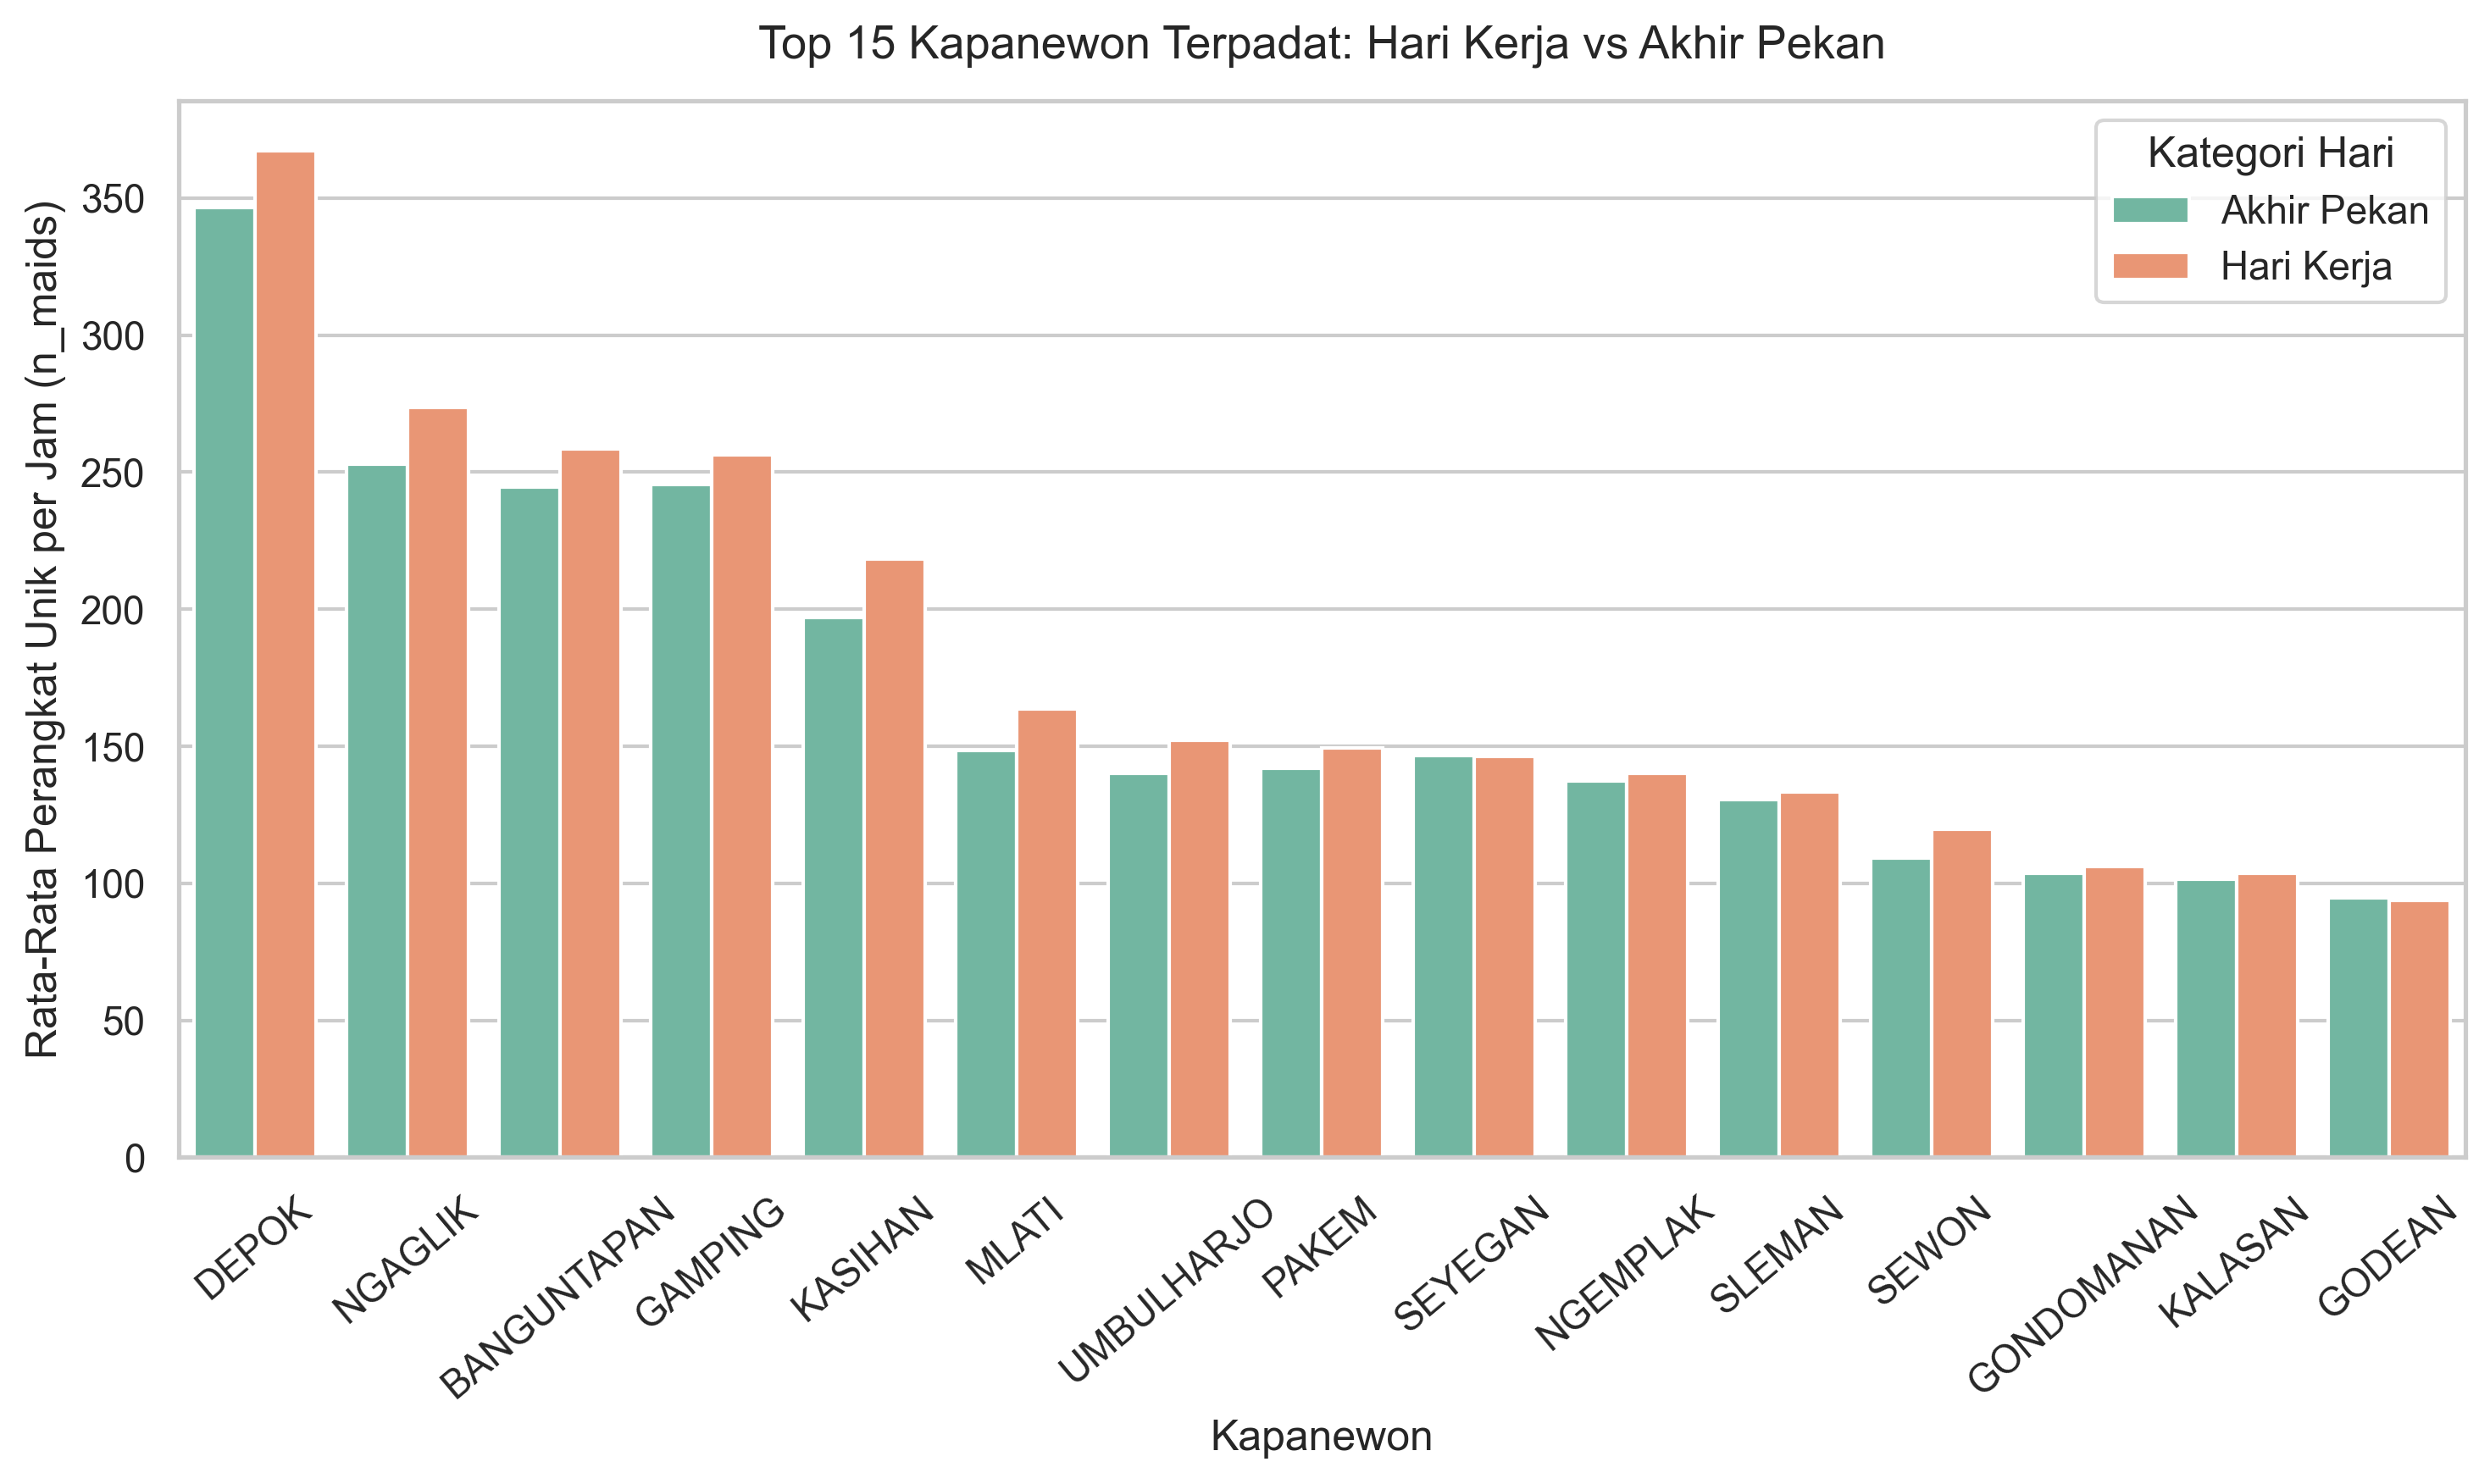

In [5]:
df_presence["dayofweek"] = df_presence["date"].dt.dayofweek
day_map = {
    0: "Senin",
    1: "Selasa",
    2: "Rabu",
    3: "Kamis",
    4: "Jumat",
    5: "Sabtu",
    6: "Minggu",
}
day_order = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
df_presence["nama_hari"] = df_presence["dayofweek"].map(day_map)
df_presence["tipe_hari"] = np.where(df_presence["dayofweek"] < 5, "Hari Kerja", "Akhir Pekan")

kapanewon_daytype = (
    df_presence.groupby(["kapanewon_label", "tipe_hari"])["n_maids"]
    .mean()
    .reset_index()
)
order_top15 = (
    df_presence.groupby("kapanewon_label")["n_maids"]
    .mean()
    .nlargest(15)
    .index
)
top15_df = kapanewon_daytype[kapanewon_daytype["kapanewon_label"].isin(order_top15)].copy()

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.barplot(
    data=top15_df,
    x="kapanewon_label",
    y="n_maids",
    hue="tipe_hari",
    order=order_top15,
    palette="Set2",
    ax=ax,
)
ax.set_title("Top 15 Kapanewon Terpadat: Hari Kerja vs Akhir Pekan", fontsize=13, pad=12)
ax.set_xlabel("Kapanewon")
ax.set_ylabel("Rata-Rata Perangkat Unik per Jam (n_maids)")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="Kategori Hari", frameon=True)
plt.tight_layout()
plt.savefig("figures/02a_top15_kapanewon_weekday_weekend.png", dpi=300, bbox_inches="tight")
plt.show()

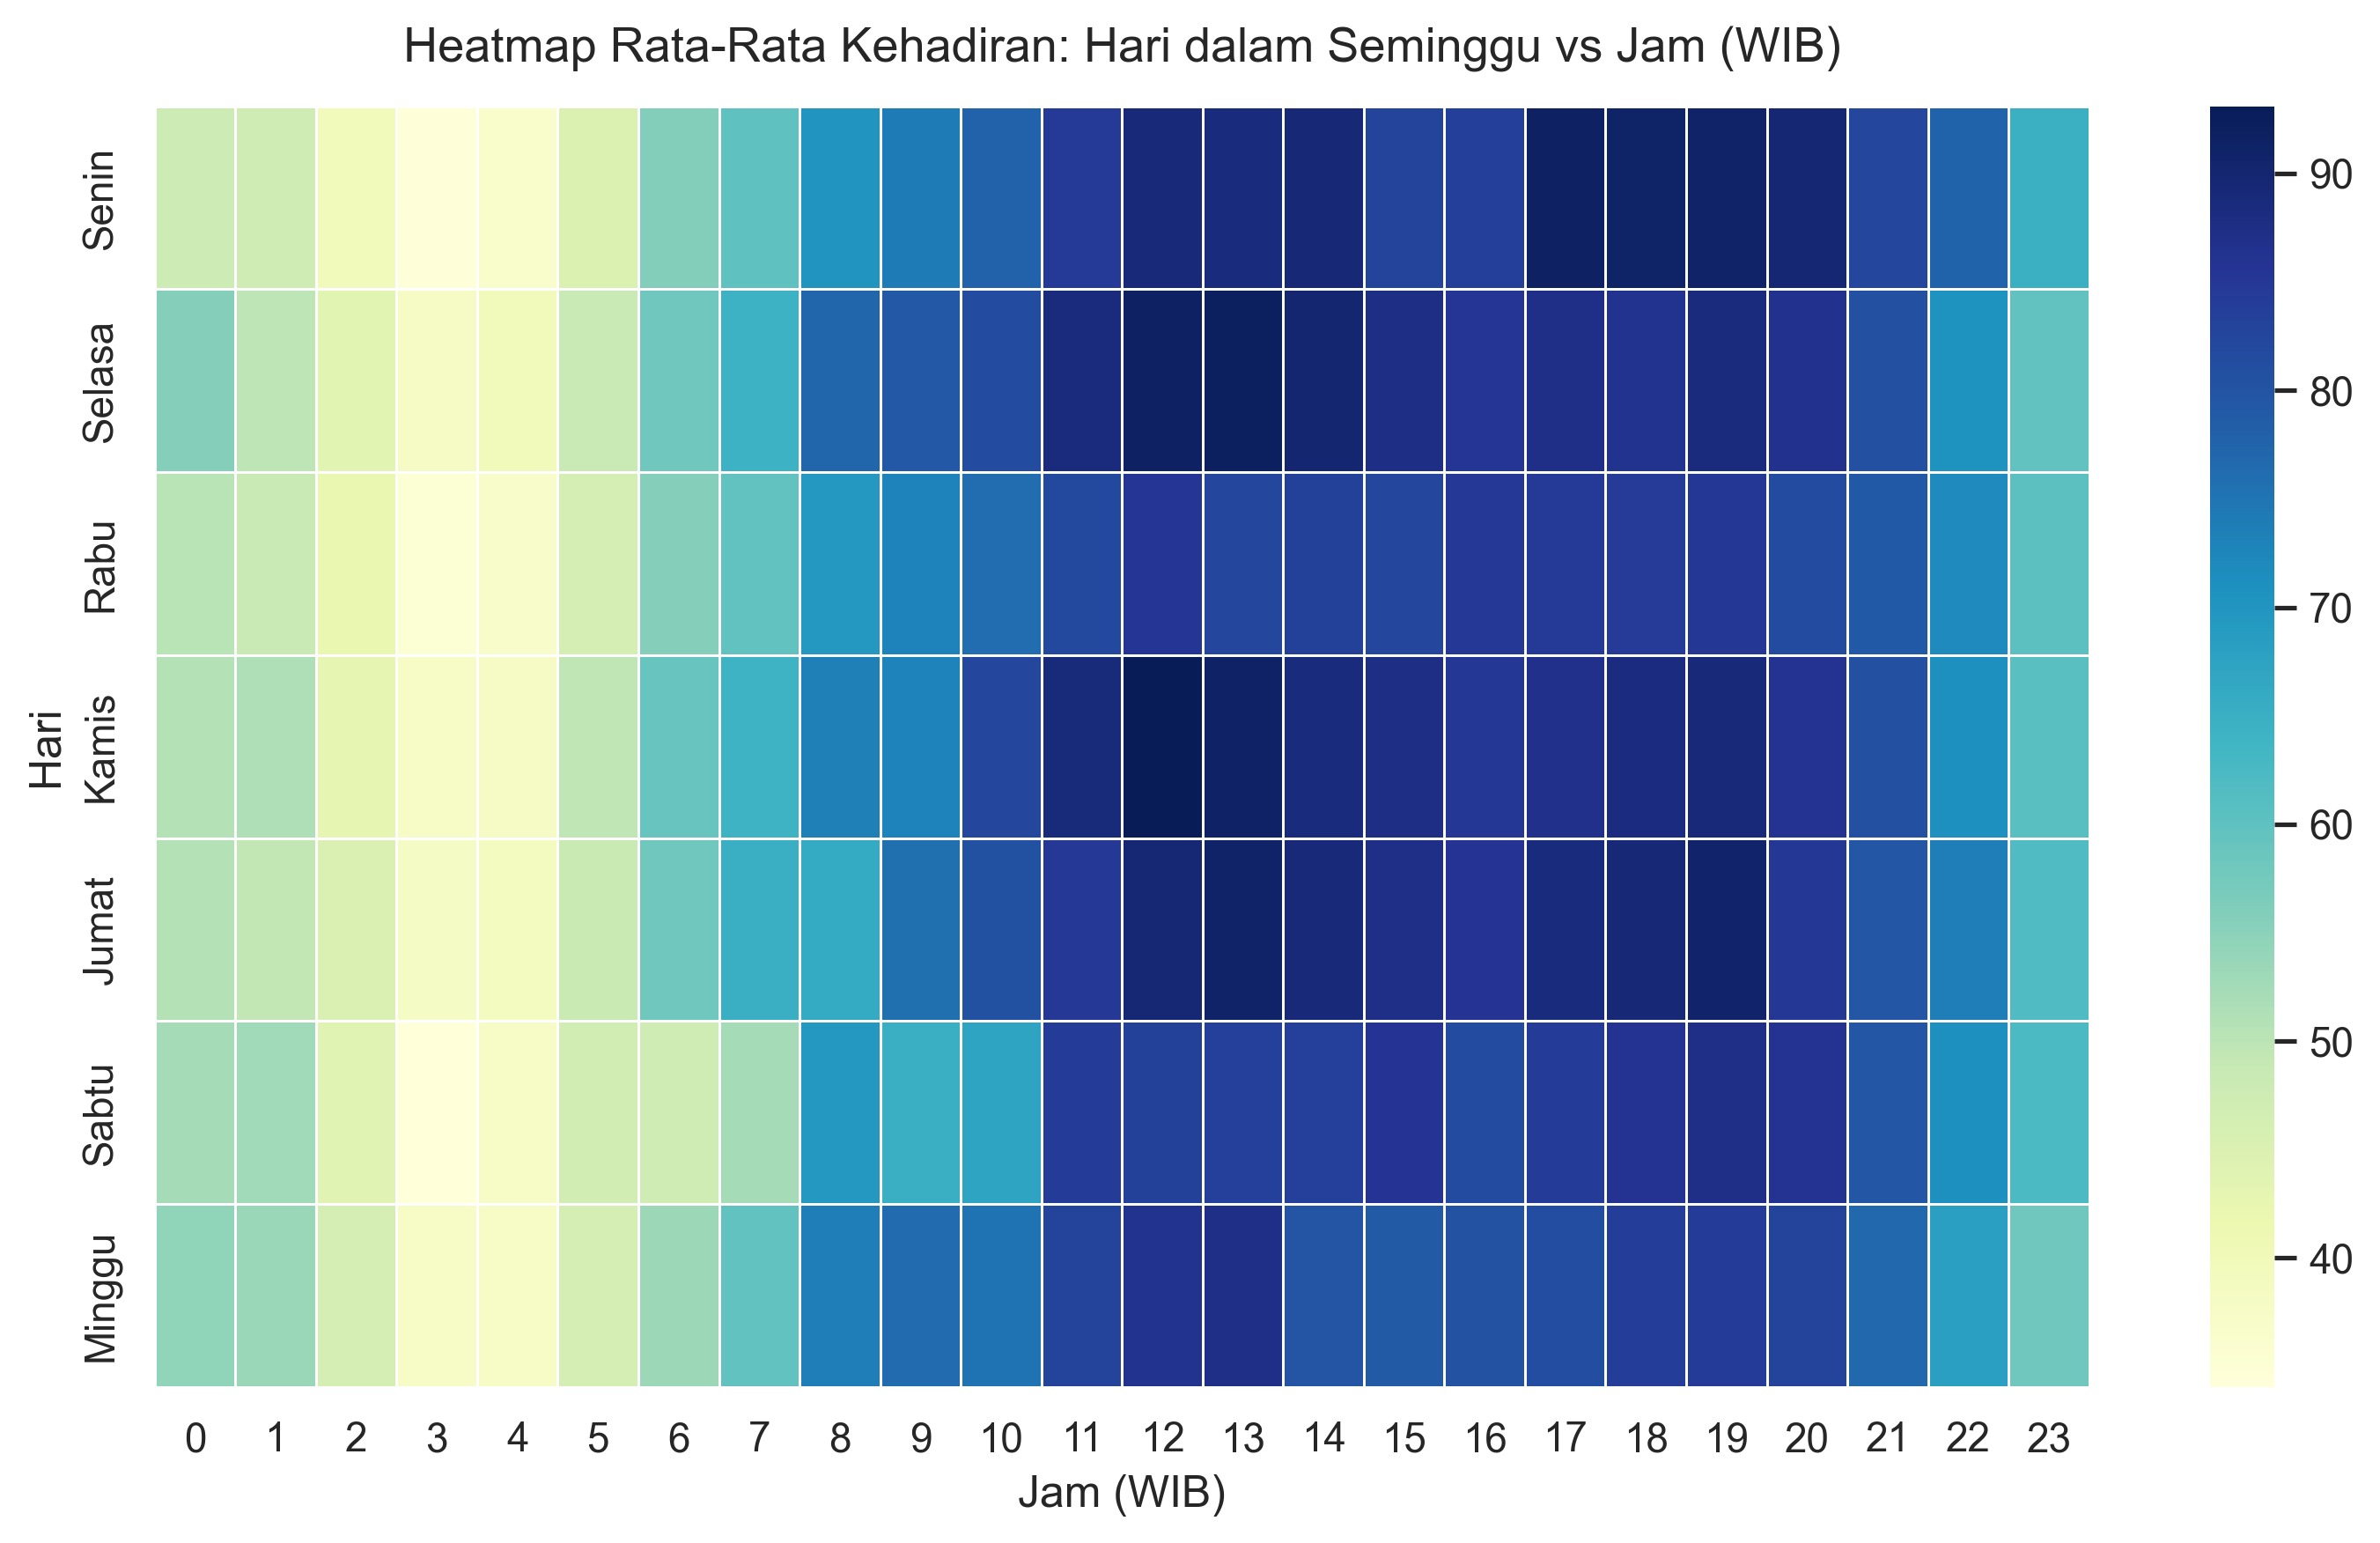

In [6]:
heatmap_day_hour = (
    df_presence.groupby(["nama_hari", "hour"])["n_maids"]
    .mean()
    .unstack(level="hour")
    .reindex(day_order)
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.heatmap(heatmap_day_hour, cmap="YlGnBu", linewidths=0.3, ax=ax)
ax.set_title("Heatmap Rata-Rata Kehadiran: Hari dalam Seminggu vs Jam (WIB)", fontsize=13, pad=12)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Hari")
plt.tight_layout()
plt.savefig("figures/02b_heatmap_hari_vs_jam.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 2:**
- **Depok (Sleman)** jauh melampaui kapanewon lainnya (~367 perangkat/jam pada hari kerja dan ~346 pada akhir pekan), diikuti oleh kawasan penyangga aglomerasi perkotaan seperti Ngaglik, Banguntapan, Gamping, Kasihan, dan Mlati.
- Sebagian besar kapanewon pusat pendidikan dan perkantoran (Depok, Ngaglik, Kasihan, Mlati, Umbulharjo) mencatat kepadatan lebih tinggi pada **Hari Kerja**, sedangkan beberapa kapanewon pinggiran/semi-suburban (seperti Seyegan dan Godean) relatif seimbang antara hari kerja dan akhir pekan.

## Bagian 3: Tren Longitudinal 151 Hari, Libur Tahun Baru, & Pergeseran Ramadhan

Mengagregasi total kehadiran perangkat-jam harian selama 151 hari (1 Desember 2021 – 30 April 2022) dengan menandai titik awal penurunan sampel data (`16 Februari 2022`), lalu membandingkan **proporsi aktivitas per jam (%)** antara periode **Normal (Desember 2021 – Februari 2022)** dan **Ramadhan 1443 H (April 2022)** agar pergeseran jam aktif tidak tertutupi oleh penurunan volume sampel.

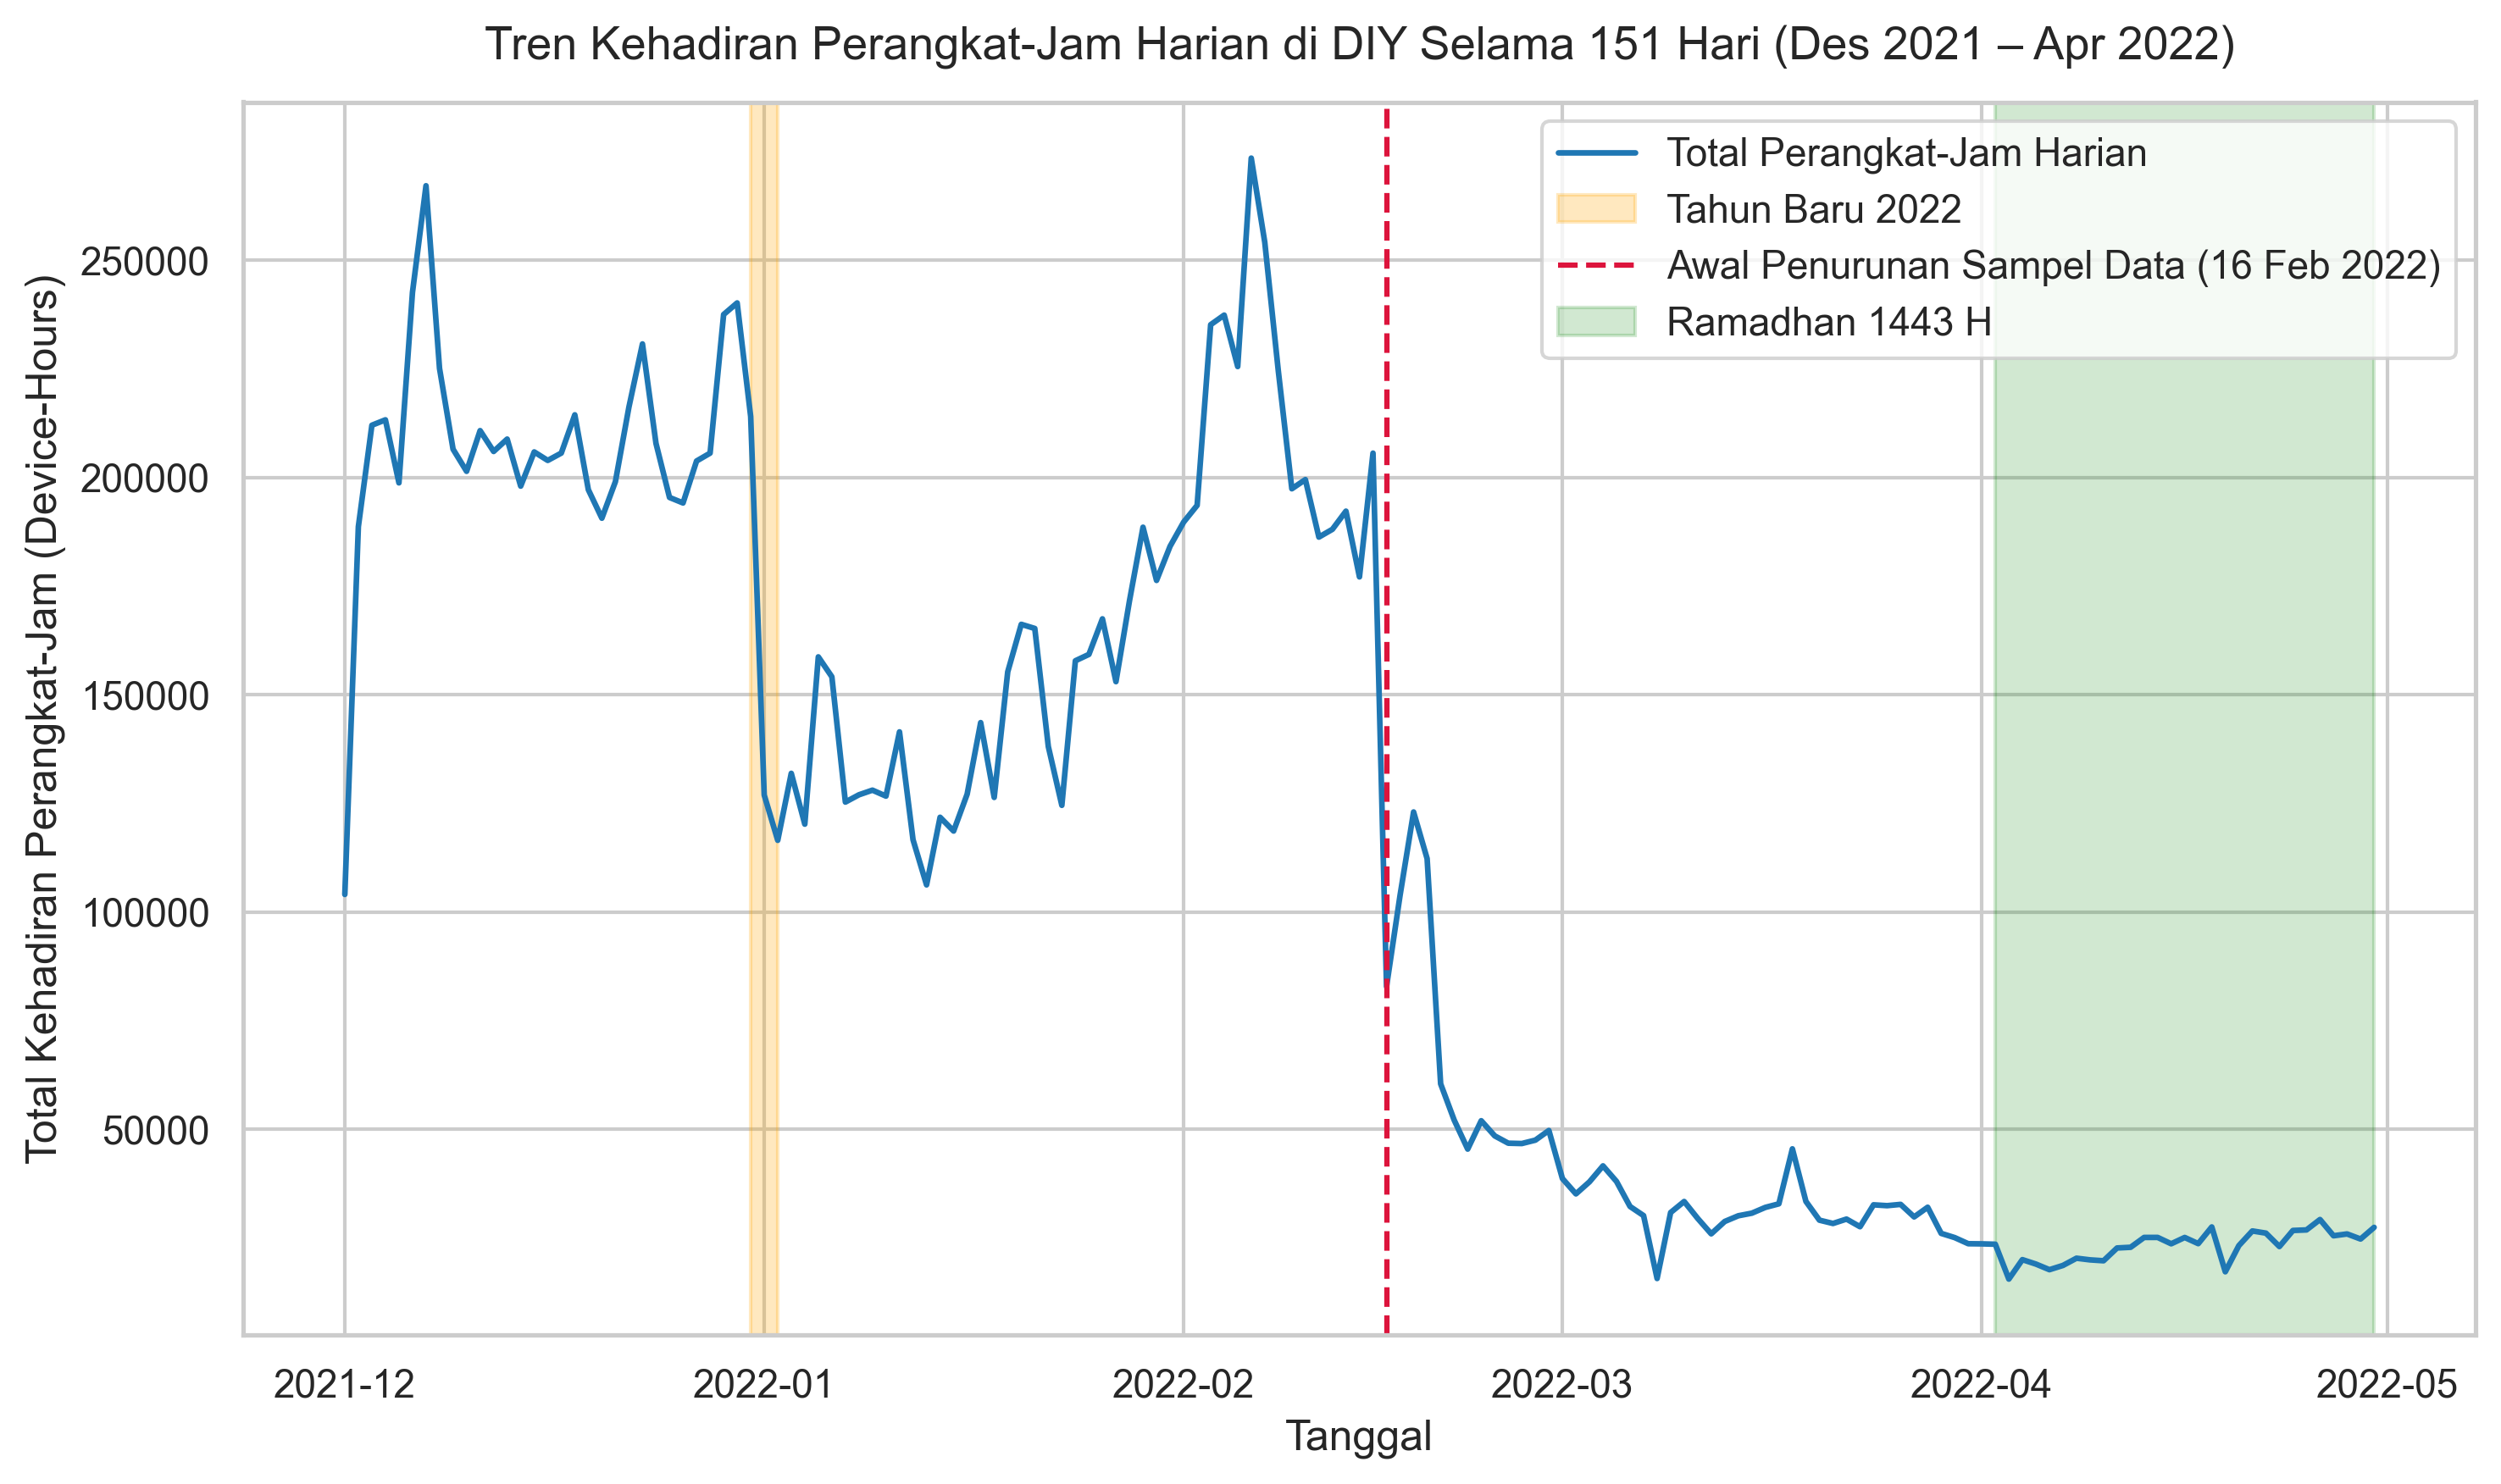

In [7]:
daily_trend = df_presence.groupby("date")["n_maids"].sum().reset_index()

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.plot(daily_trend["date"], daily_trend["n_maids"], color="#1f77b4", linewidth=1.6, label="Total Perangkat-Jam Harian")
ax.axvspan(pd.Timestamp("2021-12-31"), pd.Timestamp("2022-01-02"), color="orange", alpha=0.25, label="Tahun Baru 2022")
ax.axvline(pd.Timestamp("2022-02-16"), color="crimson", linestyle="--", linewidth=1.5, label="Awal Penurunan Sampel Data (16 Feb 2022)")
ax.axvspan(pd.Timestamp("2022-04-02"), pd.Timestamp("2022-04-30"), color="green", alpha=0.18, label="Ramadhan 1443 H")
ax.set_title("Tren Kehadiran Perangkat-Jam Harian di DIY Selama 151 Hari (Des 2021 – Apr 2022)", fontsize=13, pad=12)
ax.set_xlabel("Tanggal")
ax.set_ylabel("Total Kehadiran Perangkat-Jam (Device-Hours)")
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig("figures/03a_tren_harian_151hari.png", dpi=300, bbox_inches="tight")
plt.show()

Perbandingan Proporsi Aktivitas Harian (%) pada Jam Kunci:
periode  Normal (Des 2021 – Feb 2022)  Ramadhan (Apr 2022)
hour                                                      
2                                1.71                 2.32
3                                1.44                 3.48
4                                1.67                 3.98
5                                2.47                 3.05
12                               5.64                 5.22
17                               5.46                 4.77
18                               5.59                 5.54
19                               5.62                 4.80
20                               5.48                 5.38


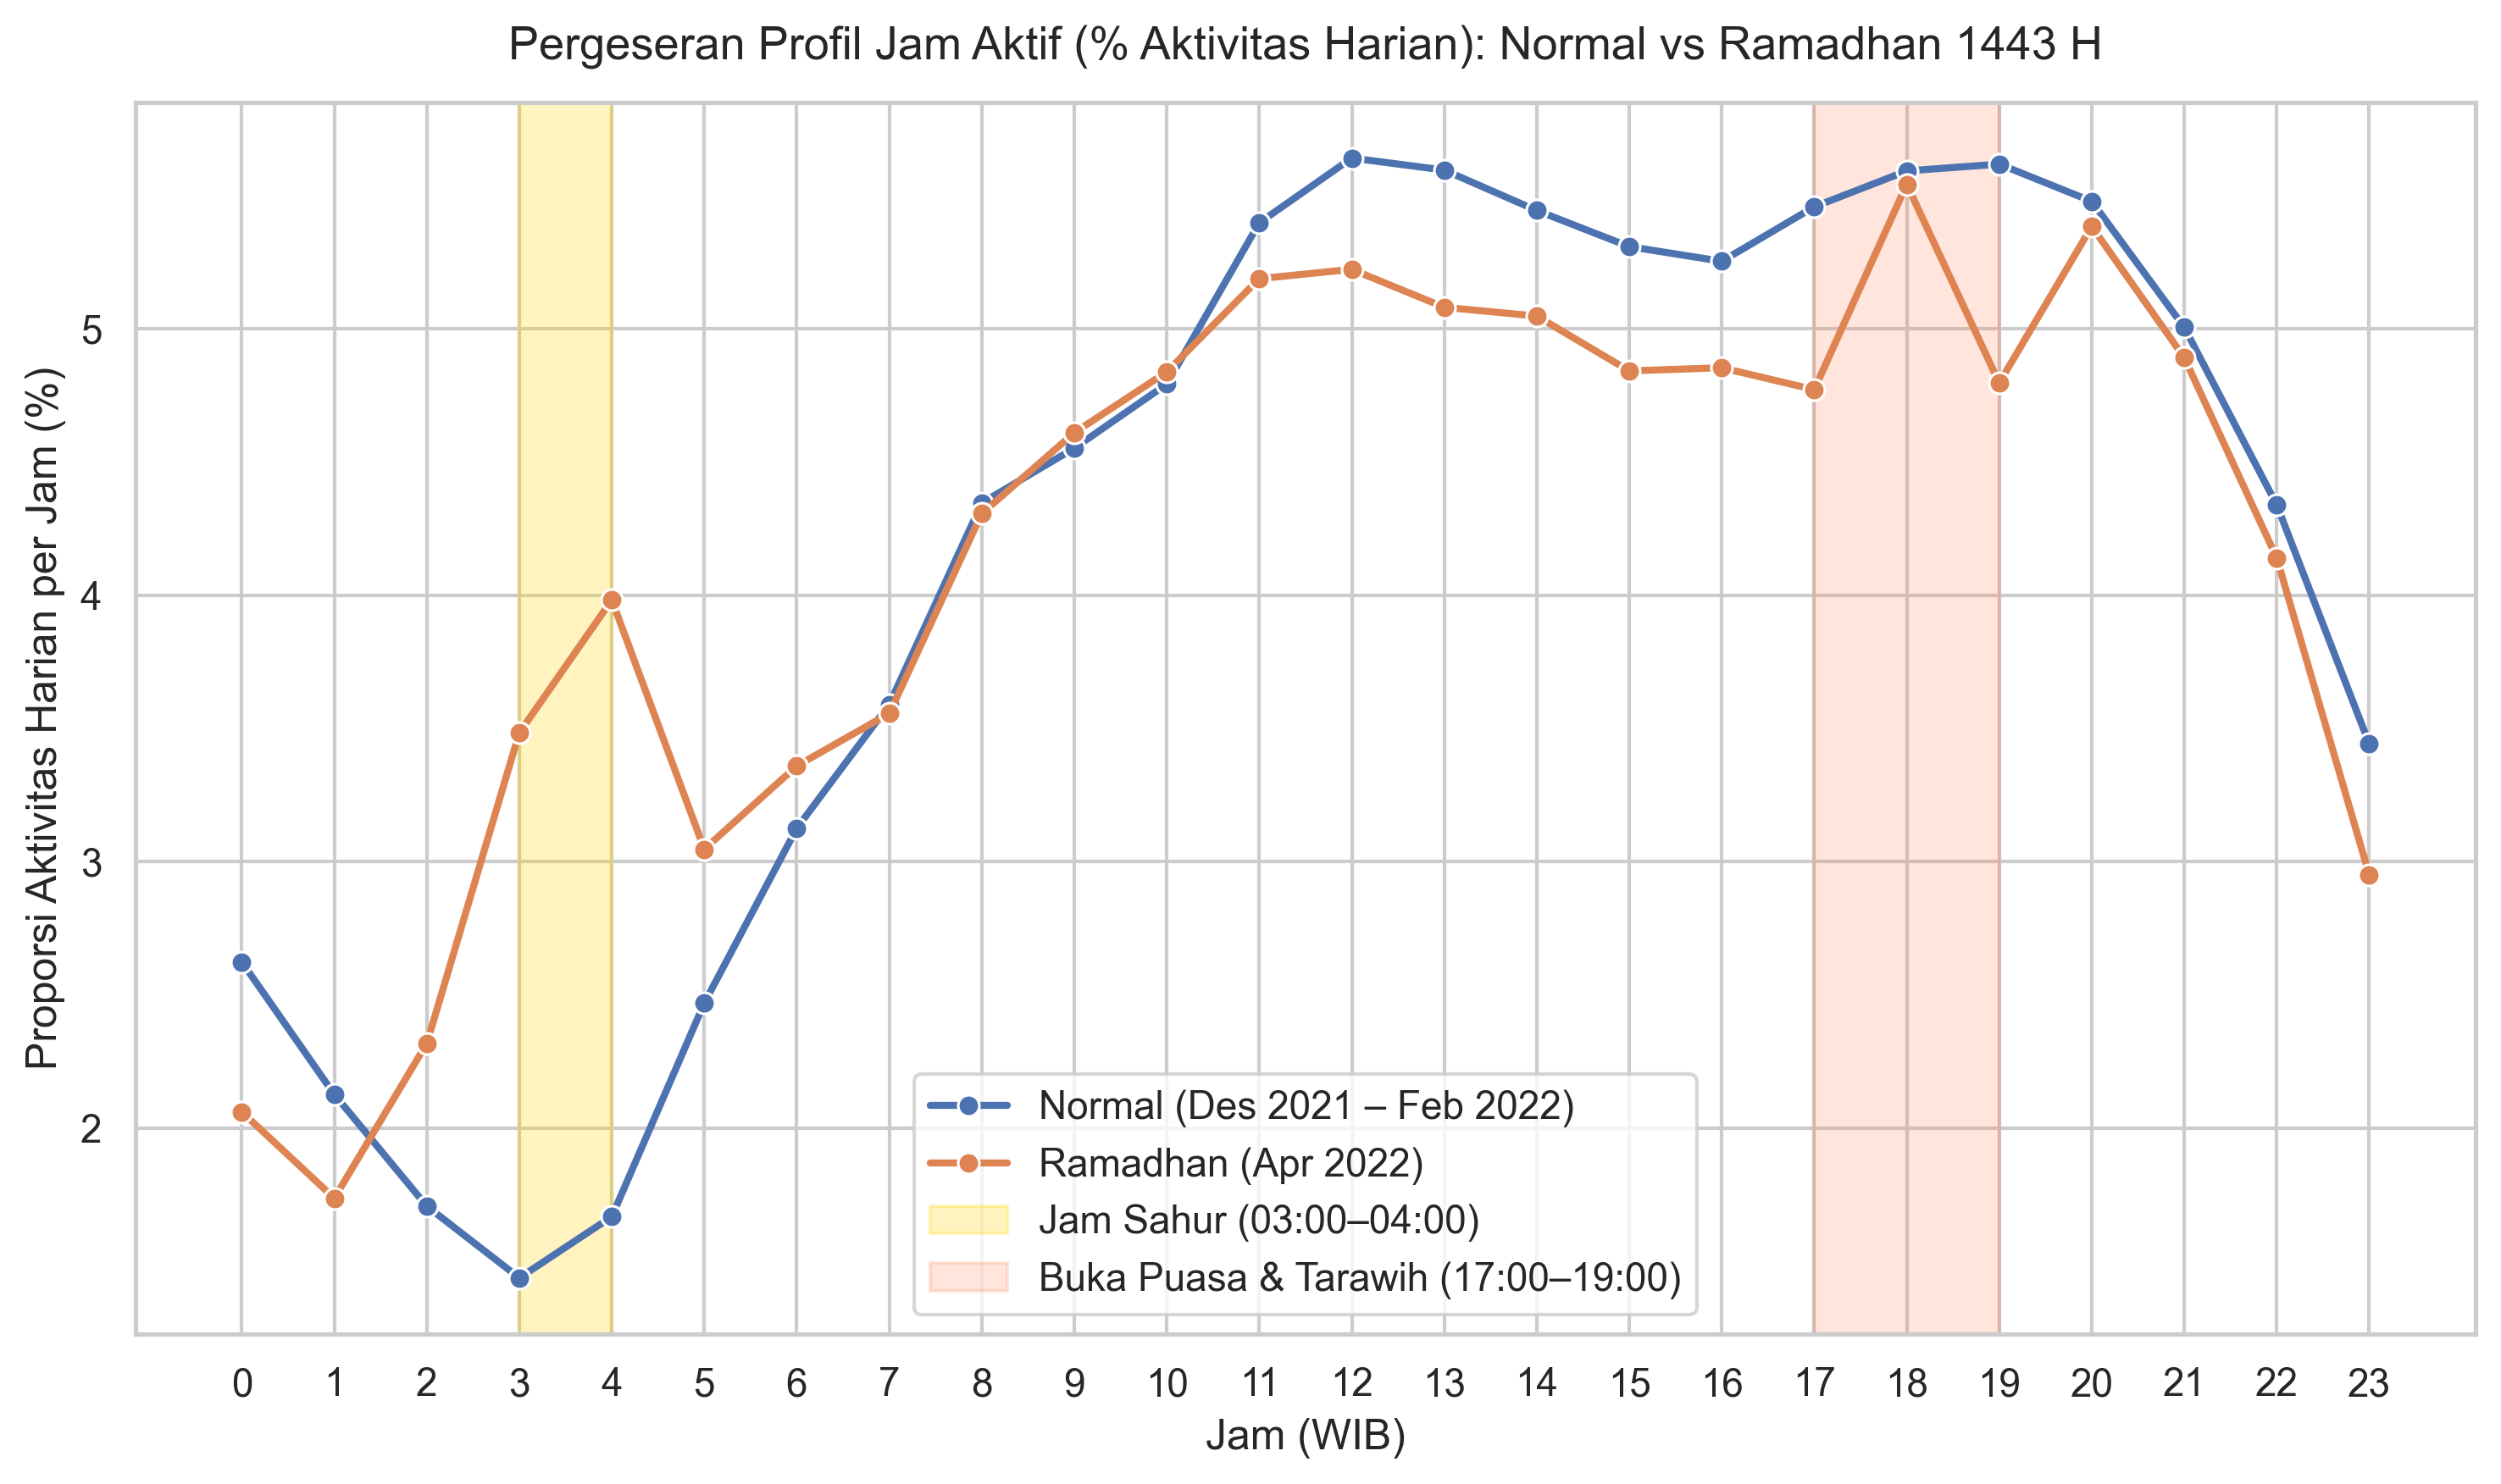

In [8]:
# Pisahkan secara tegas periode Normal (Des 2021 - Feb 2022) vs Ramadhan (Apr 2022),
# mengeluarkan Maret 2022 yang merupakan periode transisi reduced_quality pra-Ramadhan.
df_ramadhan_comp = df_presence[
    (df_presence["date"] < pd.Timestamp("2022-03-01"))
    | (df_presence["date"] >= pd.Timestamp("2022-04-01"))
].copy()

df_ramadhan_comp["periode"] = np.where(
    df_ramadhan_comp["date"] >= pd.Timestamp("2022-04-01"),
    "Ramadhan (Apr 2022)",
    "Normal (Des 2021 – Feb 2022)",
)

ramadhan_hourly = (
    df_ramadhan_comp.groupby(["periode", "hour"])["n_maids"]
    .sum()
    .reset_index()
)
ramadhan_hourly["proporsi_jam_pct"] = (
    ramadhan_hourly["n_maids"]
    / ramadhan_hourly.groupby("periode")["n_maids"].transform("sum")
    * 100
)

print("Perbandingan Proporsi Aktivitas Harian (%) pada Jam Kunci:")
piv_ram = ramadhan_hourly.pivot(index="hour", columns="periode", values="proporsi_jam_pct").round(2)
print(piv_ram.loc[[2, 3, 4, 5, 12, 17, 18, 19, 20]])

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.lineplot(
    data=ramadhan_hourly,
    x="hour",
    y="proporsi_jam_pct",
    hue="periode",
    marker="o",
    linewidth=2,
    ax=ax,
)
ax.axvspan(3, 4, color="gold", alpha=0.25, label="Jam Sahur (03:00–04:00)")
ax.axvspan(17, 19, color="coral", alpha=0.2, label="Buka Puasa & Tarawih (17:00–19:00)")
ax.set_title("Pergeseran Profil Jam Aktif (% Aktivitas Harian): Normal vs Ramadhan 1443 H", fontsize=13, pad=12)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Proporsi Aktivitas Harian per Jam (%)")
ax.set_xticks(range(0, 24))
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig("figures/03b_pergeseran_jam_ramadhan.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 3:**
- Penurunan tajam volume *device-hours* pada **16 Februari 2022** hingga **Maret–April 2022** (~80–85% lebih rendah dibanding Des 2021–Feb 2022) adalah **artefak penyusutan cakupan sampel data** (sejalan dengan penanda `reduced_quality`), bukan penurunan mobilitas masyarakat secara riil.
- Setelah dinormalisasi ke **proporsi aktivitas harian per jam (%)**, pergeseran perilaku Ramadhan terlihat sangat jelas:
  - **Jam Sahur (`03:00–04:00 WIB`):** Pangsa aktivitas melonjak hampir 3 kali lipat, dari **1,44% (`03:00`) dan 1,67% (`04:00`)** pada periode normal menjadi **3,48% (`03:00`) dan 3,98% (`04:00`)** saat Ramadhan.
  - **Jelang Berbuka & Sholat Tarawih (`17:00–20:00 WIB`):** Aktivitas relatif melandai pada pukul **17:00 WIB (4,77%)**, meningkat singkat pada **18:00 WIB (5,54%)**, kembali turun saat jam Tarawih pukul **19:00 WIB (4,80%)**, dan naik lagi pada **20:00 WIB (5,38%)**.

## Bagian 4: Analisis Intensitas Aktivitas Sinyal (Rasio Pings per Perangkat)

Menghitung metrik `pings_per_maid = n_pings / n_maids` beserta **rata-rata tertimbang (`weighted_pings_per_maid = sum(n_pings) / sum(n_maids)`)** untuk menghindari bias bobot yang sama antara baris bersampel kecil dan baris padat perangkat, serta memetakan korelasi tingkat kapanewon pada **78 titik wilayah**.

In [9]:
df_presence["pings_per_maid"] = np.where(
    df_presence["n_maids"] > 0,
    df_presence["n_pings"] / df_presence["n_maids"],
    np.nan,
)

ping_summary = (
    df_presence.groupby("kab_kota")
    .agg(
        mean_maids=("n_maids", "mean"),
        mean_pings=("n_pings", "mean"),
        mean_pings_per_maid=("pings_per_maid", "mean"),
        median_pings_per_maid=("pings_per_maid", "median"),
        total_maids=("n_maids", "sum"),
        total_pings=("n_pings", "sum"),
    )
)
ping_summary["weighted_pings_per_maid"] = (
    ping_summary["total_pings"] / ping_summary["total_maids"]
)
ping_summary = ping_summary[
    ["mean_maids", "mean_pings", "mean_pings_per_maid", "median_pings_per_maid", "weighted_pings_per_maid"]
].round(2)
ping_summary

,mean_maids,mean_pings,mean_pings_per_maid,median_pings_per_maid,weighted_pings_per_maid
kab_kota,,,,,
BANTUL,78.83,191.01,2.50,2.33,2.42
GUNUNGKIDUL,24.53,63.21,2.63,2.33,2.58
KULON PROGO,36.46,98.56,2.62,2.40,2.70
SLEMAN,132.99,363.44,2.64,2.45,2.73
YOGYAKARTA,53.34,151.62,2.65,2.41,2.84


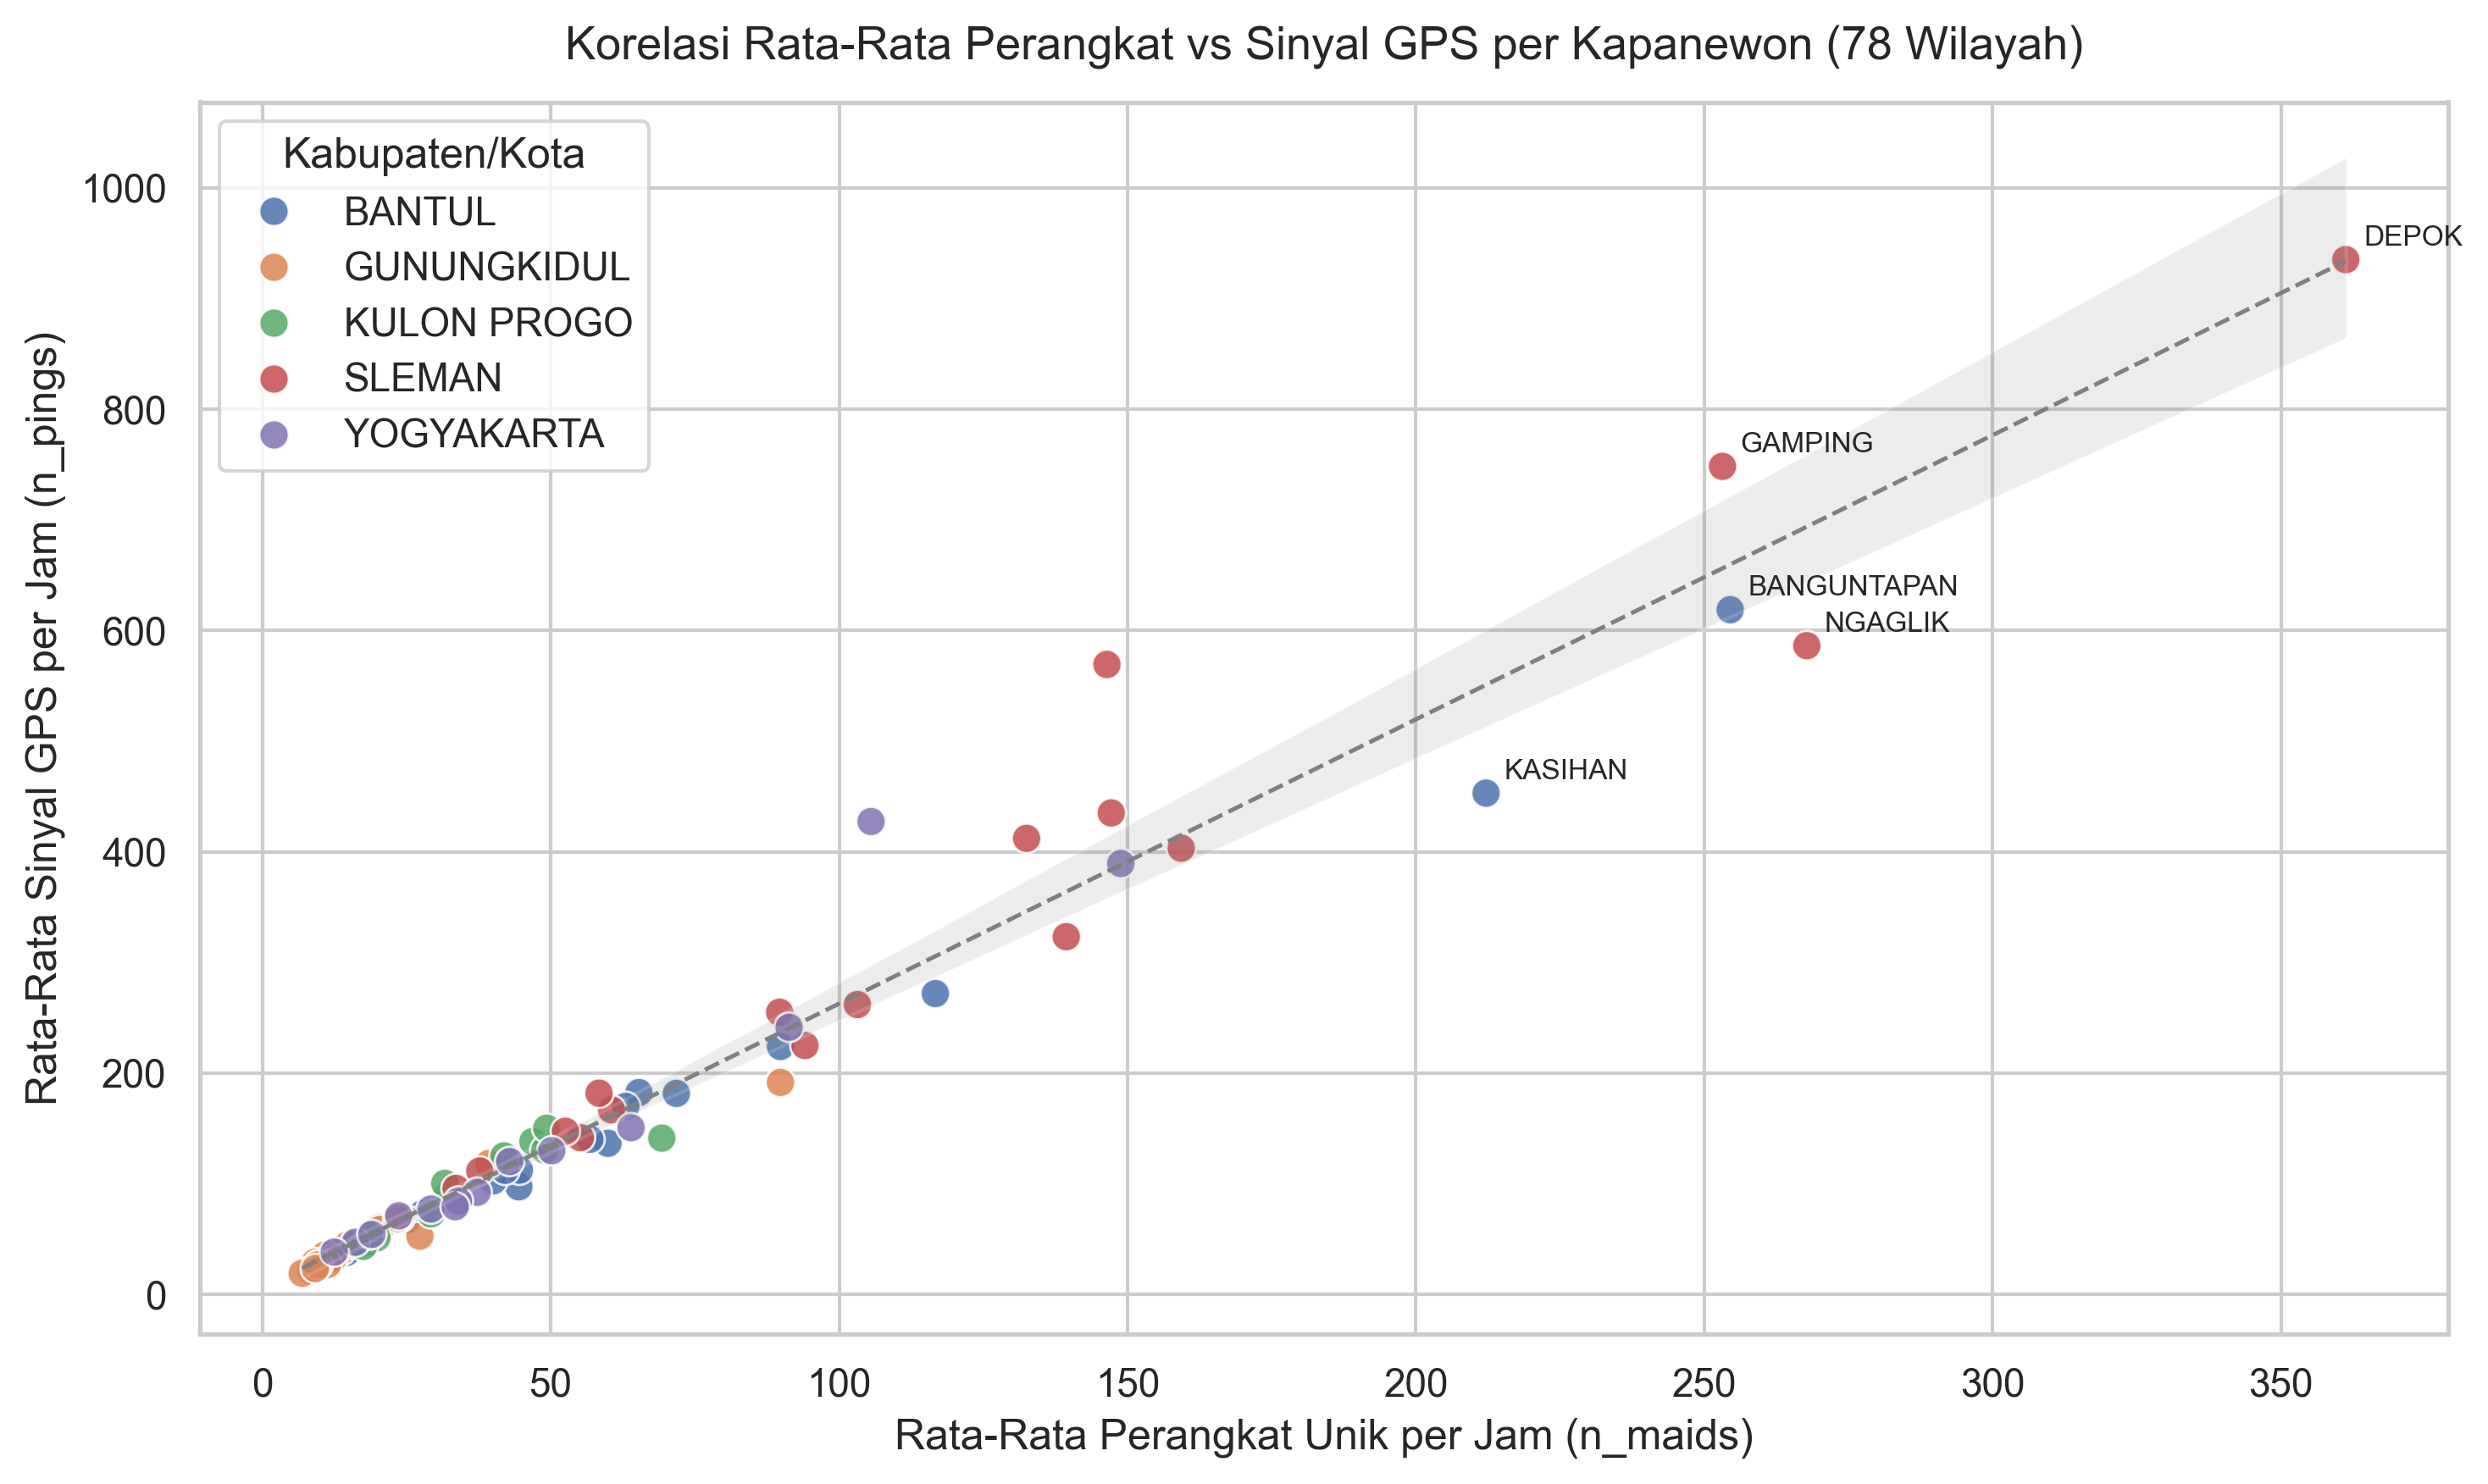

In [10]:
kapanewon_agg = (
    df_presence.groupby(["kab_kota", "kapanewon_code", "kapanewon_label"])[["n_maids", "n_pings"]]
    .mean()
    .reset_index()
)
assert len(kapanewon_agg) == 78

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.scatterplot(
    data=kapanewon_agg,
    x="n_maids",
    y="n_pings",
    hue="kab_kota",
    s=70,
    alpha=0.85,
    ax=ax,
)
sns.regplot(
    data=kapanewon_agg,
    x="n_maids",
    y="n_pings",
    scatter=False,
    color="gray",
    line_kws={"linestyle": "--", "linewidth": 1.2},
    ax=ax,
)

for _, row in kapanewon_agg.nlargest(5, "n_maids").iterrows():
    ax.annotate(
        row["kapanewon_label"],
        (row["n_maids"], row["n_pings"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_title("Korelasi Rata-Rata Perangkat vs Sinyal GPS per Kapanewon (78 Wilayah)", fontsize=13, pad=12)
ax.set_xlabel("Rata-Rata Perangkat Unik per Jam (n_maids)")
ax.set_ylabel("Rata-Rata Sinyal GPS per Jam (n_pings)")
ax.legend(title="Kabupaten/Kota", frameon=True)
plt.tight_layout()
plt.savefig("figures/04a_scatter_maids_vs_pings.png", dpi=300, bbox_inches="tight")
plt.show()

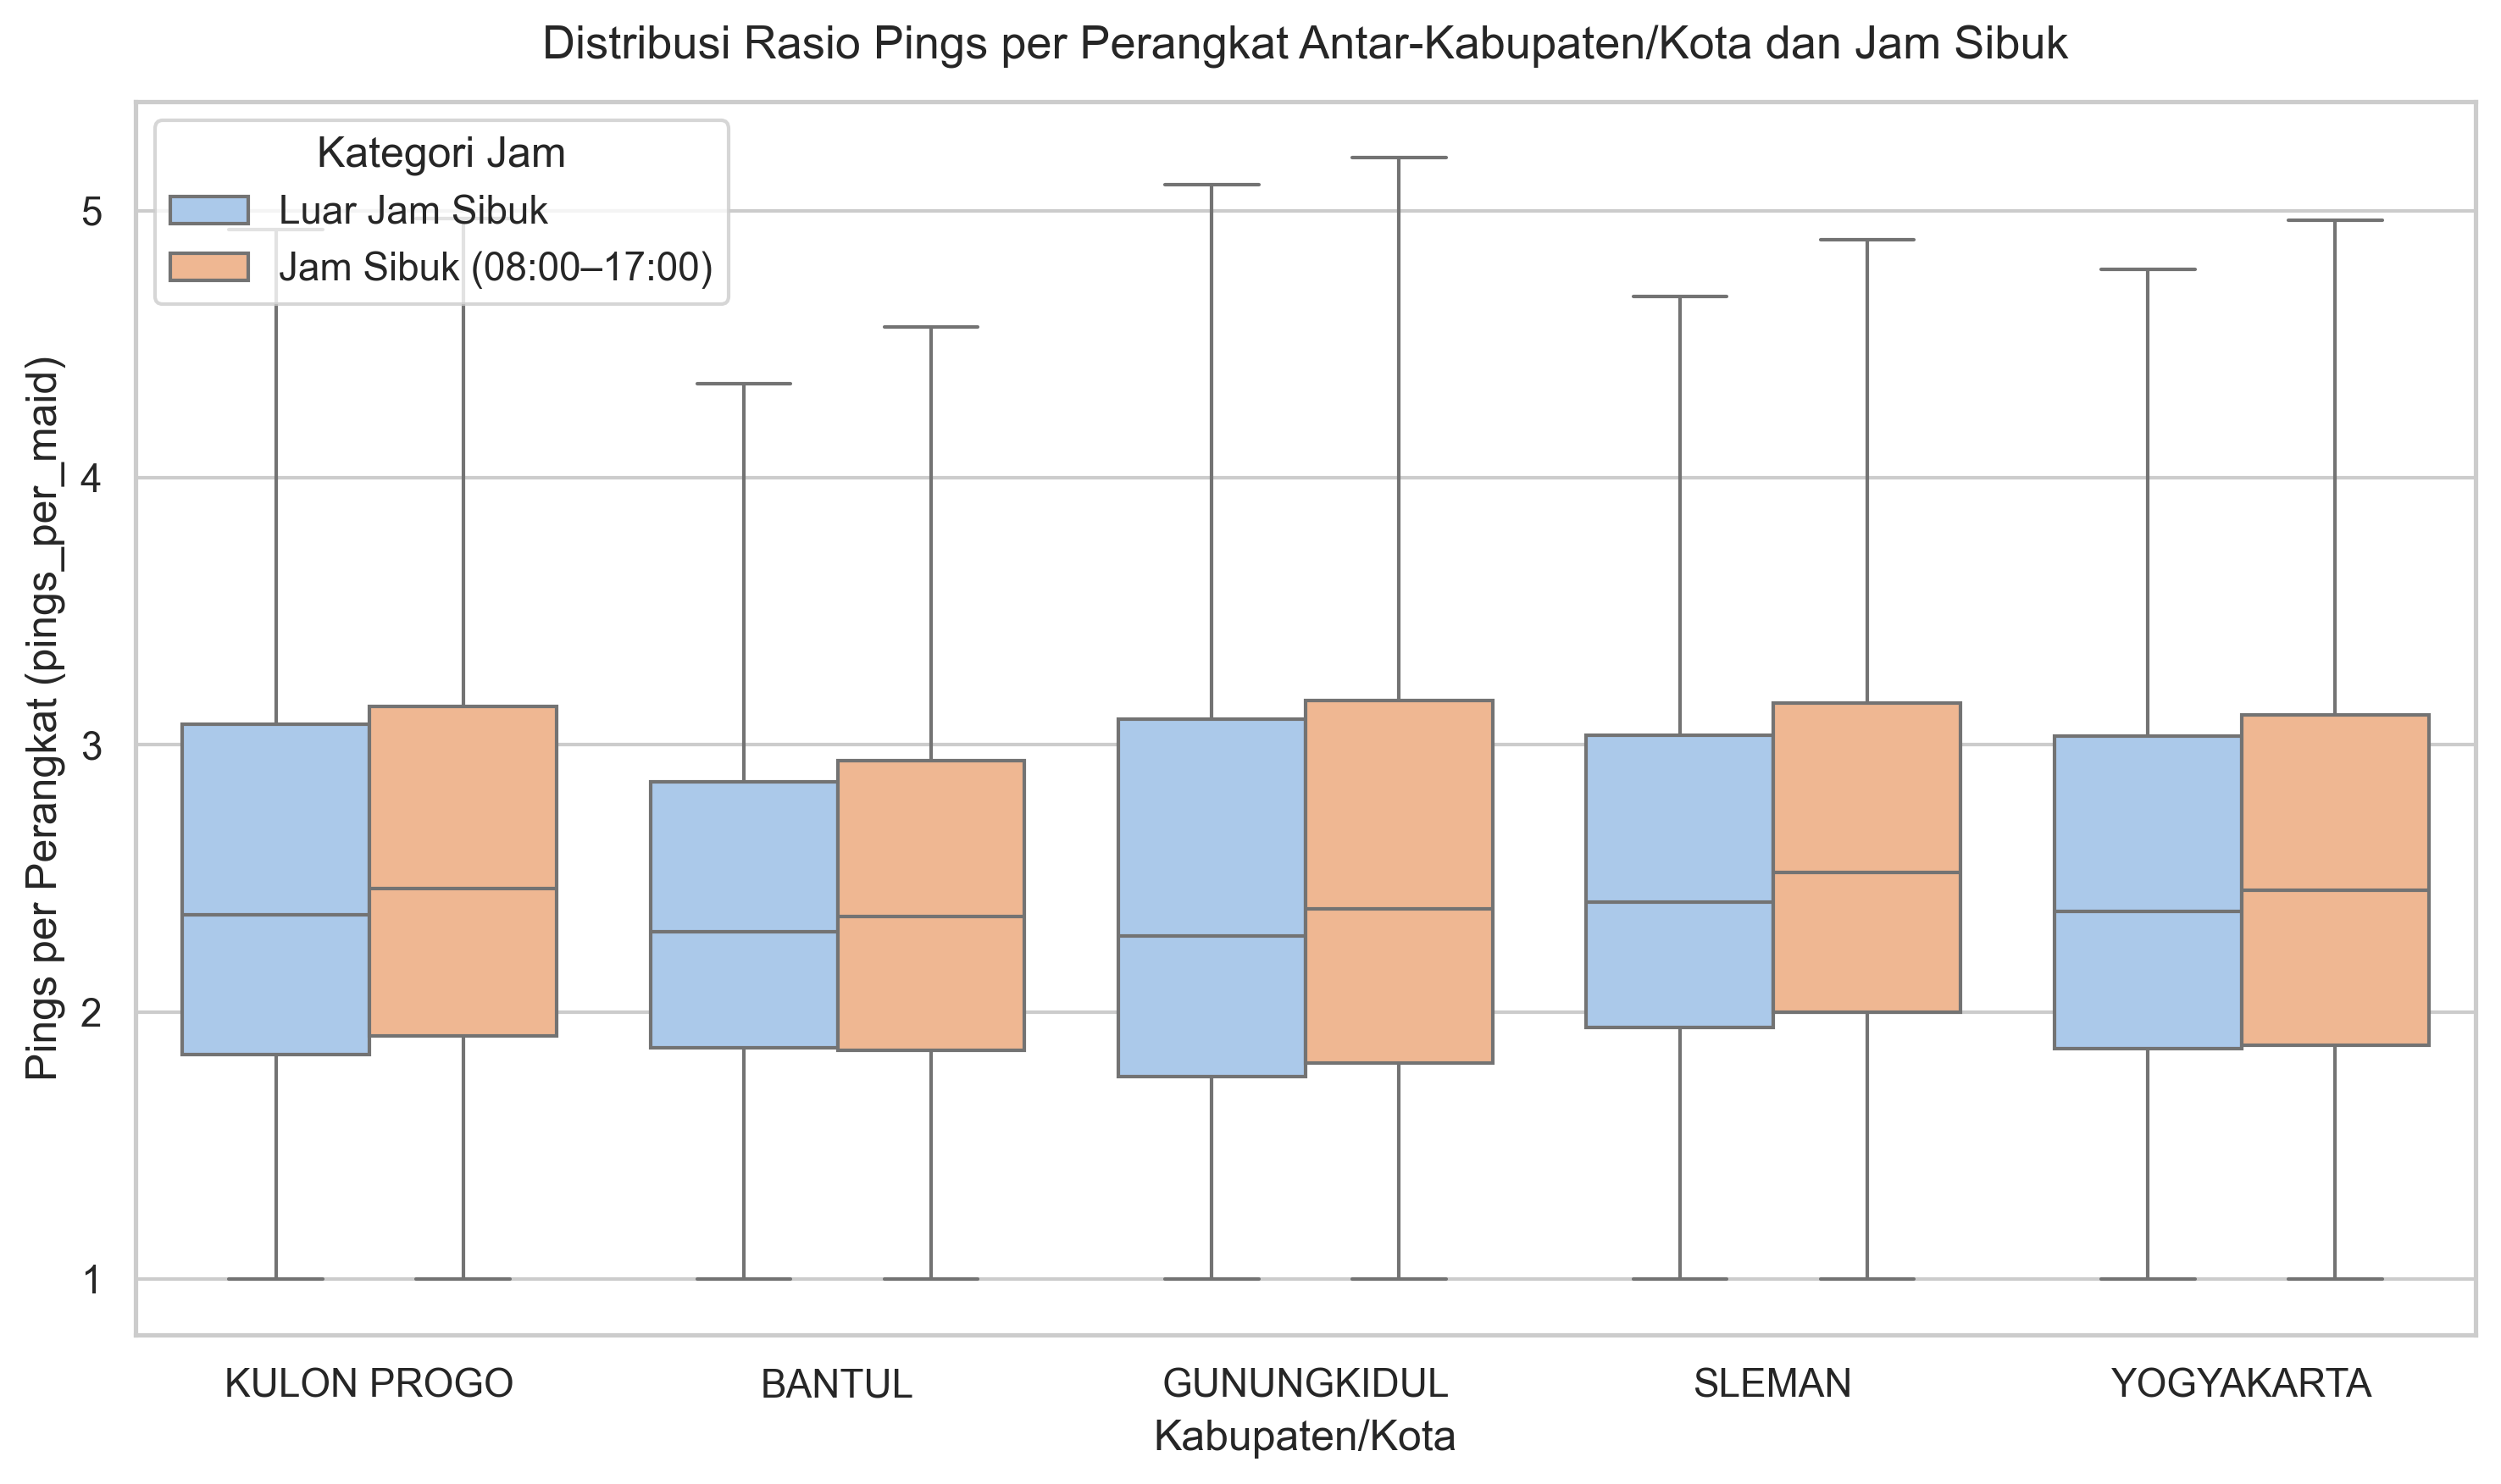

In [11]:
jam_sibuk = df_presence["hour"].between(8, 17)
df_presence["kategori_jam"] = np.where(jam_sibuk, "Jam Sibuk (08:00–17:00)", "Luar Jam Sibuk")

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.boxplot(
    data=df_presence,
    x="kab_kota",
    y="pings_per_maid",
    hue="kategori_jam",
    showfliers=False,
    palette="pastel",
    ax=ax,
)
ax.set_title("Distribusi Rasio Pings per Perangkat Antar-Kabupaten/Kota dan Jam Sibuk", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota")
ax.set_ylabel("Pings per Perangkat (pings_per_maid)")
ax.legend(title="Kategori Jam", frameon=True)
plt.tight_layout()
plt.savefig("figures/04b_boxplot_pings_per_maid.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 4:**
- Bila hanya dihitung rata-rata tak-tertimbang (`mean_pings_per_maid`), Gunungkidul (`2,63`) tampak setara dengan Sleman (`2,64`) dan Kota Yogyakarta (`2,65`) karena baris bervolume kecil memiliki bobot sama besar dengan pusat kota. Dengan metrik tertimbang (`weighted_pings_per_maid = total_pings / total_maids`), intensitas sinyal GPS tertinggi berada di **Kota Yogyakarta (`2,84`)** dan **Sleman (`2,73`)**, disusul **Kulon Progo (`2,70`)**, **Gunungkidul (`2,58`)**, dan **Bantul (`2,42`)**.
- Korelasi antara `n_maids` dan `n_pings` di 78 kapanewon bersifat sangat linear, dengan Depok, Ngaglik, Banguntapan, Gamping, dan Kasihan menempati posisi lima besar tertinggi.

## Bagian 5: Matriks Origin-Destination (OD) Makro Antar-Kabupaten/Kota

Mengagregasi aliran pergerakan siang hari (`n_maids`) berdasarkan kabupaten asal (`origin_kab_kota`) dan kabupaten tujuan (`dest_kab_kota`), lalu memisahkan komponen **Intra-Kapanewon (Lokal / Stay)** (`origin_code == dest_code`) dari **Komuter Intra-Kabupaten (Beda Kapanewon)** dan **Komuter Lintas Kabupaten/Kota** agar proporsi mobilitas internal tidak tercampur dengan perangkat yang tidak keluar dari kapanewon asalnya.

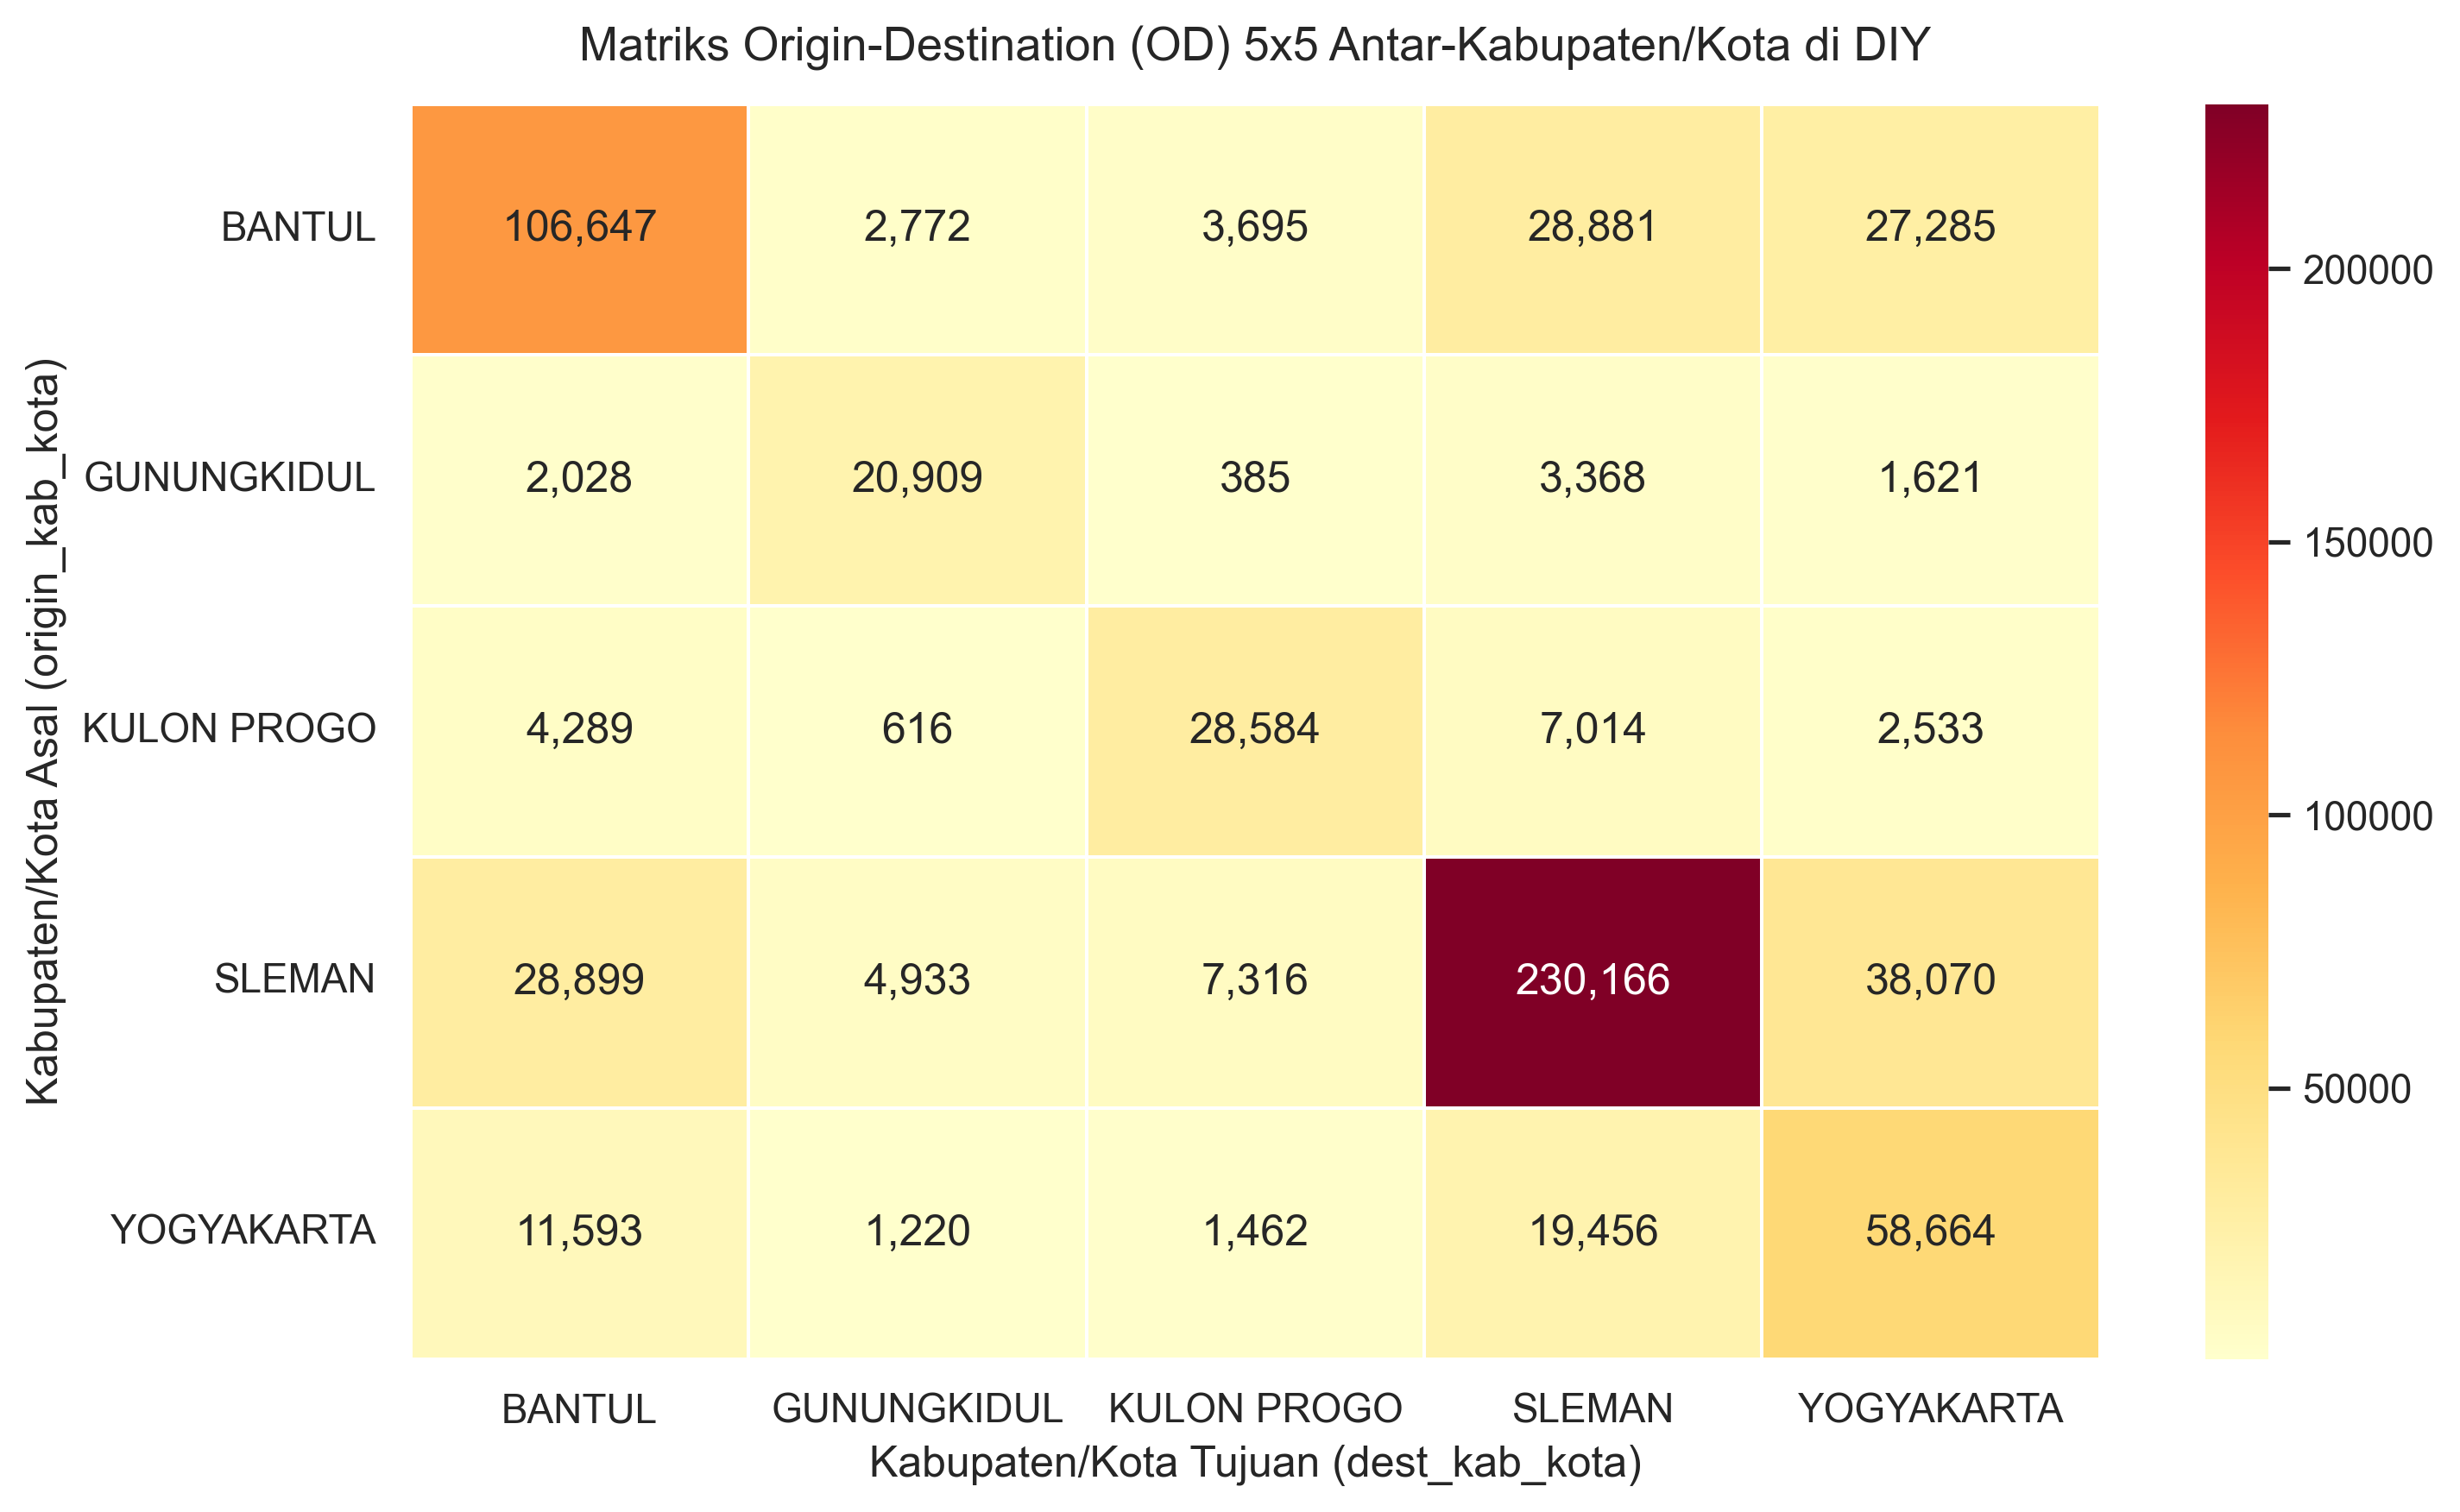

In [12]:
od_kab_matrix = (
    df_od.groupby(["origin_kab_kota", "dest_kab_kota"])["n_maids"]
    .sum()
    .unstack(fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.heatmap(od_kab_matrix, annot=True, fmt=",.0f", cmap="YlOrRd", linewidths=0.5, ax=ax)
ax.set_title("Matriks Origin-Destination (OD) 5x5 Antar-Kabupaten/Kota di DIY", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota Tujuan (dest_kab_kota)")
ax.set_ylabel("Kabupaten/Kota Asal (origin_kab_kota)")
plt.tight_layout()
plt.savefig("figures/05a_heatmap_od_5x5_kabkota.png", dpi=300, bbox_inches="tight")
plt.show()

Proporsi 3 Kategori Pergerakan (%):
tipe_pergerakan  Intra-Kapanewon (Lokal / Stay)  \
origin_kab_kota                                   
BANTUL                                     41.3   
GUNUNGKIDUL                                48.7   
KULON PROGO                                43.0   
SLEMAN                                     41.2   
YOGYAKARTA                                 29.1   

tipe_pergerakan  Komuter Intra-Kabupaten (Beda Kapanewon)  \
origin_kab_kota                                             
BANTUL                                               21.7   
GUNUNGKIDUL                                          25.2   
KULON PROGO                                          23.4   
SLEMAN                                               33.2   
YOGYAKARTA                                           34.4   

tipe_pergerakan  Komuter Lintas Kabupaten/Kota  
origin_kab_kota                                 
BANTUL                                    37.0  
GUNUNGKIDUL                    

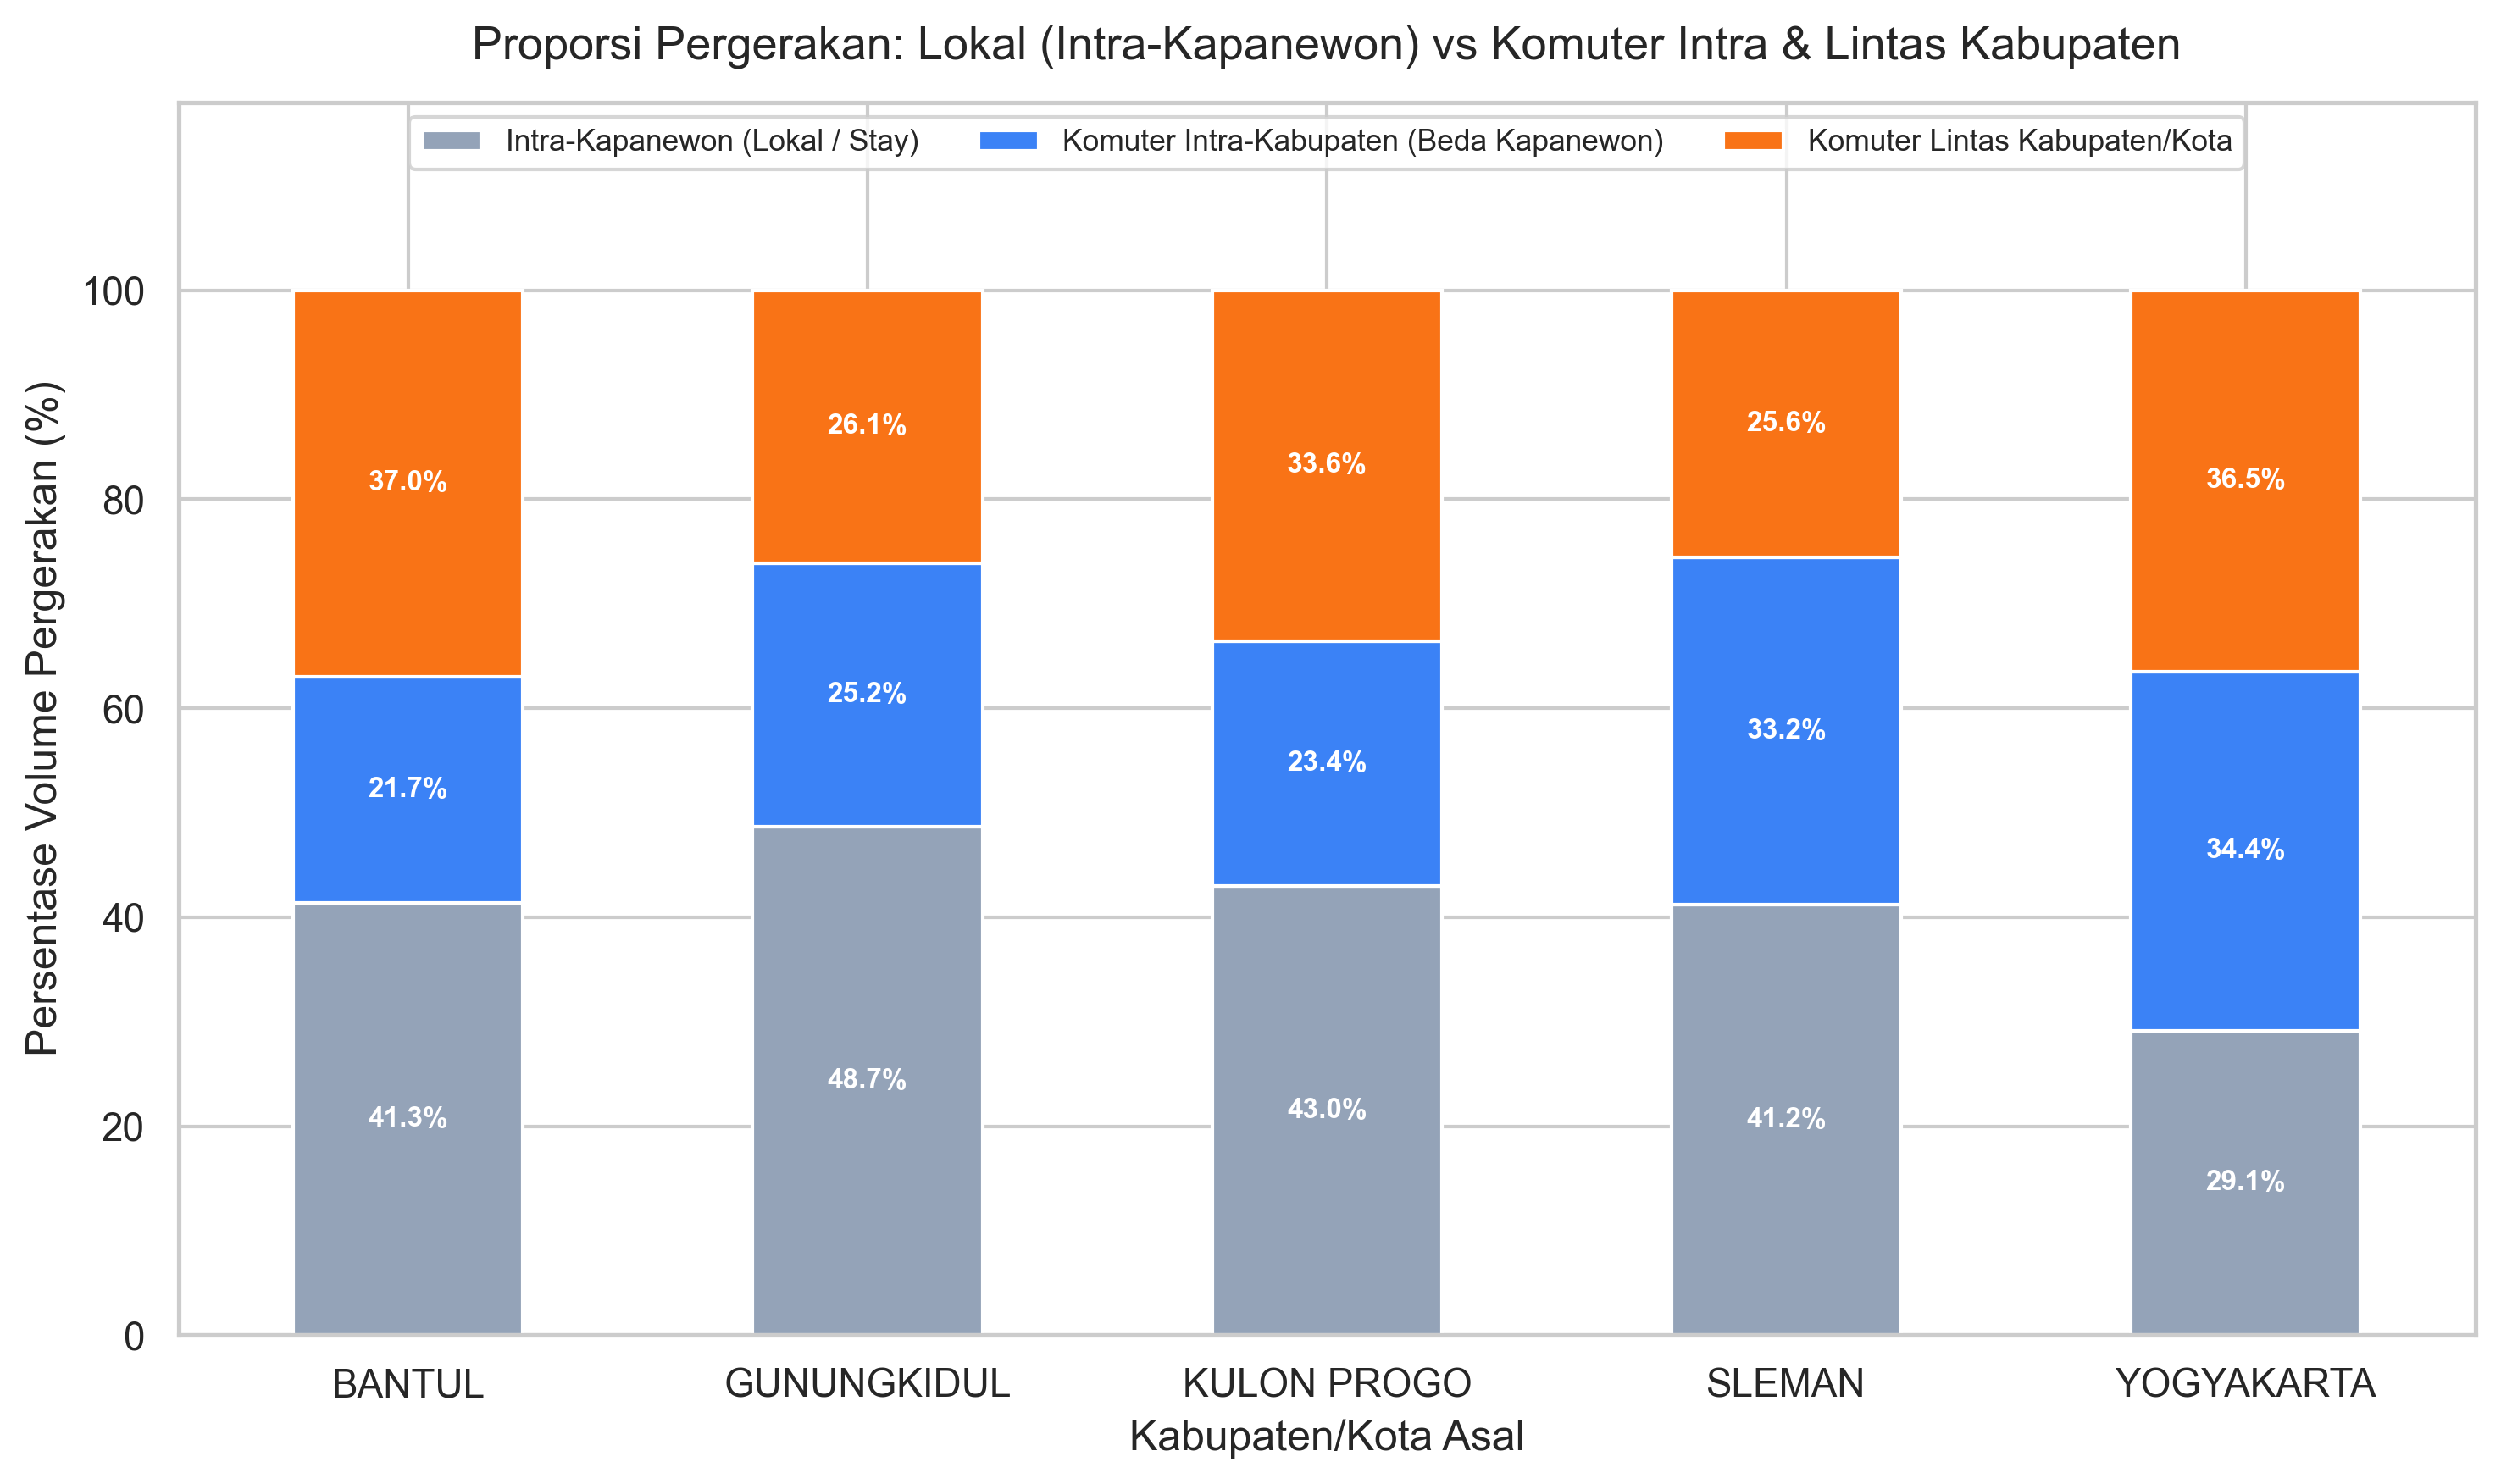

In [13]:
df_od["tipe_pergerakan"] = np.select(
    [
        df_od["origin_code"] == df_od["dest_code"],
        df_od["origin_kab_kota"] == df_od["dest_kab_kota"],
    ],
    [
        "Intra-Kapanewon (Lokal / Stay)",
        "Komuter Intra-Kabupaten (Beda Kapanewon)",
    ],
    default="Komuter Lintas Kabupaten/Kota",
)
kat_order = [
    "Intra-Kapanewon (Lokal / Stay)",
    "Komuter Intra-Kabupaten (Beda Kapanewon)",
    "Komuter Lintas Kabupaten/Kota",
]
prop_df = (
    df_od.groupby(["origin_kab_kota", "tipe_pergerakan"])["n_maids"]
    .sum()
    .unstack(fill_value=0)[kat_order]
)
prop_pct = prop_df.div(prop_df.sum(axis=1), axis=0) * 100
print("Proporsi 3 Kategori Pergerakan (%):")
print(prop_pct.round(1))

# Proporsi khusus komuter yang benar-benar keluar dari Kapanewon asal (origin_code != dest_code)
comm_only = prop_df[kat_order[1:]]
comm_pct = comm_only.div(comm_only.sum(axis=1), axis=0) * 100
print("\nProporsi Khusus Komuter Lintas-Kapanewon (%):")
print(comm_pct.round(1))

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
prop_pct.plot(
    kind="bar",
    stacked=True,
    color=["#94a3b8", "#3b82f6", "#f97316"],
    ax=ax,
)
for container in ax.containers:
    labels = [f"{v:.1f}%" if v >= 8 else "" for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=8, color="white", fontweight="bold")

ax.set_title("Proporsi Pergerakan: Lokal (Intra-Kapanewon) vs Komuter Intra & Lintas Kabupaten", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota Asal")
ax.set_ylabel("Persentase Volume Pergerakan (%)")
ax.set_ylim(0, 118)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.tick_params(axis="x", rotation=0)
ax.legend(title="", loc="upper center", ncol=3, frameon=True, fontsize=8.5)
plt.tight_layout()
plt.savefig("figures/05b_proporsi_intra_vs_inter_kabkota.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 5:**
- Sekitar **29,1%–48,7%** volume OD merupakan perangkat yang tetap berada di kapanewon tempat tinggalnya (`Intra-Kapanewon`), yang sebelumnya ikut terhitung sebagai mobilitas internal kabupaten.
- Ketika difokuskan khusus pada **komuter yang benar-benar berpindah ke luar kapanewon asal (`origin_code != dest_code`)**, mayoritas komuter dari **Bantul (63,1%)**, **Kulon Progo (58,9%)**, **Kota Yogyakarta (51,5%)**, dan **Gunungkidul (50,9%)** justru bergerak **Lintas Kabupaten/Kota**, sedangkan hanya **Sleman** yang mayoritas komuter lintas-kapanewonnya tetap berada di dalam wilayah Sleman (**56,5% Intra-Kabupaten** vs 43,5% Lintas Kabupaten).

## Bagian 6: Analisis Koridor Komuter Mikro Lintas-Kapanewon

Memfilter pergerakan lintas kapanewon (`origin_code != dest_code`) dengan label terdisambiguasi (`origin_kapanewon_label` & `dest_kapanewon_label`). Untuk pemeringkatan **Top 20 Rute Komuter Tersibuk (`06a`)**, analisis menggunakan periode kualitas normal (`~reduced_quality`, Des 2021 – Feb 2022) agar koridor komuter riil tidak terdistorsi oleh lonjakan artefak *fallback centroid* `GONDOMANAN -> SLEMAN` pada periode penurunan kualitas data (Mar–Apr 2022).

Catatan Rute GONDOMANAN -> SLEMAN: Normal (3 bln) = 1,492 | Reduced Quality (2 bln) = 1,153


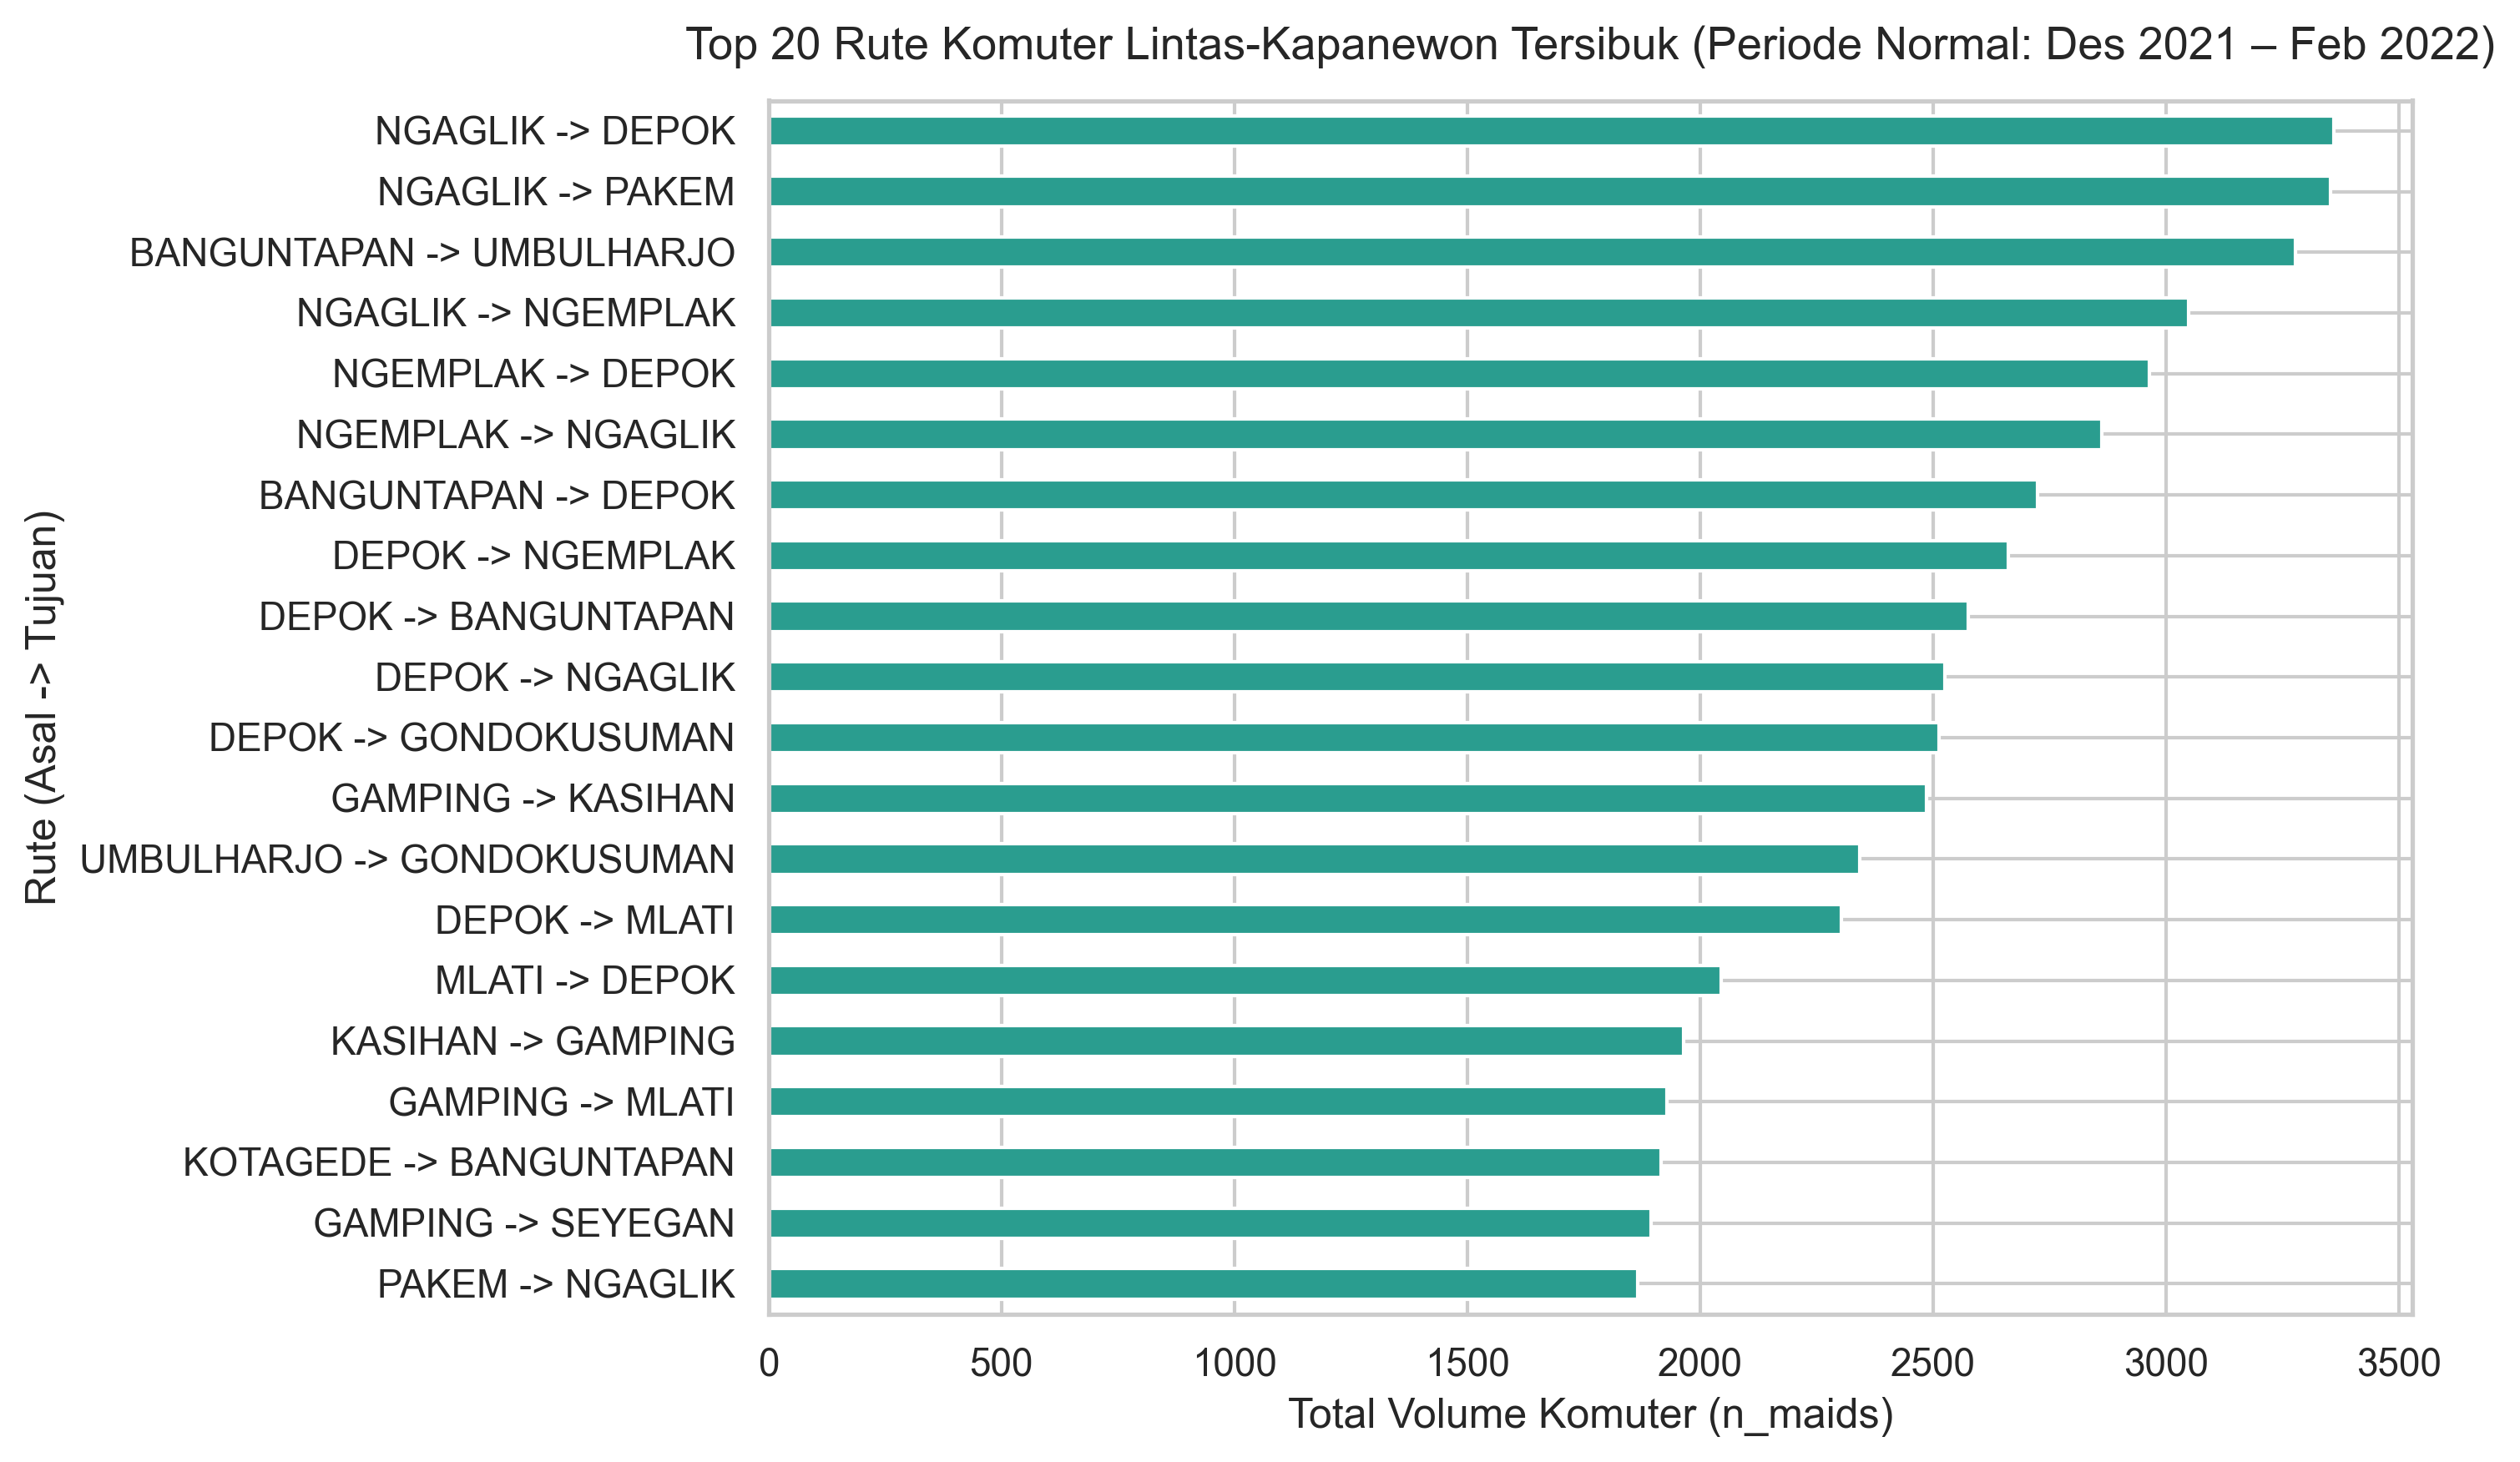

In [14]:
df_od_lintas = df_od[df_od["origin_code"] != df_od["dest_code"]].copy()
df_od_lintas["rute"] = (
    df_od_lintas["origin_kapanewon_label"] + " -> " + df_od_lintas["dest_kapanewon_label"]
)
df_od_lintas_normal = df_od_lintas[~df_od_lintas["reduced_quality"]].copy()

# Pembanding dampak artefak centroid Gondomanan -> Sleman pada periode reduced_quality
gondo_sleman_norm = df_od_lintas_normal.loc[
    df_od_lintas_normal["rute"] == "GONDOMANAN -> SLEMAN", "n_maids"
].sum()
gondo_sleman_rq = df_od_lintas.loc[
    df_od_lintas["reduced_quality"] & (df_od_lintas["rute"] == "GONDOMANAN -> SLEMAN"),
    "n_maids",
].sum()
print(f"Catatan Rute GONDOMANAN -> SLEMAN: Normal (3 bln) = {gondo_sleman_norm:,} | Reduced Quality (2 bln) = {gondo_sleman_rq:,}")

top20_rute = (
    df_od_lintas_normal.groupby("rute")["n_maids"]
    .sum()
    .nlargest(20)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
top20_rute.plot(kind="barh", color="#2a9d8f", ax=ax)
ax.set_title("Top 20 Rute Komuter Lintas-Kapanewon Tersibuk (Periode Normal: Des 2021 – Feb 2022)", fontsize=13, pad=12)
ax.set_xlabel("Total Volume Komuter (n_maids)")
ax.set_ylabel("Rute (Asal -> Tujuan)")
plt.tight_layout()
plt.savefig("figures/06a_top20_rute_lintas_kapanewon.png", dpi=300, bbox_inches="tight")
plt.show()

Top 10 Penerima Kunjungan (Terdisambiguasi):
dest_kapanewon_label
DEPOK           29796
BANGUNTAPAN     19612
NGAGLIK         19134
GAMPING         17506
GONDOKUSUMAN    16120
MLATI           16075
UMBULHARJO      16028
KASIHAN         14949
PAKEM           13350
NGEMPLAK        12238
Name: n_maids, dtype: int64


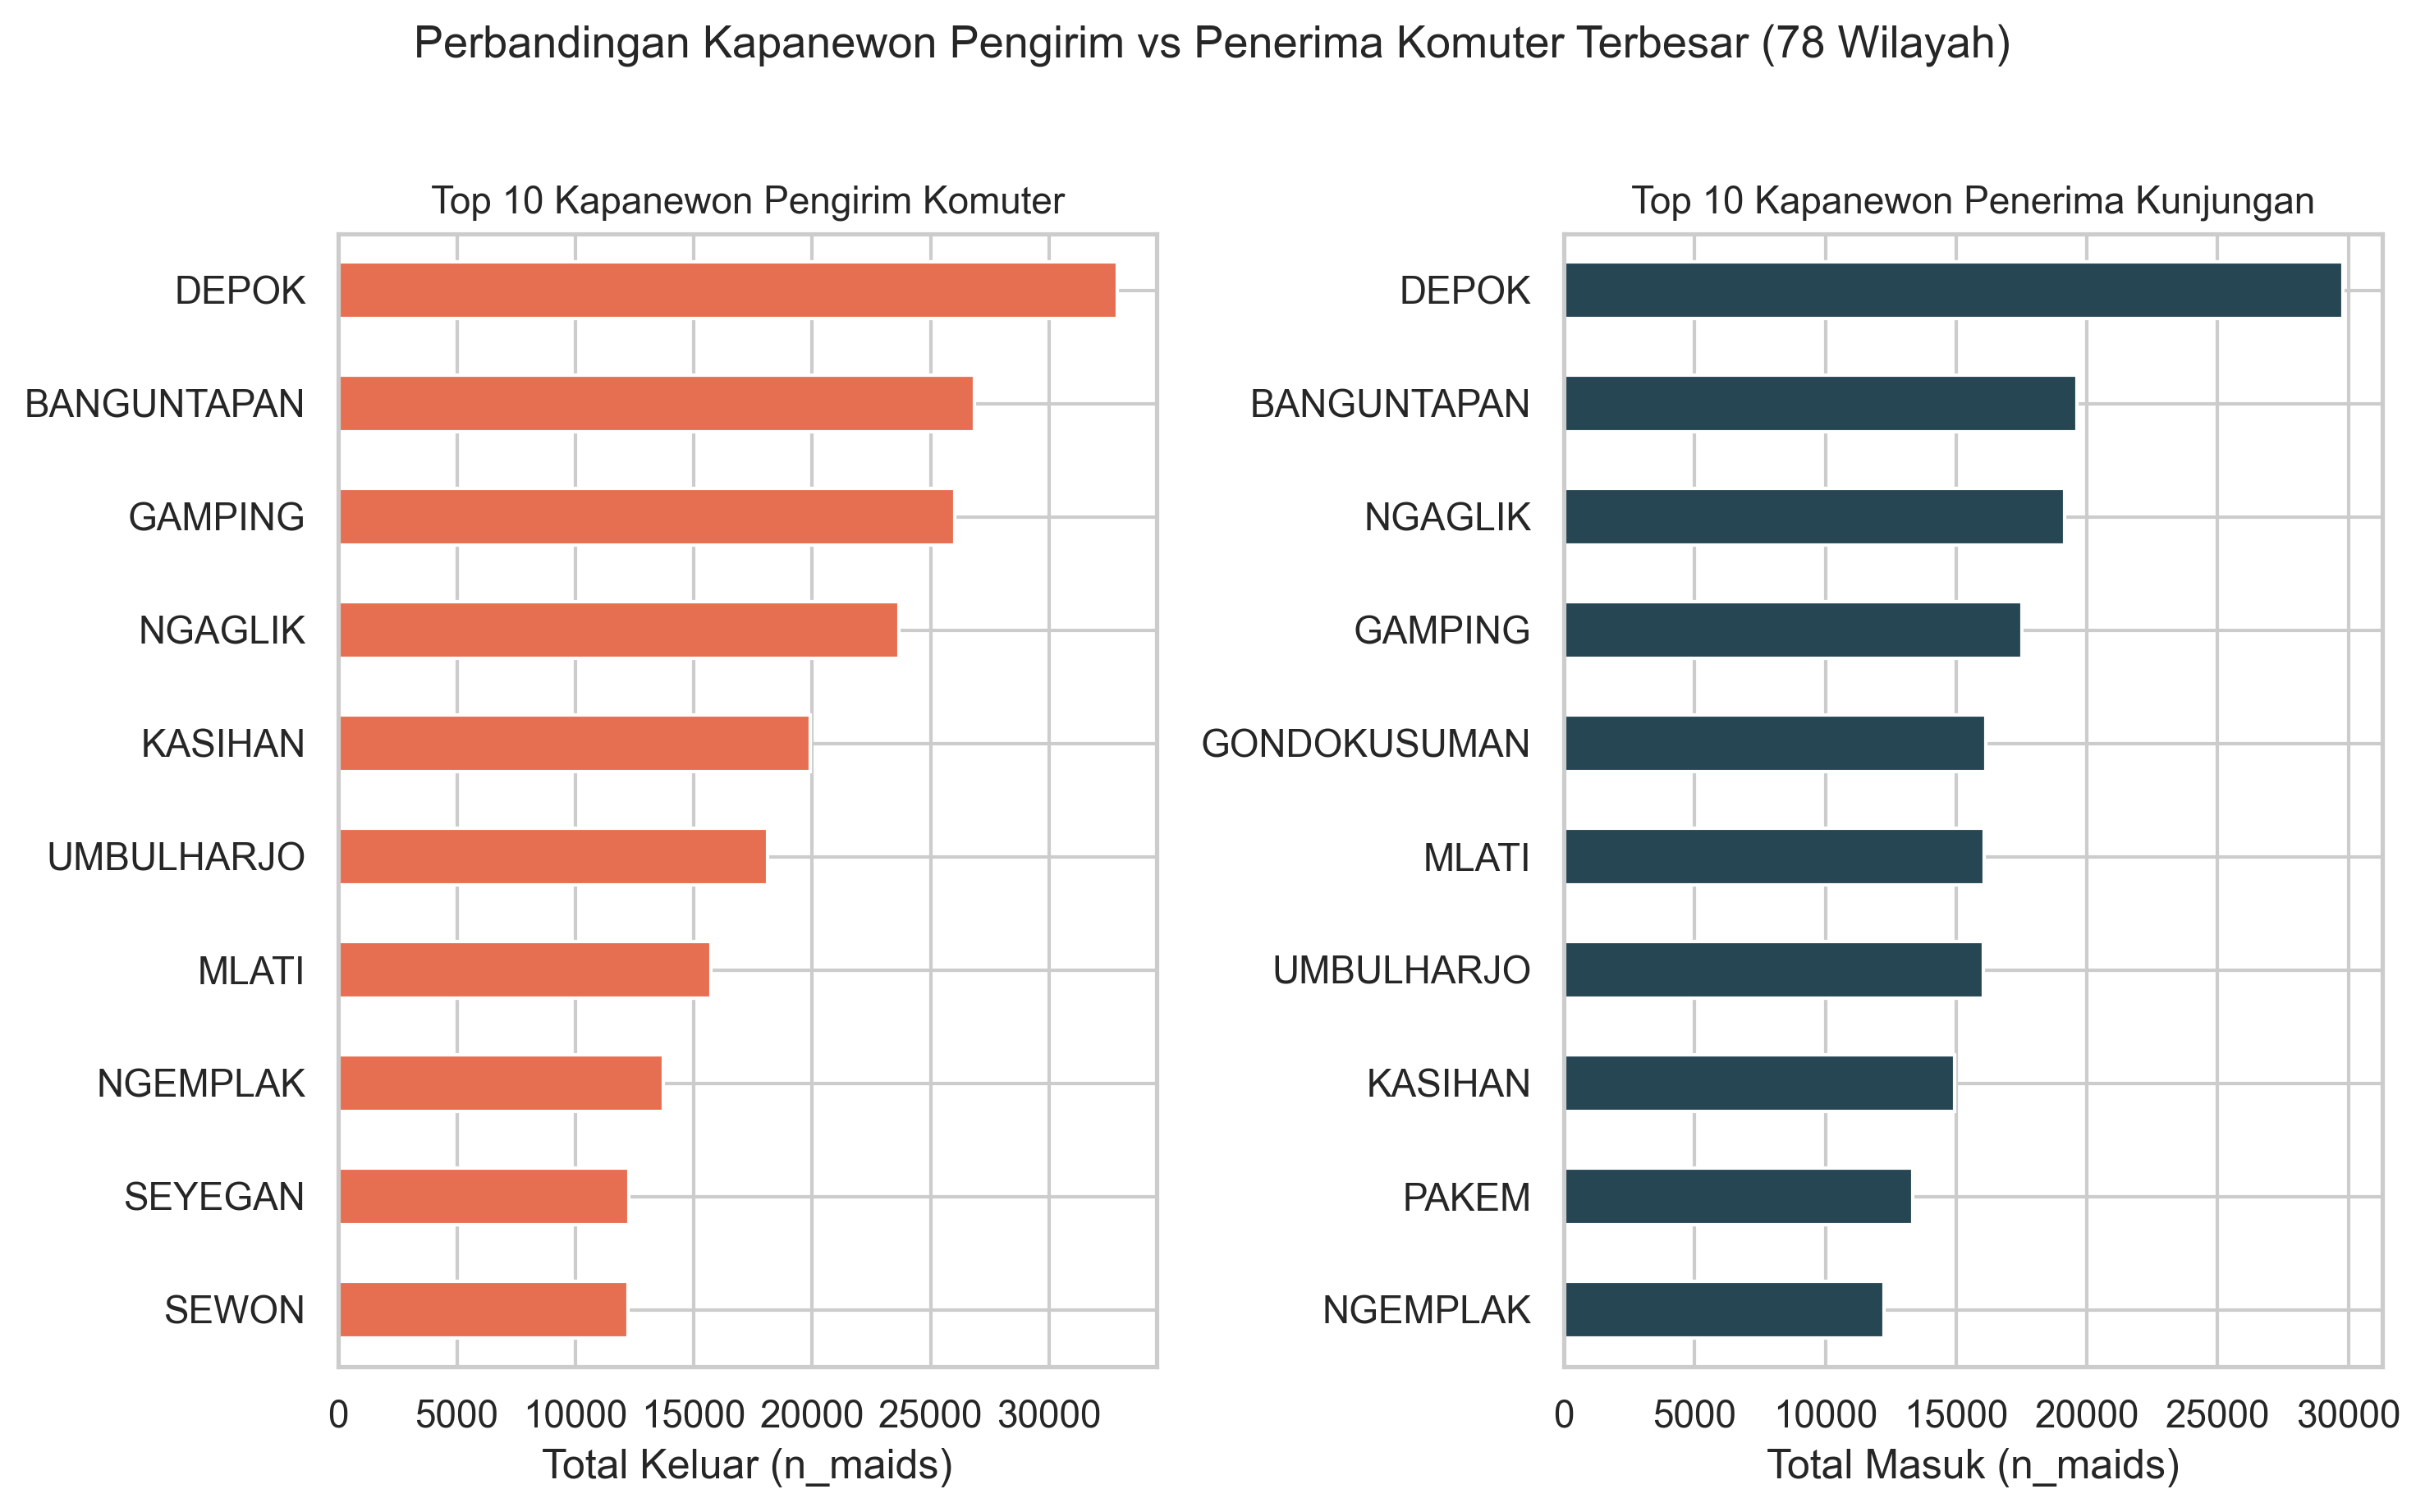

In [15]:
top10_pengirim = (
    df_od_lintas.groupby("origin_kapanewon_label")["n_maids"]
    .sum()
    .nlargest(10)
    .sort_values()
)
top10_penerima = (
    df_od_lintas.groupby("dest_kapanewon_label")["n_maids"]
    .sum()
    .nlargest(10)
    .sort_values()
)
print("Top 10 Penerima Kunjungan (Terdisambiguasi):")
print(top10_penerima.sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 6), dpi=300)
top10_pengirim.plot(kind="barh", color="#e76f51", ax=axes[0])
axes[0].set_title("Top 10 Kapanewon Pengirim Komuter", fontsize=11)
axes[0].set_xlabel("Total Keluar (n_maids)")
axes[0].set_ylabel("")

top10_penerima.plot(kind="barh", color="#264653", ax=axes[1])
axes[1].set_title("Top 10 Kapanewon Penerima Kunjungan", fontsize=11)
axes[1].set_xlabel("Total Masuk (n_maids)")
axes[1].set_ylabel("")

fig.suptitle("Perbandingan Kapanewon Pengirim vs Penerima Komuter Terbesar (78 Wilayah)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("figures/06b_top10_pengirim_vs_penerima.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 6:**
- Setelah memisahkan `JETIS (YOGYAKARTA)` dan `JETIS (BANTUL)`, `JETIS` keluar dari daftar Top 10 Penerima Kunjungan dan peringkat #10 yang sebenarnya ditempati oleh **`NGEMPLAK` (`12.238` MAIDs)**.
- Pada periode kualitas normal (Des 2021 – Feb 2022), 20 koridor komuter tersibuk didominasi rute bertetangga jarak dekat di aglomerasi Sleman–Kota Yogyakarta–Bantul (seperti `NGAGLIK -> DEPOK`, `NGAGLIK -> PAKEM`, `BANGUNTAPAN -> UMBULHARJO`, `NGAGLIK -> NGEMPLAK`), sedangkan rute tak-bertetangga `GONDOMANAN -> SLEMAN` yang sebelumnya masuk #12 ternyata dipicu oleh periode `reduced_quality` (Maret–April 2022).

## Bagian 7: Pemodelan Jaringan Graf (Network Centrality) 78 Kapanewon

Membangun graf berarah (*directed weighted graph*) menggunakan `networkx` dengan tepat **78 kapanewon** sebagai simpul (`origin_kapanewon_label` & `dest_kapanewon_label`) tanpa *self-loop* palsu, lalu menghitung *Weighted In-Degree*, *Weighted Out-Degree*, dan *PageRank Centrality*. Visualisasi 15 koridor utama (`07a`) menggunakan koridor dari periode normal agar bebas dari garis artefak *centroid* `GONDOMANAN -> SLEMAN`.

In [16]:
edge_agg = (
    df_od_lintas.groupby(["origin_kapanewon_label", "dest_kapanewon_label"])["n_maids"]
    .sum()
    .reset_index()
)

G = nx.DiGraph()
for _, row in edge_agg.iterrows():
    G.add_edge(row["origin_kapanewon_label"], row["dest_kapanewon_label"], weight=row["n_maids"])

assert G.number_of_nodes() == 78, f"Seharusnya 78 simpul, terbaca {G.number_of_nodes()}"
assert nx.number_of_selfloops(G) == 0, "Masih terdapat self-loop pada graf!"

in_deg = dict(G.in_degree(weight="weight"))
out_deg = dict(G.out_degree(weight="weight"))
pagerank = nx.pagerank(G, weight="weight")

centrality_df = pd.DataFrame({
    "kapanewon": list(G.nodes()),
    "weighted_in_degree": [in_deg[n] for n in G.nodes()],
    "weighted_out_degree": [out_deg[n] for n in G.nodes()],
    "pagerank": [pagerank[n] for n in G.nodes()],
}).sort_values("pagerank", ascending=False).reset_index(drop=True)

print(f"Total simpul graf: {G.number_of_nodes()} | Total sisi: {G.number_of_edges()} | Self-loops: {nx.number_of_selfloops(G)}")
centrality_df.head(15)

Total simpul graf: 78 | Total sisi: 3239 | Self-loops: 0


,kapanewon,weighted_in_degree,weighted_out_degree,pagerank
0,DEPOK,29796,32890,0.064762
1,BANGUNTAPAN,19612,26847,0.045219
2,NGAGLIK,19134,23649,0.041226
3,UMBULHARJO,16028,18096,0.038532
4,GAMPING,17506,26005,0.037623
5,GONDOKUSUMAN,16120,7491,0.036578
6,KASIHAN,14949,19910,0.034880
7,MLATI,16075,15716,0.033357
8,GONDOMANAN,10899,8760,0.029163
9,SLEMAN,11564,8919,0.028149


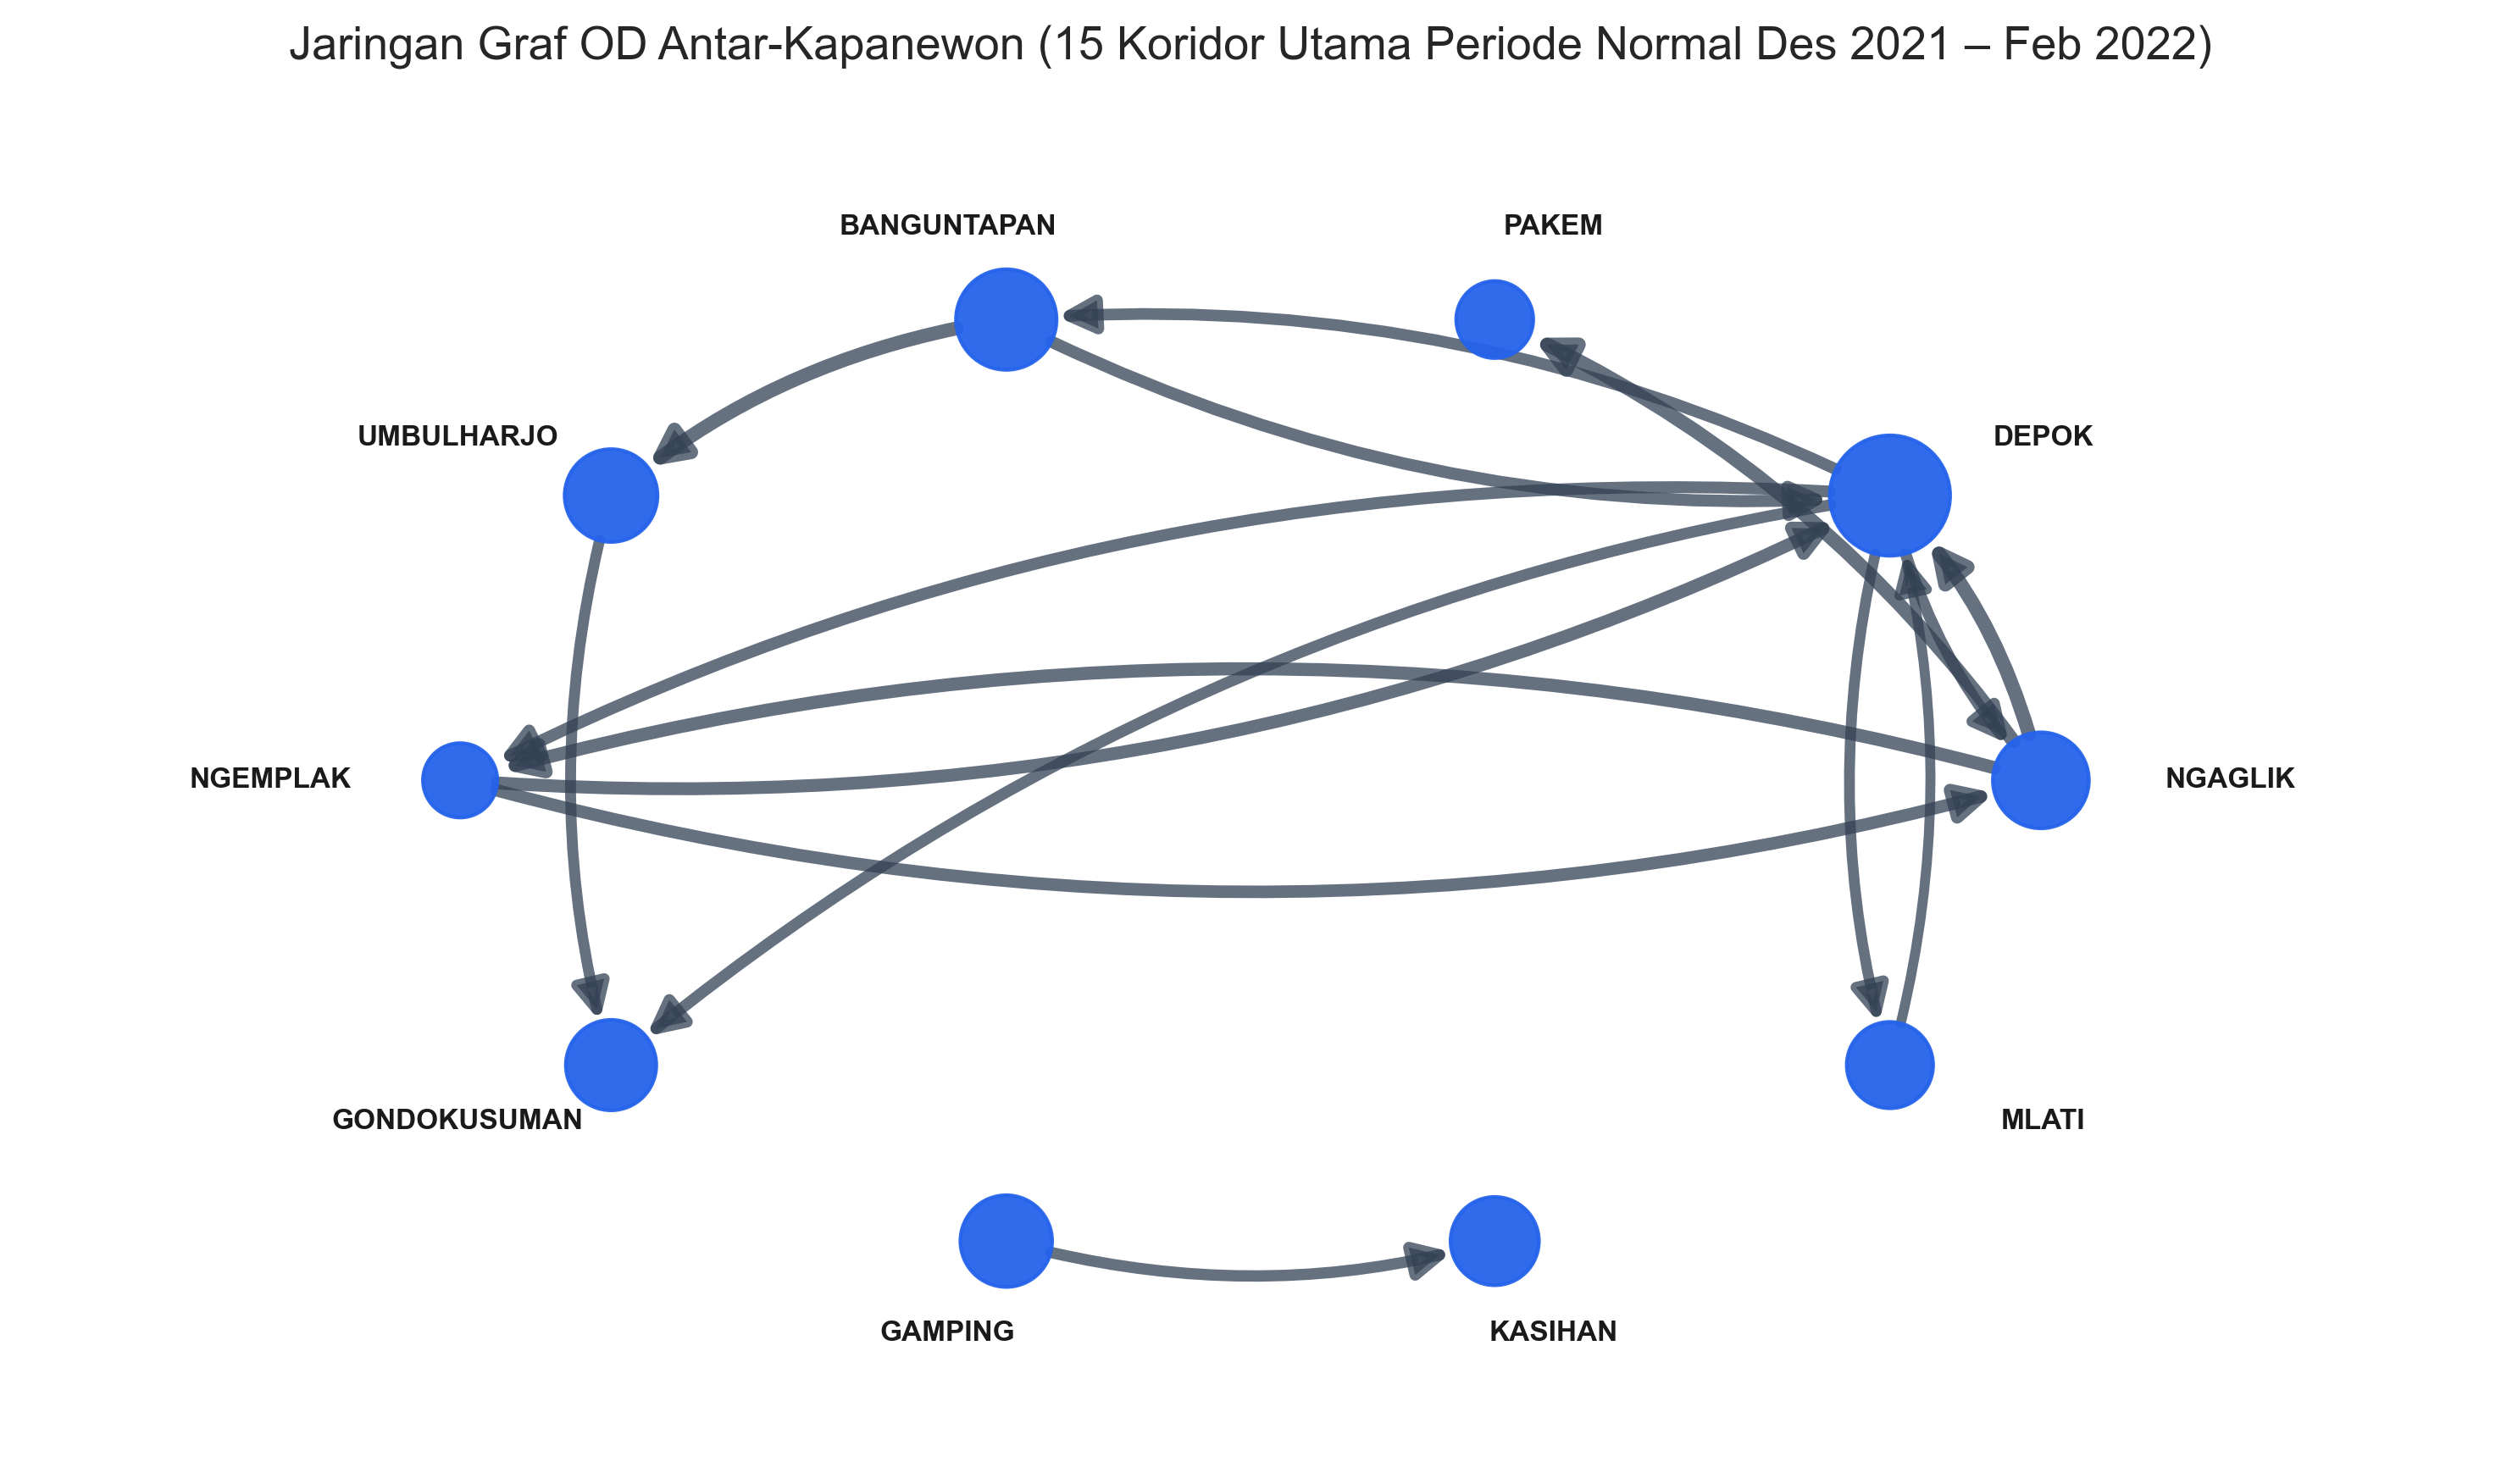

In [17]:
edge_agg_normal = (
    df_od_lintas_normal.groupby(["origin_kapanewon_label", "dest_kapanewon_label"])["n_maids"]
    .sum()
    .reset_index()
)
top_edges = edge_agg_normal.nlargest(15, "n_maids")
G_vis = nx.DiGraph()
for _, row in top_edges.iterrows():
    G_vis.add_edge(row["origin_kapanewon_label"], row["dest_kapanewon_label"], weight=row["n_maids"])

pos = nx.circular_layout(G_vis)
node_sizes = [pagerank.get(n, 0.005) * 18000 for n in G_vis.nodes()]
max_w = top_edges["n_maids"].max()
edge_widths = [1.0 + 3.0 * (d["weight"] / max_w) for _, _, d in G_vis.edges(data=True)]

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
nx.draw_networkx_nodes(G_vis, pos, node_size=node_sizes, node_color="#2563eb", alpha=0.95, ax=ax)
nx.draw_networkx_edges(
    G_vis,
    pos,
    node_size=node_sizes,
    width=edge_widths,
    alpha=0.75,
    edge_color="#334155",
    arrows=True,
    arrowstyle="-|>",
    arrowsize=20,
    min_target_margin=12,
    connectionstyle="arc3,rad=0.14",
    ax=ax,
)

label_pos = {k: (v[0] * 1.24, v[1] * 1.20) for k, v in pos.items()}
nx.draw_networkx_labels(G_vis, label_pos, font_size=8, font_weight="bold", ax=ax)

ax.set_xlim(-1.55, 1.55)
ax.set_ylim(-1.40, 1.40)
ax.set_title("Jaringan Graf OD Antar-Kapanewon (15 Koridor Utama Periode Normal Des 2021 – Feb 2022)", fontsize=13, pad=12)
ax.axis("off")
plt.tight_layout()
plt.savefig("figures/07a_network_graph_od.png", dpi=300, bbox_inches="tight")
plt.show()

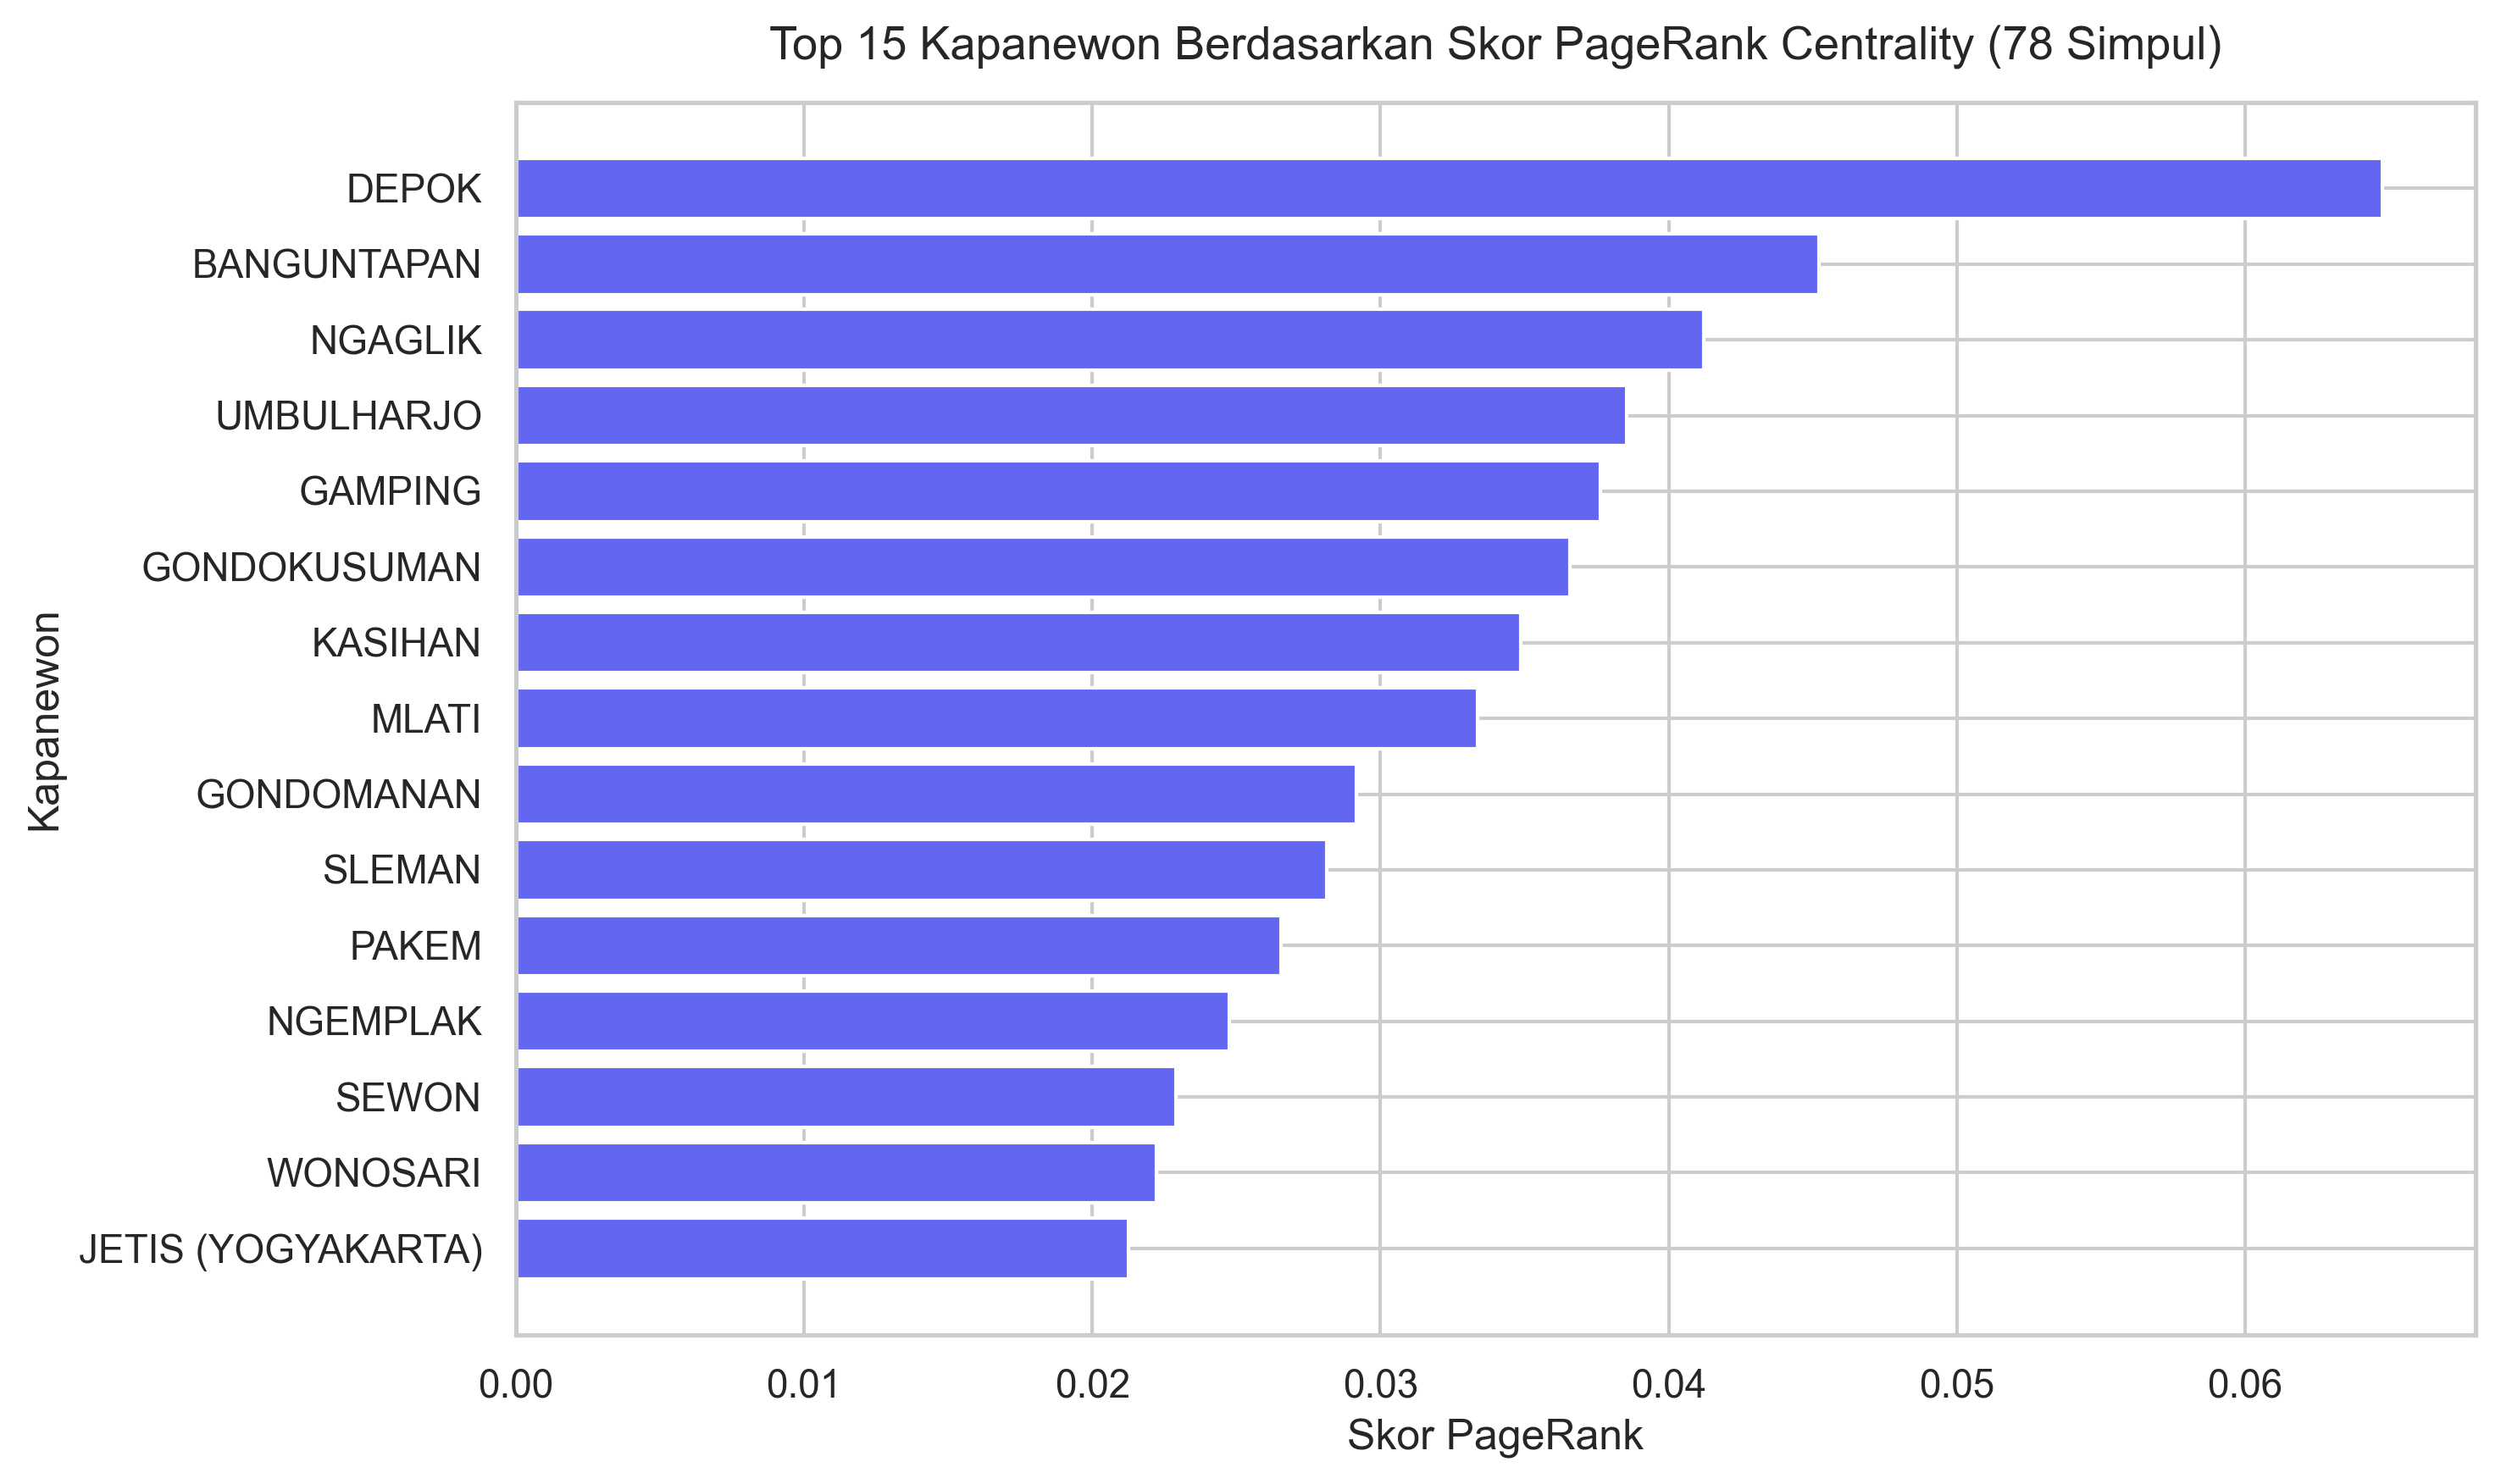

In [18]:
top15_pr = centrality_df.head(15).sort_values("pagerank", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.barh(top15_pr["kapanewon"], top15_pr["pagerank"], color="#6366f1")
ax.set_title("Top 15 Kapanewon Berdasarkan Skor PageRank Centrality (78 Simpul)", fontsize=13, pad=12)
ax.set_xlabel("Skor PageRank")
ax.set_ylabel("Kapanewon")
plt.tight_layout()
plt.savefig("figures/07b_top15_pagerank_kapanewon.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 7:**
- Graf berarah berhasil dikonstruksi dengan tepat **78 simpul** dan **0 *self-loop*** (menghapus *self-loop* palsu `JETIS -> JETIS` berbobot 54 akibat tabrakan nama).
- **Depok (PageRank `0,064762`)**, **Banguntapan (`0,045219`)**, **Ngaglik (`0,041226`)**, **Umbulharjo (`0,038532`)**, dan **Gamping (`0,037623`)** bertindak sebagai *hub* utama mobilitas aglomerasi DIY.
- Setelah pemisahan dua entitas Jetis, **`JETIS (YOGYAKARTA)` menempati peringkat #15 (`0,021256`)** sedangkan `JETIS (BANTUL)` berada di peringkat #28 (`0,011931`), mengembalikan peringkat #9–#14 yang sebenarnya kepada Gondomanan, Sleman, Pakem, Ngemplak, Sewon, dan Wonosari.

## Bagian 8: Tren Pergerakan Bulanan & Evaluasi Kualitas Data (`reduced_quality`)

Menganalisis evolusi volume aliran OD bulanan (`2021-12` hingga `2022-04`) per Kabupaten/Kota tujuan serta mengevaluasi dampak penanda `reduced_quality` pada periode Maret–April 2022 (2 bulan) dibandingkan periode normal Desember 2021–Februari 2022 (3 bulan) dengan menormalisasi jumlah rute aktif menjadi **rata-rata rute aktif per bulan**.

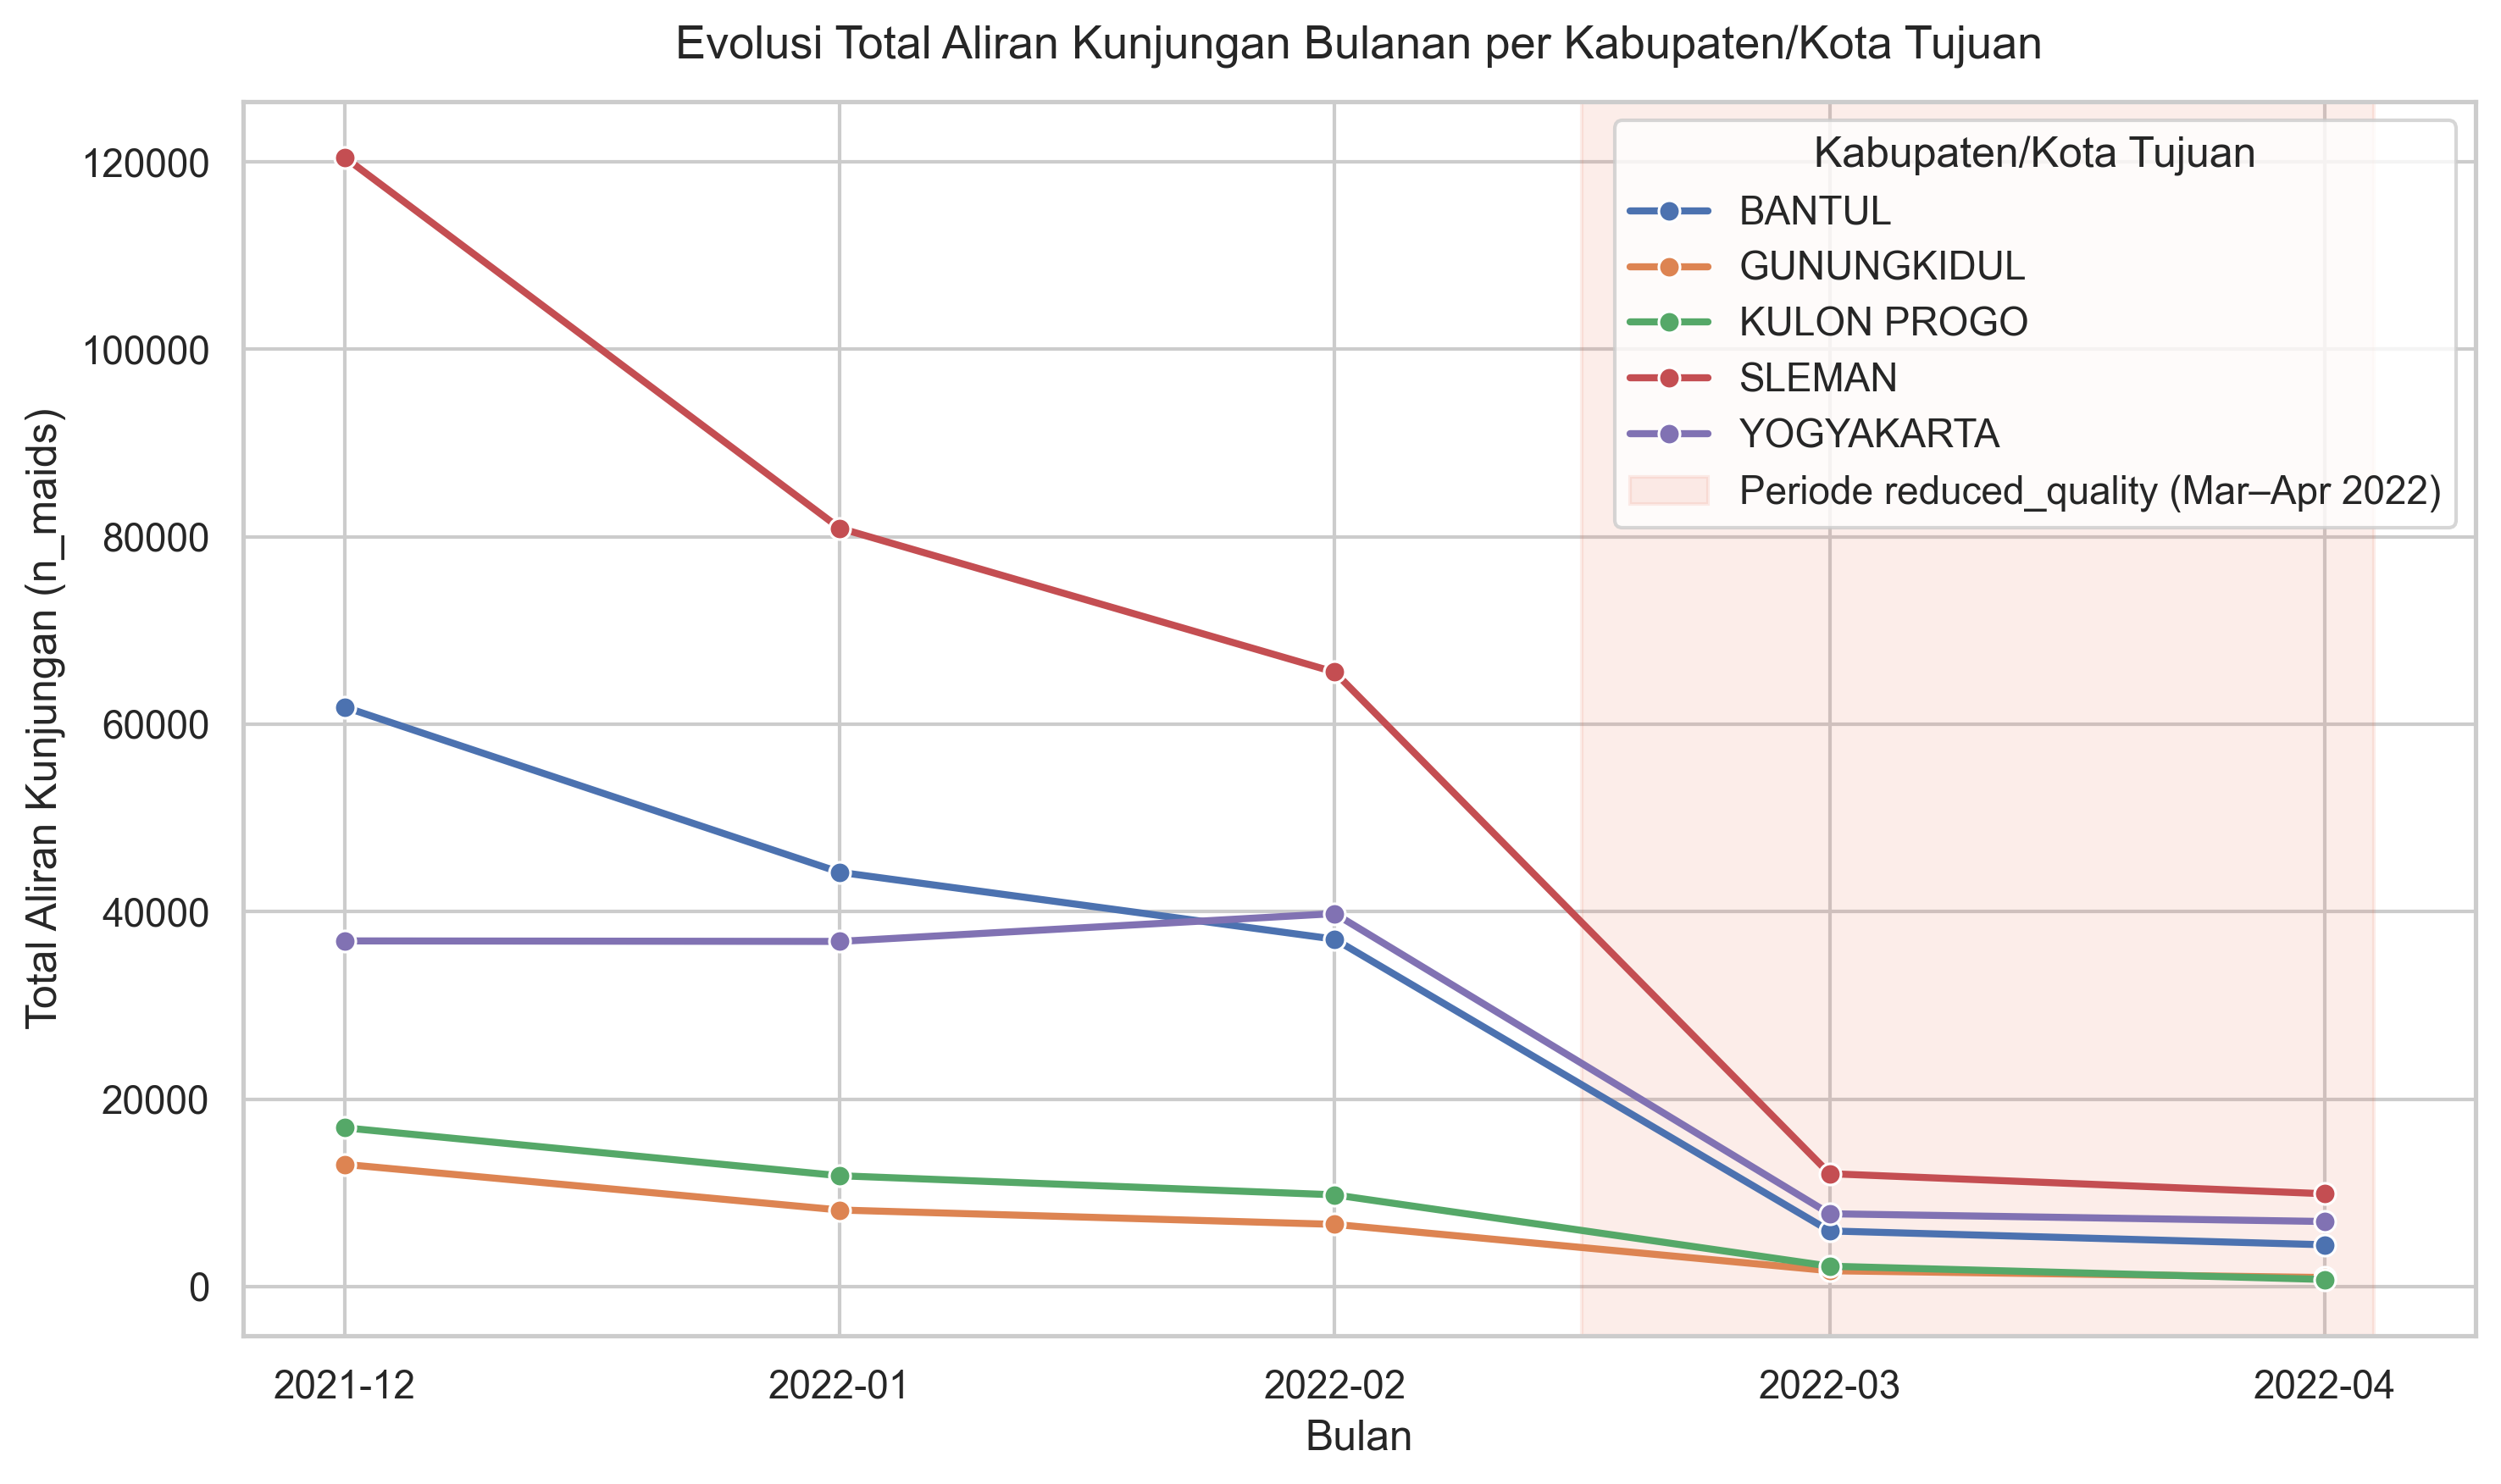

In [19]:
df_od["month"] = df_od["month"].astype(str)
monthly_dest = (
    df_od.groupby(["month", "dest_kab_kota"])["n_maids"]
    .sum()
    .reset_index()
    .sort_values("month")
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.lineplot(
    data=monthly_dest,
    x="month",
    y="n_maids",
    hue="dest_kab_kota",
    marker="o",
    linewidth=2,
    ax=ax,
)
ax.axvspan(2.5, 4.1, color="#e76f51", alpha=0.12, label="Periode reduced_quality (Mar–Apr 2022)")
ax.set_title("Evolusi Total Aliran Kunjungan Bulanan per Kabupaten/Kota Tujuan", fontsize=13, pad=12)
ax.set_xlabel("Bulan")
ax.set_ylabel("Total Aliran Kunjungan (n_maids)")
ax.legend(title="Kabupaten/Kota Tujuan", frameon=True)
plt.tight_layout()
plt.savefig("figures/08a_tren_bulanan_od_kabkota.png", dpi=300, bbox_inches="tight")
plt.show()

               status_kualitas  total_rute_od  jumlah_bulan  rata_rata_maids  rute_aktif_per_bulan
  Normal (Des 2021 – Feb 2022)           7872             3        74.931021                2624.0
Reduced Quality (Mar–Apr 2022)           2022             2        25.988625                1011.0


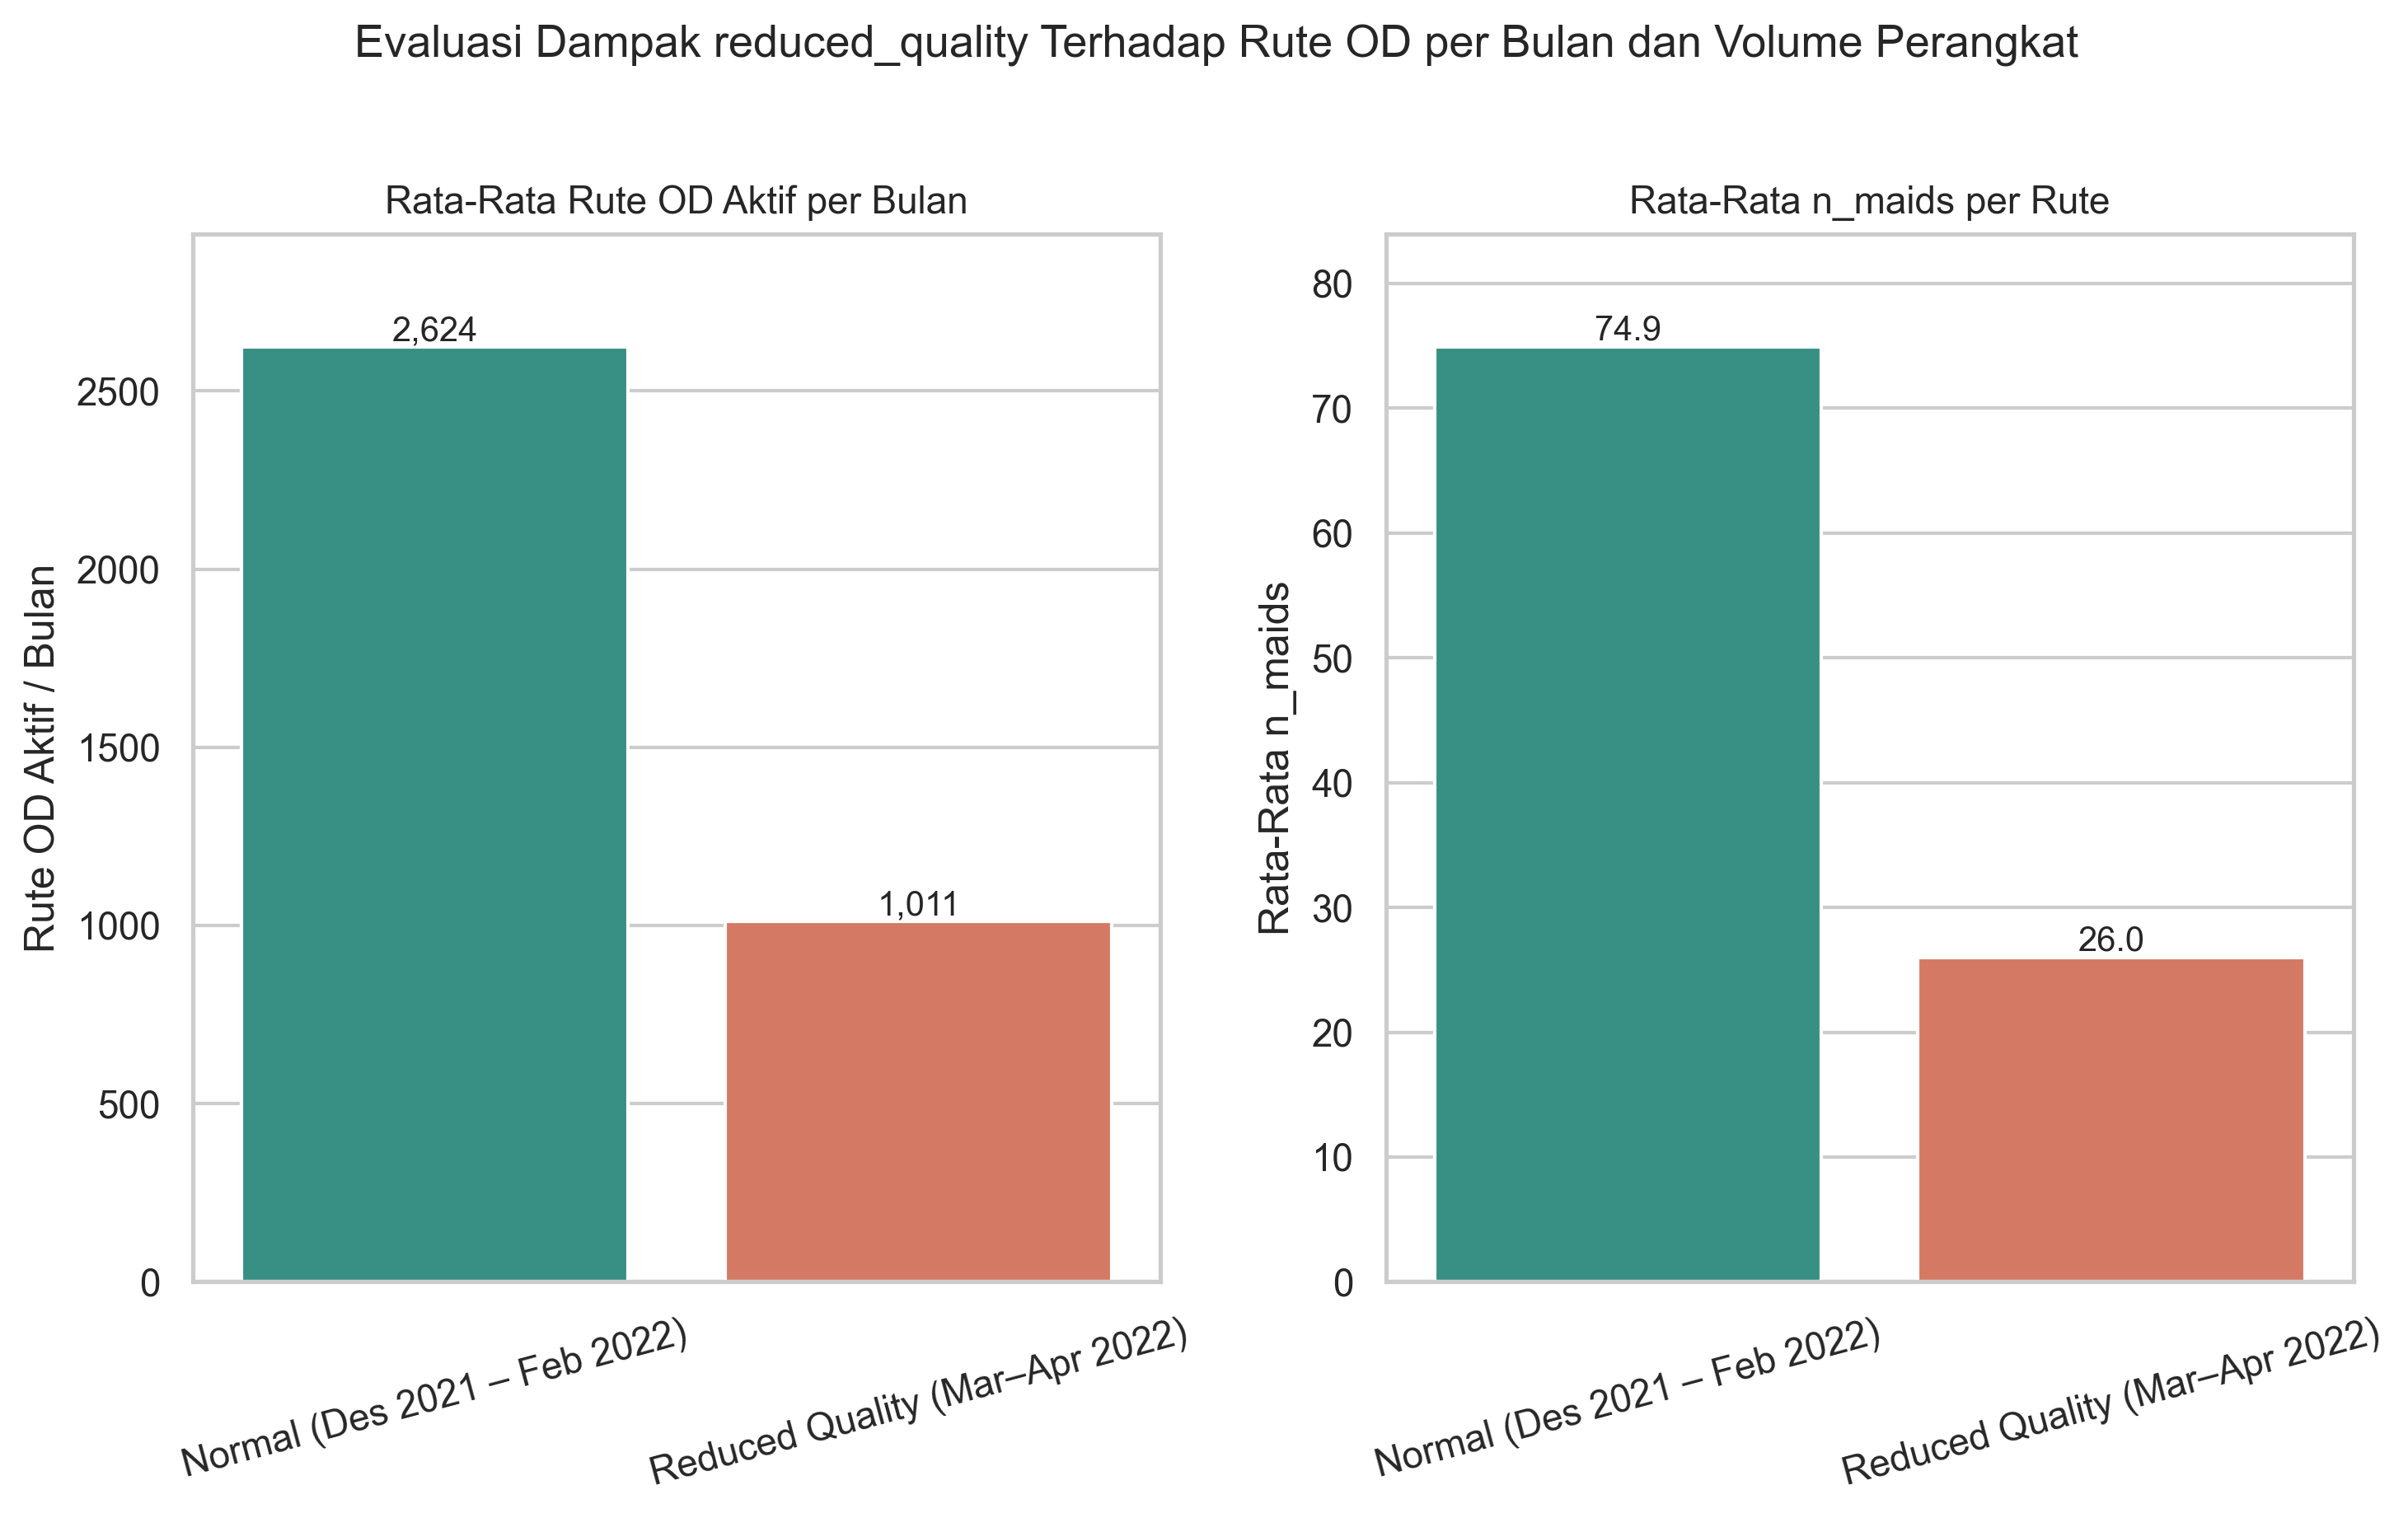

In [20]:
df_od["status_kualitas"] = np.where(
    df_od["reduced_quality"].astype(str).str.lower() == "true",
    "Reduced Quality (Mar–Apr 2022)",
    "Normal (Des 2021 – Feb 2022)",
)

quality_summary = (
    df_od.groupby("status_kualitas")
    .agg(
        total_rute_od=("n_maids", "count"),
        jumlah_bulan=("month", "nunique"),
        rata_rata_maids=("n_maids", "mean"),
    )
    .reset_index()
)
quality_summary["rute_aktif_per_bulan"] = (
    quality_summary["total_rute_od"] / quality_summary["jumlah_bulan"]
)
print(quality_summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 6), dpi=300)
sns.barplot(
    data=quality_summary,
    x="status_kualitas",
    y="rute_aktif_per_bulan",
    hue="status_kualitas",
    palette=["#2a9d8f", "#e76f51"],
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Rata-Rata Rute OD Aktif per Bulan", fontsize=11)
axes[0].set_xlabel("")
axes[0].set_ylabel("Rute OD Aktif / Bulan")
axes[0].set_ylim(0, quality_summary["rute_aktif_per_bulan"].max() * 1.12)
axes[0].tick_params(axis="x", rotation=15)
for bar in axes[0].patches:
    axes[0].annotate(
        f"{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
    )

sns.barplot(
    data=quality_summary,
    x="status_kualitas",
    y="rata_rata_maids",
    hue="status_kualitas",
    palette=["#2a9d8f", "#e76f51"],
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Rata-Rata n_maids per Rute", fontsize=11)
axes[1].set_xlabel("")
axes[1].set_ylabel("Rata-Rata n_maids")
axes[1].set_ylim(0, quality_summary["rata_rata_maids"].max() * 1.12)
axes[1].tick_params(axis="x", rotation=15)
for bar in axes[1].patches:
    axes[1].annotate(
        f"{bar.get_height():.1f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
    )

fig.suptitle("Evaluasi Dampak reduced_quality Terhadap Rute OD per Bulan dan Volume Perangkat", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("figures/08b_evaluasi_reduced_quality.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 8:**
- Setelah menormalisasi durasi periode (3 bulan normal vs 2 bulan *reduced quality*), rata-rata jumlah rute OD aktif turun sebesar **61,5%** dari **`2.624` rute/bulan** (Des 2021 – Feb 2022) menjadi **`1.011` rute/bulan** (Mar–Apr 2022).
- Di saat yang sama, rata-rata volume perangkat per rute aktif menyusut **65,3%** dari **`74,9` MAIDs/rute** menjadi **`26,0` MAIDs/rute**. Oleh karena itu, perbandingan longitudinal atau pemeringkatan koridor lintas bulan harus selalu mempertimbangkan flag `reduced_quality`.